In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving Dataset_verifikasi_skripsi.csv to Dataset_verifikasi_skripsi.csv


# **SINGLE STAGE**

**Load Dataset**

In [ ]:
df = pd.read_csv("Dataset_verifikasi_skripsi.csv")

**Exploratory Data Analysis**

In [ ]:
#baris dan kolom
df.shape

(1200, 3)

In [ ]:
df.head(5)

,label,judul,narasi
0,1,Instruksi Gubernur Jateng tentang penilangan ...,Yth.Seluruh Anggota Grup Sesuai Instruksi Gube...
1,1,Foto Jim Rohn: Jokowi adalah presiden terbaik ...,Jokowi adalah presiden terbaik dlm sejarah ban...
2,1,"ini bukan politik, tapi kenyataan Pak Jokowi b...","Maaf Mas2 dan Mbak2, ini bukan politik, tapi k..."
3,1,event promo smartphone JNE 2020 spesial di bul...,"selamat siang teman teman fb ku semuanya🤩,cuma..."
4,1,Foto Presiden Italia menangis karena tak cukup...,Italia punya fasilitas perawatan kesehatan ter...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   1200 non-null   int64 
 1   judul   1200 non-null   object
 2   narasi  1200 non-null   object
dtypes: int64(1), object(2)
memory usage: 28.3+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

**Missing Value**

In [ ]:
df.isnull().sum()

,0
label,0
judul,0
narasi,0


**Distribusi label**

In [ ]:
df['label'].value_counts()

,count
label,
1,1082
0,118


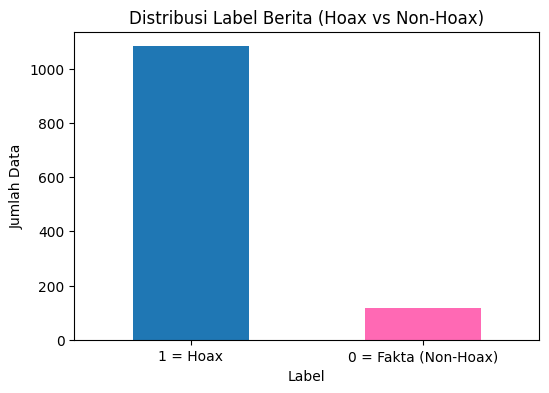

In [ ]:
colors = ['#1f77b4', '#ff69b4']
plt.figure(figsize=(6,4))
ax = df['label'].value_counts().plot(kind='bar', color=colors)
plt.title('Distribusi Label Berita (Hoax vs Non-Hoax)')
plt.xlabel('Label')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
# Tambahkan keterangan di bawah sumbu x
labels = df['label'].value_counts().index.tolist()
# Jika 0 = fakta (non-hoax), 1 = hoax, sesuaikan dengan data kamu
label_desc = {0: 'Fakta (Non-Hoax)', 1: 'Hoax'}
new_labels = [f"{lbl} = {label_desc.get(lbl, 'Unknown')}" for lbl in labels]
ax.set_xticklabels(new_labels)
plt.show()

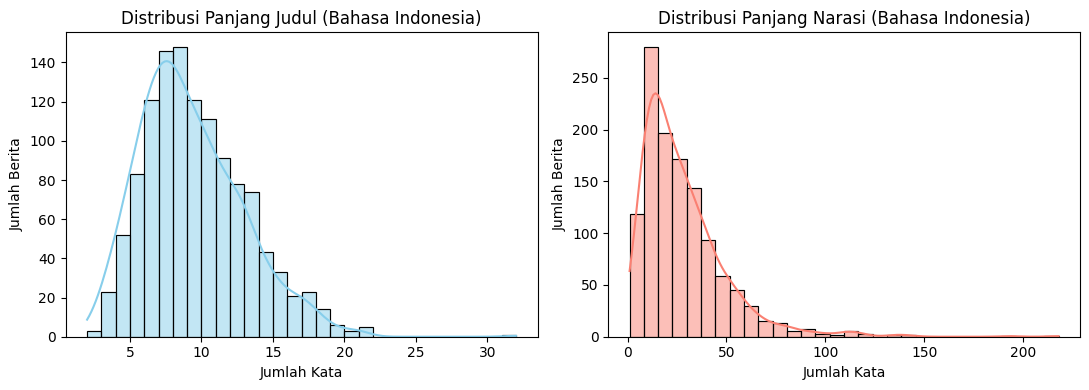

In [ ]:
# Buat folder output
os.makedirs("output", exist_ok=True)

# Hitung jumlah kata judul dan narasi
df['judul_word_count'] = df['judul'].apply(lambda x: len(str(x).split()))
df['narasi_word_count'] = df['narasi'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['judul_word_count'], bins=30, kde=True, color='skyblue')
plt.title("Distribusi Panjang Judul (Bahasa Indonesia)")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Berita")

plt.subplot(1, 2, 2)
sns.histplot(df['narasi_word_count'], bins=30, kde=True, color='salmon')
plt.title("Distribusi Panjang Narasi (Bahasa Indonesia)")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Berita")

plt.tight_layout()
plt.savefig("output/panjang_judul_dan_narasi_bahasa_indonesia.png")
plt.show()

# **Pelabelan Aspek**

In [ ]:
education_keywords = [
    "sekolah", "kampus", "universitas", "guru", "dosen", "mahasiswa",
    "pendidikan", "kurikulum", "beasiswa", "ujian", "belajar",
    "kelas", "murid", "akreditasi", "pelajar", "edukasi", "siswa",
    "paud", "sd", "smp", "sma", "smk", "kuliah", "skripsi", "tesis", "rapat"
]

politics_keywords = [
    "presiden", "wakil", "pemerintah", "politik", "partai", "menteri", "dpr",
    "parlemen", "pilkada", "pemilu", "kampanye", "kabinet", "legislatif",
    "caleg", "birokrat", "kandidat", "pemerintahan", "dewan", "politik uang",
    "koalisi", "oposisi", "peraturan", "undang", "uu", "capres"
]

disaster_keywords = [
    "gempa", "banjir", "longsor", "kebakaran", "tsunami", "letusan", "gunung",
    "evakuasi", "korban", "bencana", "cuaca ekstrem", "topan", "angin",
    "puting beliung", "darurat", "siaga", "banjir bandang", "tanah longsor",
    "gelombang tinggi", "abrasi", "hujan deras"
]

In [ ]:
# salin df asli
df_aspek = df.copy()

# fungsi tentukan aspek per baris (judul + narasi)
def tentukan_aspek(row):
    teks = (str(row["judul"]) + " " + str(row["narasi"])).lower()

    if any(kata in teks for kata in education_keywords):
        return "Pendidikan"
    elif any(kata in teks for kata in politics_keywords):
        return "Politik"
    elif any(kata in teks for kata in disaster_keywords):
        return "Bencana"
    else:
        # fallback supaya semua data tetap punya aspek
        return "Pendidikan"

In [ ]:
# terapkan fungsi
df_aspek["Aspek"] = df_aspek.apply(tentukan_aspek, axis=1)

# mapping aspek ke angka
mapping_aspek_num = {
    "Pendidikan": 0,
    "Politik": 1,
    "Bencana": 2
}
df_aspek["Label_Aspek_Numerik"] = df_aspek["Aspek"].map(mapping_aspek_num)

# ambil kolom yang dibutuhkan
df_aspek_bersih = df_aspek[['label','judul','narasi',
                            'Aspek','Label_Aspek_Numerik']].copy()

In [ ]:
def make_label_aspek_hoaks(row):
    status = "Hoaks" if row["label"] == 1 else "NonHoaks"
    return f"{row['Aspek']}_{status}"

df_aspek_bersih["Label_Aspek_Hoaks"] = df_aspek_bersih.apply(make_label_aspek_hoaks, axis=1)

urutan = [
    ("Pendidikan_Hoaks", 1),
    ("Pendidikan_NonHoaks", 2),
    ("Politik_Hoaks", 3),
    ("Politik_NonHoaks", 4),
    ("Bencana_Hoaks", 5),
    ("Bencana_NonHoaks", 6),
]

hasil = []
for label_str, label_num in urutan:
    count = (df_aspek_bersih["Label_Aspek_Hoaks"] == label_str).sum()
    hasil.append([label_str, label_num, count])

tabel_aspek_hoaks = pd.DataFrame(
    hasil,
    columns=["Label_Aspek_Hoaks", "Label_1_6", "Jumlah"]
)

display(tabel_aspek_hoaks)
print("Total:", tabel_aspek_hoaks["Jumlah"].sum())

,Label_Aspek_Hoaks,Label_1_6,Jumlah
0,Pendidikan_Hoaks,1,827
1,Pendidikan_NonHoaks,2,89
2,Politik_Hoaks,3,195
3,Politik_NonHoaks,4,23
4,Bencana_Hoaks,5,60
5,Bencana_NonHoaks,6,6


Total: 1200


# **PREPROCESSING**

**Cleaning Data**

In [ ]:
def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+|www.\S+', '', text)   # hapus URL
    text = re.sub(r'\d+', '', text)               # hapus angka
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)      # hapus karakter non-huruf
    text = re.sub(r'\s+', ' ', text).strip()      # hapus spasi berlebih
    return text

df_aspek_bersih['narasi_clean'] = df_aspek_bersih['narasi'].apply(clean_text)

# Cek hasil 5 data pertama
display(df_aspek_bersih[['narasi', 'narasi_clean']].head())

,narasi,narasi_clean
0,Yth.Seluruh Anggota Grup Sesuai Instruksi Gube...,Yth Seluruh Anggota Grup Sesuai Instruksi Gube...
1,Jokowi adalah presiden terbaik dlm sejarah ban...,Jokowi adalah presiden terbaik dlm sejarah ban...
2,"Maaf Mas2 dan Mbak2, ini bukan politik, tapi k...",Maaf Mas dan Mbak ini bukan politik tapi kenya...
3,"selamat siang teman teman fb ku semuanya🤩,cuma...",selamat siang teman teman fb ku semuanya cuman...
4,Italia punya fasilitas perawatan kesehatan ter...,Italia punya fasilitas perawatan kesehatan ter...


**Case Folding**

In [ ]:
# Mengubah teks menjadi lowercase
df_aspek_bersih['narasi_casefold'] = df_aspek_bersih['narasi_clean'].str.lower()

# Lihat hasil 5 data pertama
display(df_aspek_bersih[['narasi_clean', 'narasi_casefold']].head())

,narasi_clean,narasi_casefold
0,Yth Seluruh Anggota Grup Sesuai Instruksi Gube...,yth seluruh anggota grup sesuai instruksi gube...
1,Jokowi adalah presiden terbaik dlm sejarah ban...,jokowi adalah presiden terbaik dlm sejarah ban...
2,Maaf Mas dan Mbak ini bukan politik tapi kenya...,maaf mas dan mbak ini bukan politik tapi kenya...
3,selamat siang teman teman fb ku semuanya cuman...,selamat siang teman teman fb ku semuanya cuman...
4,Italia punya fasilitas perawatan kesehatan ter...,italia punya fasilitas perawatan kesehatan ter...


**Normalisasi**

In [ ]:
kamus_normalisasi = {
    'gk': 'tidak', 'ga': 'tidak', 'nggak': 'tidak', 'gak': 'tidak', 'tak' : 'tidak',
    'udh': 'sudah', 'sblm': 'sebelum', 'sblumnya': 'sebelumnya',
    'sbg': 'sebagai', 'yg': 'yang', 'klo': 'kalau', 'klu': 'kalau', 'klw': 'kalau',
    'dgn': 'dengan', 'jgn': 'jangan', 'jg': 'juga', 'kmrn': 'kemarin',
    'skrg': 'sekarang', 'skrng': 'sekarang', 'sm': 'sama', 'sdh': 'sudah',
    'dpt': 'dapat', 'biar': 'supaya', 'brp': 'berapa', 'bsk': 'besok',
    'blm': 'belum', 'pdhl': 'padahal', 'pd': 'pada', 'plg': 'pulang',
    'pjg': 'panjang', 'pls': 'tolong', 'plz': 'tolong', 'km': 'kamu',
    'sy': 'saya', 'gua': 'saya', 'gue': 'saya', 'kpn': 'kapan', 'knp': 'kenapa',
    'krn': 'karena', 'tp': 'tapi', 'bkn': 'bukan', 'bgmn': 'bagaimana',
    'spt': 'seperti', 'bwt': 'buat', 'dlm': 'dalam', 'dr': 'dari',
    'cpet': 'cepat', 'd': 'di', 'pake': 'pakai', 'tu': 'itu',
    'bukanya': 'bukan', 'lg': 'lagi', 'tdk': 'tidak'
}

# Fungsi normalisasi string
def normalisasi_teks(teks):
    if isinstance(teks, str):
        tokens = teks.split()
        hasil = [kamus_normalisasi.get(token, token) for token in tokens]
        return " ".join(hasil)
    return ""

# Terapkan normalisasi ke kolom narasi_casefold
df_aspek_bersih['narasi_normalized'] = df_aspek_bersih['narasi_casefold'].apply(normalisasi_teks)

# Lihat hasil
display(df_aspek_bersih[['narasi_casefold', 'narasi_normalized']].head())


,narasi_casefold,narasi_normalized
0,yth seluruh anggota grup sesuai instruksi gube...,yth seluruh anggota grup sesuai instruksi gube...
1,jokowi adalah presiden terbaik dlm sejarah ban...,jokowi adalah presiden terbaik dalam sejarah b...
2,maaf mas dan mbak ini bukan politik tapi kenya...,maaf mas dan mbak ini bukan politik tapi kenya...
3,selamat siang teman teman fb ku semuanya cuman...,selamat siang teman teman fb ku semuanya cuman...
4,italia punya fasilitas perawatan kesehatan ter...,italia punya fasilitas perawatan kesehatan ter...


**Tokenizing**

In [ ]:
# ============================
# TOKENIZING (memecah teks menjadi kata-kata)
# ============================

df_aspek_bersih['narasi_tokens'] = df_aspek_bersih['narasi_normalized'].apply(
    lambda x: x.split() if isinstance(x, str) else []
)

# Lihat hasil 5 data pertama
display(df_aspek_bersih[['narasi_normalized', 'narasi_tokens']].head())

,narasi_normalized,narasi_tokens
0,yth seluruh anggota grup sesuai instruksi gube...,"[yth, seluruh, anggota, grup, sesuai, instruks..."
1,jokowi adalah presiden terbaik dalam sejarah b...,"[jokowi, adalah, presiden, terbaik, dalam, sej..."
2,maaf mas dan mbak ini bukan politik tapi kenya...,"[maaf, mas, dan, mbak, ini, bukan, politik, ta..."
3,selamat siang teman teman fb ku semuanya cuman...,"[selamat, siang, teman, teman, fb, ku, semuany..."
4,italia punya fasilitas perawatan kesehatan ter...,"[italia, punya, fasilitas, perawatan, kesehata..."


**Stopword Removal**

In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.2 MB/s eta 0:00:00


In [ ]:
# =====================================================
# STOPWORD REMOVAL
# =====================================================

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Buat daftar stopword (Bahasa Indonesia)
stop_factory = StopWordRemoverFactory()
stopwords = set(stop_factory.get_stop_words())

# Terapkan stopword removal ke kolom tokens
df_aspek_bersih['narasi_stopword_removed'] = df_aspek_bersih['narasi_tokens'].apply(
    lambda tokens: [word for word in tokens if word not in stopwords]
)

# Lihat hasil
df_aspek_bersih[['narasi_tokens', 'narasi_stopword_removed']].head(5)


,narasi_tokens,narasi_stopword_removed
0,"[yth, seluruh, anggota, grup, sesuai, instruks...","[yth, seluruh, anggota, grup, sesuai, instruks..."
1,"[jokowi, adalah, presiden, terbaik, dalam, sej...","[jokowi, presiden, terbaik, sejarah, bangsa, i..."
2,"[maaf, mas, dan, mbak, ini, bukan, politik, ta...","[maaf, mas, mbak, bukan, politik, kenyataan, p..."
3,"[selamat, siang, teman, teman, fb, ku, semuany...","[selamat, siang, teman, teman, fb, ku, semuany..."
4,"[italia, punya, fasilitas, perawatan, kesehata...","[italia, punya, fasilitas, perawatan, kesehata..."


**Stemming**

In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Buat stemmer Bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Terapkan stemming pada teks yang sudah di-stopword removal
df_aspek_bersih['narasi_stemmed'] = df_aspek_bersih['narasi_stopword_removed'].apply(
    lambda tokens: [stemmer.stem(word) for word in tokens]
)

# Lihat hasil stemming 5 data pertama
df_aspek_bersih[['narasi_stopword_removed', 'narasi_stemmed']].head(5)

,narasi_stopword_removed,narasi_stemmed
0,"[yth, seluruh, anggota, grup, sesuai, instruks...","[yth, seluruh, anggota, grup, sesuai, instruks..."
1,"[jokowi, presiden, terbaik, sejarah, bangsa, i...","[jokowi, presiden, baik, sejarah, bangsa, indo..."
2,"[maaf, mas, mbak, bukan, politik, kenyataan, p...","[maaf, mas, mbak, bukan, politik, nyata, pak, ..."
3,"[selamat, siang, teman, teman, fb, ku, semuany...","[selamat, siang, teman, teman, fb, ku, semua, ..."
4,"[italia, punya, fasilitas, perawatan, kesehata...","[italia, punya, fasilitas, awat, sehat, canggi..."


In [ ]:
from collections import Counter
from collections import defaultdict

print("=== SEMUA KATA + FREKUENSI PER KELAS (SEBELUM FILTER) ===")

# Corrected to use df_aspek_bersih and narasi_stemmed
for class_id, group in df_aspek_bersih.groupby("Label_1_6"):
    print("\n" + "="*70)
    print(f"KELAS {class_id}")
    print("="*70)

    semua_token = []
    for tokens in group["narasi_stemmed"]:
        semua_token.extend(tokens)

    counter = Counter(semua_token)

    # tampilkan SEMUA kata (bukan top-N)
    for kata, freq in counter.most_common():
        print(f"{kata:20s} : {freq}")


=== SEMUA KATA + FREKUENSI PER KELAS (SEBELUM FILTER) ===

KELAS 1
orang                : 142
jadi                 : 140
indonesia            : 108
sebut                : 79
anak                 : 74
semua                : 72
hari                 : 71
nyata                : 64
virus                : 62
buat                 : 61
jokowi               : 60
info                 : 59
laku                 : 59
tinggal              : 58
baru                 : 58
satu                 : 57
jangan               : 57
sama                 : 53
corona               : 50
china                : 49
lalu                 : 48
covid                : 47
tahun                : 47
mau                  : 46
rumah                : 46
hati                 : 45
apa                  : 45
banyak               : 45
sekarang             : 45
pakai                : 44
masuk                : 44
kata                 : 43
mulai                : 43
kerja                : 43
nya                  : 40
bukan               

In [ ]:
from collections import defaultdict

kata_muncul_di_kelas = defaultdict(set)

for class_id, group in df_aspek_bersih.groupby("Label_1_6"):
    semua_token = []
    for tokens in group["narasi_stemmed"]:
        semua_token.extend(tokens)

    for kata in set(semua_token):
        kata_muncul_di_kelas[kata].add(class_id)

print("\n=== KATA YANG MUNCUL DI LEBIH DARI SATU KELAS (AKAN DIHAPUS) ===")
for kata, kelas in kata_muncul_di_kelas.items():
    if len(kelas) > 1:
        print(f"{kata:20s} -> muncul di kelas {sorted(list(kelas))}")



=== KATA YANG MUNCUL DI LEBIH DARI SATU KELAS (AKAN DIHAPUS) ===
cctv                 -> muncul di kelas [1, 3]
organisasi           -> muncul di kelas [1, 3]
burhanudin           -> muncul di kelas [1, 3]
laksana              -> muncul di kelas [1, 3]
abu                  -> muncul di kelas [1, 3]
tolak                -> muncul di kelas [1, 3, 4, 5]
juluk                -> muncul di kelas [1, 3]
pidana               -> muncul di kelas [1, 3]
puasa                -> muncul di kelas [1, 3]
rambu                -> muncul di kelas [1, 2]
tampak               -> muncul di kelas [1, 2, 3]
kriminal             -> muncul di kelas [1, 2]
lahir                -> muncul di kelas [1, 3]
kabar                -> muncul di kelas [1, 2, 3, 5]
sekitar              -> muncul di kelas [1, 3, 5]
jelas                -> muncul di kelas [1, 2, 3]
perhati              -> muncul di kelas [1, 3, 5]
said                 -> muncul di kelas [1, 3]
tempo                -> muncul di kelas [1, 3]
makar            

In [ ]:
print("\n=== KATA UNIK PER KELAS (SETELAH FILTER) ===")

for class_id, group in df_aspek_bersih.groupby("Label_1_6"):
    print("\n" + "="*70)
    print(f"KELAS {class_id} (KATA UNIK)")
    print("="*70)

    semua_token = []
    for tokens in group["narasi_stemmed"]:
        semua_token.extend(tokens)

    counter = Counter(semua_token)

    for kata, freq in counter.most_common():
        if len(kata_muncul_di_kelas[kata]) == 1:
            print(f"{kata:20s} : {freq}")



=== KATA UNIK PER KELAS (SETELAH FILTER) ===

KELAS 1 (KATA UNIK)
s                    : 15
sapi                 : 12
wa                   : 11
detik                : 11
pasar                : 11
masing               : 11
babi                 : 11
sedia                : 10
tilang               : 10
temen                : 10
tsb                  : 10
tunggu               : 10
hadiah               : 10
gereja               : 10
ku                   : 9
sana                 : 9
ayo                  : 9
kapal                : 8
permen               : 8
jkt                  : 8
dar                  : 8
mbah                 : 8
tumbuh               : 8
g                    : 8
usia                 : 8
hotel                : 8
sampe                : 7
angkot               : 7
grab                 : 7
perut                : 7
sma                  : 7
perang               : 7
konsumsi             : 7
kartu                : 7
ketemu               : 7
latih                : 7
syarat             

In [ ]:
from collections import Counter, defaultdict

# ==========================================
# A) HITUNG KATA LINTAS KELAS (>= 2 kelas)
# ==========================================
kata_muncul_di_kelas = defaultdict(set)

for class_id, group in df_aspek_bersih.groupby("Label_1_6"):
    semua_token = []
    for tokens in group["narasi_stemmed"]:
        semua_token.extend(tokens)
    for kata in set(semua_token):
        kata_muncul_di_kelas[kata].add(class_id)

kata_lintas_kelas = {k for k, v in kata_muncul_di_kelas.items() if len(v) > 1}

print("=== RINGKASAN FILTER KATA (LINTAS KELAS) ===")
print("Jumlah kata lintas kelas (akan dihapus):", len(kata_lintas_kelas))

# ==========================================
# B) JUMLAH GLOBAL SEBELUM FILTER
# ==========================================
semua_token_global = []
for tokens in df_aspek_bersih["narasi_stemmed"]:
    semua_token_global.extend(tokens)

counter_global_sebelum = Counter(semua_token_global)

print("\n=== JUMLAH GLOBAL SEBELUM FILTER ===")
print("Total token (kemunculan kata):", sum(counter_global_sebelum.values()))
print("Jumlah kata unik (vocab):     ", len(counter_global_sebelum))

# ==========================================
# C) BUAT TOKEN SETELAH FILTER (INI WAJIB)
# ==========================================
df_aspek_bersih["narasi_stemmed_filtered"] = df_aspek_bersih["narasi_stemmed"].apply(
    lambda toks: [t for t in toks if t not in kata_lintas_kelas]
)

# ==========================================
# D) JUMLAH GLOBAL SETELAH FILTER
# ==========================================
semua_token_global_after = []
for tokens in df_aspek_bersih["narasi_stemmed_filtered"]:
    semua_token_global_after.extend(tokens)

counter_global_sesudah = Counter(semua_token_global_after)

print("\n=== JUMLAH GLOBAL SETELAH FILTER ===")
print("Total token (kemunculan kata):", sum(counter_global_sesudah.values()))
print("Jumlah kata unik (vocab):     ", len(counter_global_sesudah))


=== RINGKASAN FILTER KATA (LINTAS KELAS) ===
Jumlah kata lintas kelas (akan dihapus): 1794

=== JUMLAH GLOBAL SEBELUM FILTER ===
Total token (kemunculan kata): 25275
Jumlah kata unik (vocab):      6275

=== JUMLAH GLOBAL SETELAH FILTER ===
Total token (kemunculan kata): 6385
Jumlah kata unik (vocab):      4481


# **EKSTRAKSI FITUR BAG OF WORDS**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# ==========================================
# 1) List token -> string (pakai hasil filter)
# ==========================================
def join_tokens(tokens):
    return " ".join(tokens) if isinstance(tokens, list) else ""

df_aspek_bersih["text_bow"] = df_aspek_bersih["narasi_stemmed_filtered"].apply(join_tokens)

# (opsional tapi aman) buang dokumen kosong setelah filter
df_bow = df_aspek_bersih[df_aspek_bersih["text_bow"].str.strip().astype(bool)].copy()
print("\nJumlah dokumen setelah buang teks kosong:", df_bow.shape[0])

# ==========================================
# 2) CountVectorizer
# ==========================================
vectorizer = CountVectorizer(
    analyzer="word",
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b"
)

# ==========================================
# 3) Fit-transform BoW
# ==========================================
X_bow_sparse = vectorizer.fit_transform(df_bow["text_bow"])
print("Shape X_bow (sparse):", X_bow_sparse.shape)

vocab = vectorizer.get_feature_names_out()
print("Jumlah kata unik (BoW):", len(vocab))

# contoh 10 fitur pertama
df_bow_subset = pd.DataFrame(X_bow_sparse[:, :10].toarray(), columns=vocab[:10])
display(df_bow_subset.head())

# ==========================================
# 4) Ke array (untuk SMOTE)
# ==========================================
X_bow_lib = X_bow_sparse.toarray()
print("Shape X_bow (array):", X_bow_lib.shape)

# ✅ label harus ikut df_bow yang sudah dibuang kosong
y_6class = df_bow["Label_1_6"].values



Jumlah dokumen setelah buang teks kosong: 1105
Shape X_bow (sparse): (1105, 4481)
Jumlah kata unik (BoW): 4481


,aamin,abang,abar,abdu,abdulaziz,abdullah,abdurrahman,abidin,abis,aborsi
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


Shape X_bow (array): (1105, 4481)


In [ ]:
# =========================
# LABEL (PAKAI df_bow)
# =========================
y_6class = df_bow["Label_1_6"].values

print("\n=== DISTRIBUSI KELAS SEBELUM SMOTE (DATA SETELAH FILTER & BUANG KOSONG) ===")
print(df_bow["Label_1_6"].value_counts().sort_index())



=== DISTRIBUSI KELAS SEBELUM SMOTE (DATA SETELAH FILTER & BUANG KOSONG) ===
Label_1_6
1    783
2     71
3    172
4     19
5     55
6      5
Name: count, dtype: int64


In [ ]:
id_to_name = {
    1: "Pendidikan_Hoaks",
    2: "Pendidikan_NonHoaks",
    3: "Politik_Hoaks",
    4: "Politik_NonHoaks",
    5: "Bencana_Hoaks",
    6: "Bencana_NonHoaks"
}


# **SPLIT DATA 80:20**

In [ ]:
from sklearn.model_selection import train_test_split

X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_bow_lib,
    y_6class,
    test_size=0.2,
    random_state=42,
    stratify=y_6class
)

print("\nData Train (sebelum SMOTE):", X_train_single.shape, y_train_single.shape)
print("Data Test  (tanpa SMOTE)   :", X_test_single.shape,  y_test_single.shape)



Data Train (sebelum SMOTE): (884, 4481) (884,)
Data Test  (tanpa SMOTE)   : (221, 4481) (221,)


# **SMOTE**

In [ ]:
from imblearn.over_sampling import SMOTE
import pandas as pd

# cek jumlah minimum kelas di train
min_count = pd.Series(y_train_single).value_counts().min()

# k_neighbors harus < min_count
k_neighbors = min(4, max(1, min_count - 1))
print("k_neighbors dipakai:", k_neighbors)

smote_single = SMOTE(random_state=42, k_neighbors=k_neighbors)
X_train_single_smote, y_train_single_smote = smote_single.fit_resample(
    X_train_single, y_train_single
)

print("\n=== DISTRIBUSI KELAS SETELAH SMOTE (TRAIN SAJA) ===")
after_single = (
    pd.Series(y_train_single_smote)
      .value_counts()
      .sort_index()
      .reset_index()
)
after_single.columns = ["Kelas", "Jumlah_Data"]
after_single["Keterangan"] = after_single["Kelas"].map(id_to_name)
display(after_single)

print("\nData Train (SETELAH SMOTE):", X_train_single_smote.shape, y_train_single_smote.shape)
print("Data Test  (TETAP ASLI)   :", X_test_single.shape,        y_test_single.shape)

print("\n=== DISTRIBUSI TEST SET (TANPA SMOTE) ===")
test_df = pd.Series(y_test_single).value_counts().sort_index().reset_index()
test_df.columns = ["Kelas", "Jumlah_Test"]
test_df["Nama_Kelas"] = test_df["Kelas"].map(id_to_name)
display(test_df)


k_neighbors dipakai: 3

=== DISTRIBUSI KELAS SETELAH SMOTE (TRAIN SAJA) ===


,Kelas,Jumlah_Data,Keterangan
0,1,626,Pendidikan_Hoaks
1,2,626,Pendidikan_NonHoaks
2,3,626,Politik_Hoaks
3,4,626,Politik_NonHoaks
4,5,626,Bencana_Hoaks
5,6,626,Bencana_NonHoaks



Data Train (SETELAH SMOTE): (3756, 4481) (3756,)
Data Test  (TETAP ASLI)   : (221, 4481) (221,)

=== DISTRIBUSI TEST SET (TANPA SMOTE) ===


,Kelas,Jumlah_Test,Nama_Kelas
0,1,157,Pendidikan_Hoaks
1,2,14,Pendidikan_NonHoaks
2,3,34,Politik_Hoaks
3,4,4,Politik_NonHoaks
4,5,11,Bencana_Hoaks
5,6,1,Bencana_NonHoaks


# **ALGORITMA RANDOM FOREST**

# **HYPERPARAMETER 100-30**


Akurasi TRAIN Single-Stage SMOTE : 43.69%
Akurasi TEST  Single-Stage SMOTE : 40.27%


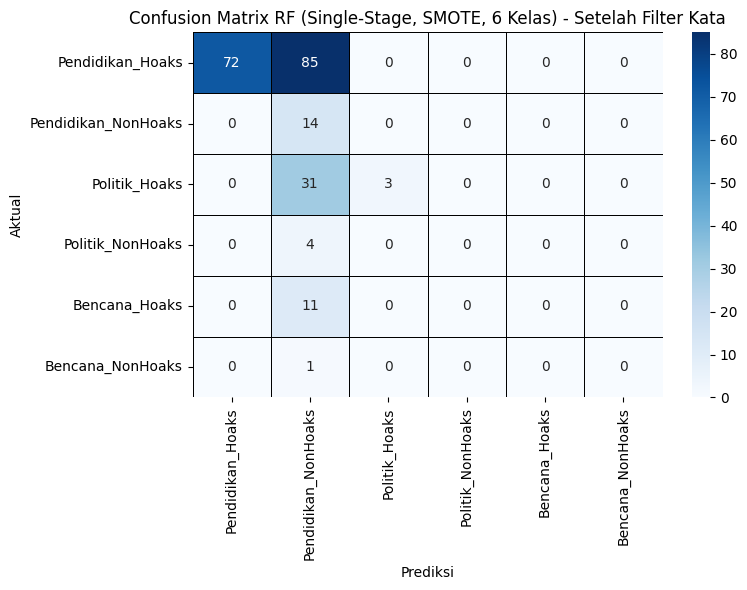


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     1.0000    0.4586    0.6288       157
Pendidikan_NonHoaks     0.0959    1.0000    0.1750        14
      Politik_Hoaks     1.0000    0.0882    0.1622        34
   Politik_NonHoaks     0.0000    0.0000    0.0000         4
      Bencana_Hoaks     0.0000    0.0000    0.0000        11
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.4027       221
          macro avg     0.3493    0.2578    0.1610       221
       weighted avg     0.8703    0.4027    0.4828       221



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


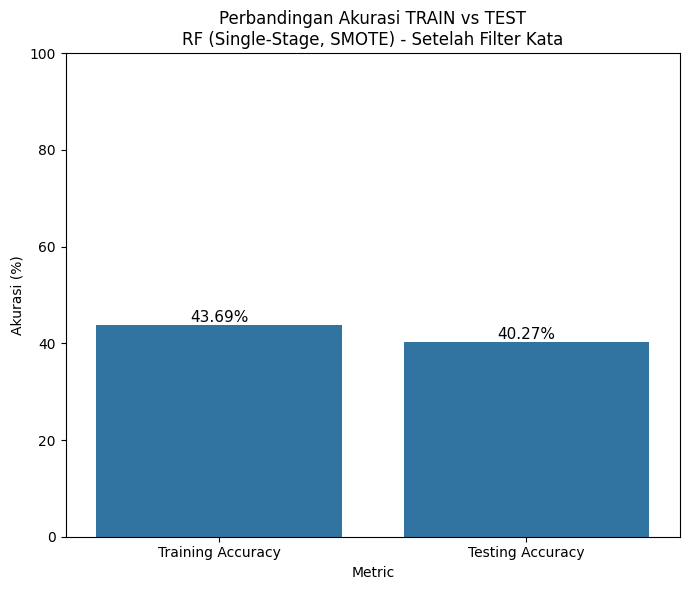

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rf_single_6class_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = [1,2,3,4,5,6]
label_names_6 = [id_to_name[i] for i in label_order_6]

cm_single_df = pd.DataFrame(cm_single, index=label_names_6, columns=label_names_6)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues", linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas) - Setelah Filter Kata")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# grafik akurasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]
})

plt.figure(figsize=(7, 6))
ax = sns.barplot(x='Metric', y='Accuracy', data=df_accuracy)
plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRF (Single-Stage, SMOTE) - Setelah Filter Kata')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 50-10**


Akurasi TRAIN Single-Stage SMOTE : 39.48%
Akurasi TEST  Single-Stage SMOTE : 47.06%


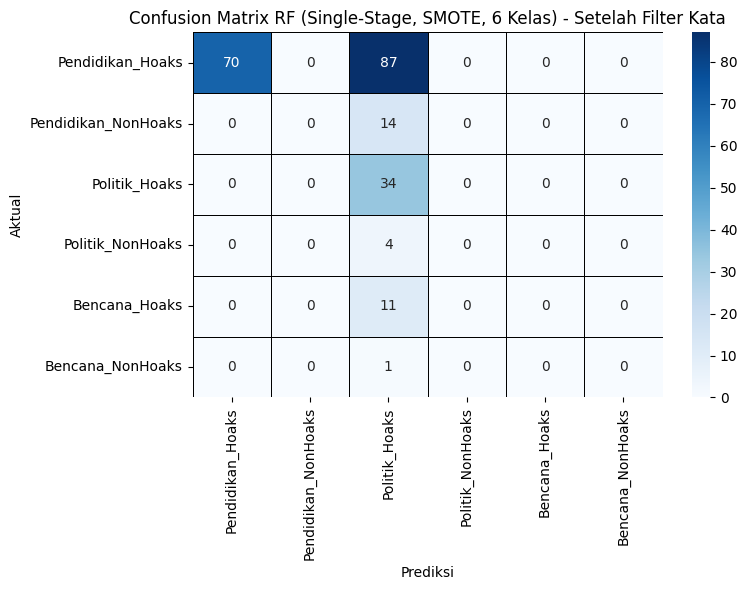


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     1.0000    0.4459    0.6167       157
Pendidikan_NonHoaks     0.0000    0.0000    0.0000        14
      Politik_Hoaks     0.2252    1.0000    0.3676        34
   Politik_NonHoaks     0.0000    0.0000    0.0000         4
      Bencana_Hoaks     0.0000    0.0000    0.0000        11
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.4706       221
          macro avg     0.2042    0.2410    0.1641       221
       weighted avg     0.7450    0.4706    0.4947       221



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


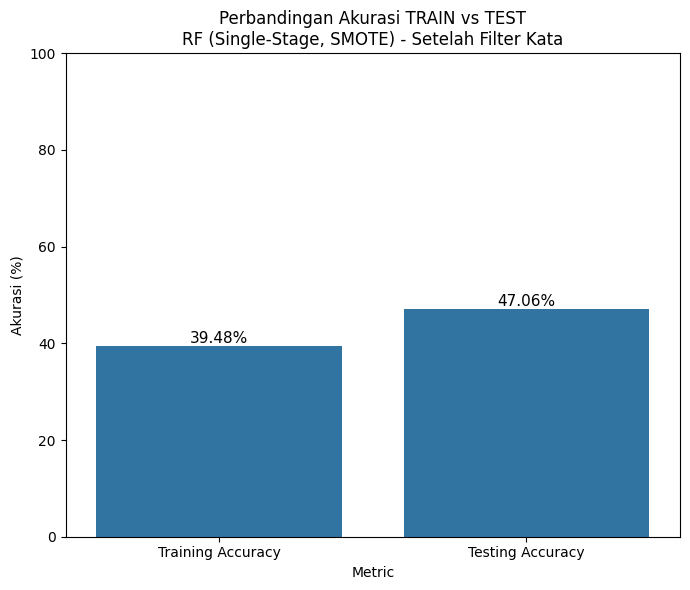

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rf_single_6class_smote = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = [1,2,3,4,5,6]
label_names_6 = [id_to_name[i] for i in label_order_6]

cm_single_df = pd.DataFrame(cm_single, index=label_names_6, columns=label_names_6)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues", linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas) - Setelah Filter Kata")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# grafik akurasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]
})

plt.figure(figsize=(7, 6))
ax = sns.barplot(x='Metric', y='Accuracy', data=df_accuracy)
plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRF (Single-Stage, SMOTE) - Setelah Filter Kata')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 60-20**


Akurasi TRAIN Single-Stage SMOTE : 43.13%
Akurasi TEST  Single-Stage SMOTE : 42.53%


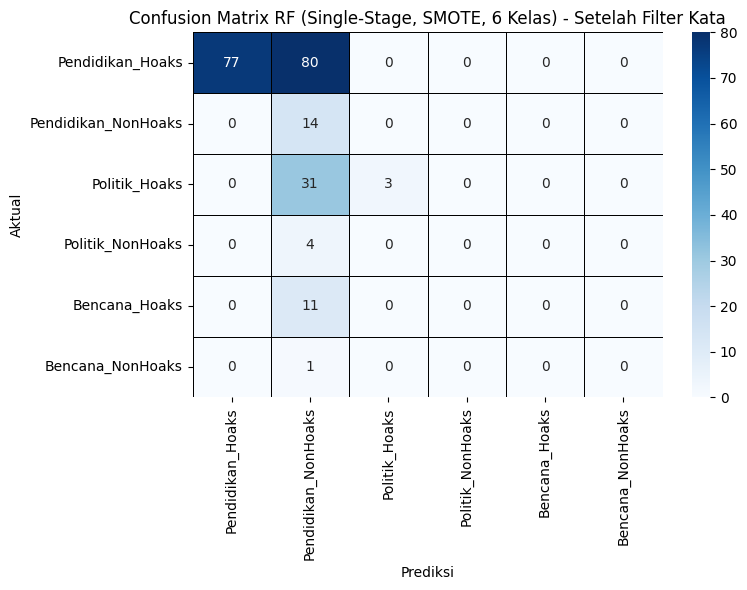


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     1.0000    0.4904    0.6581       157
Pendidikan_NonHoaks     0.0993    1.0000    0.1806        14
      Politik_Hoaks     1.0000    0.0882    0.1622        34
   Politik_NonHoaks     0.0000    0.0000    0.0000         4
      Bencana_Hoaks     0.0000    0.0000    0.0000        11
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.4253       221
          macro avg     0.3499    0.2631    0.1668       221
       weighted avg     0.8705    0.4253    0.5039       221



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


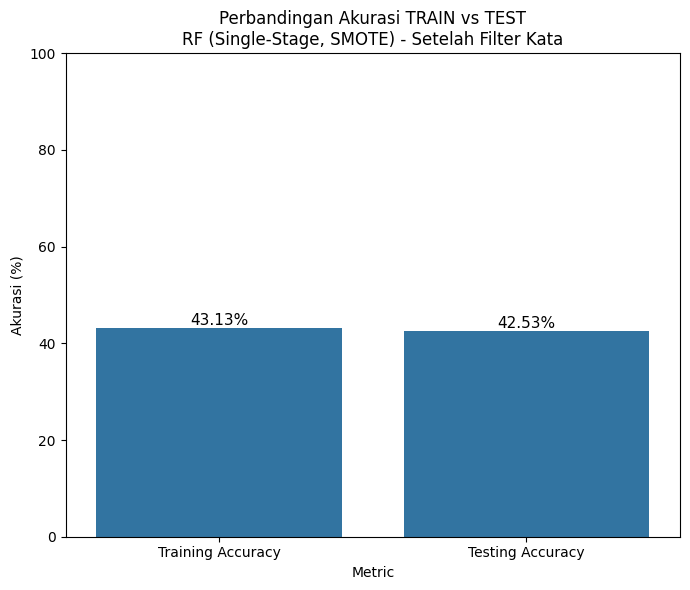

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rf_single_6class_smote = RandomForestClassifier(
    n_estimators=60,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = [1,2,3,4,5,6]
label_names_6 = [id_to_name[i] for i in label_order_6]

cm_single_df = pd.DataFrame(cm_single, index=label_names_6, columns=label_names_6)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues", linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas) - Setelah Filter Kata")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# grafik akurasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]
})

plt.figure(figsize=(7, 6))
ax = sns.barplot(x='Metric', y='Accuracy', data=df_accuracy)
plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRF (Single-Stage, SMOTE) - Setelah Filter Kata')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 70-30**


Akurasi TRAIN Single-Stage SMOTE : 59.92%
Akurasi TEST  Single-Stage SMOTE : 59.17%


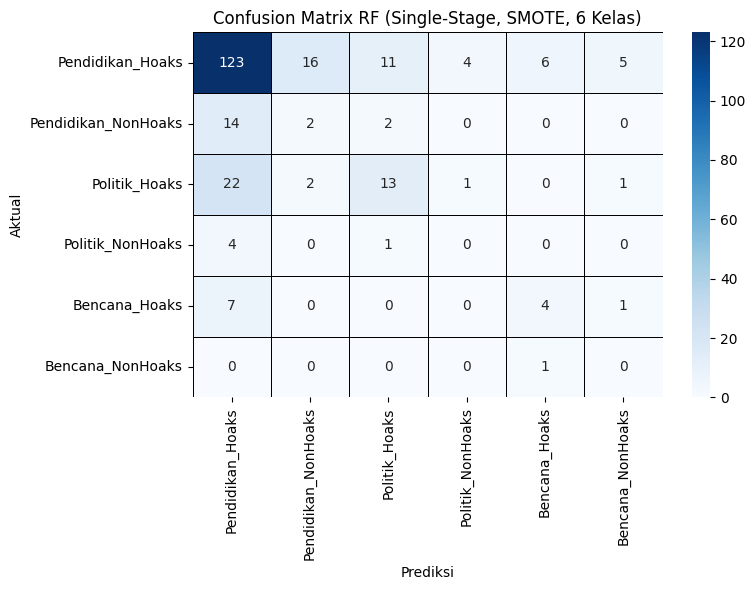


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     0.7235    0.7455    0.7343       165
Pendidikan_NonHoaks     0.1000    0.1111    0.1053        18
      Politik_Hoaks     0.4815    0.3333    0.3939        39
   Politik_NonHoaks     0.0000    0.0000    0.0000         5
      Bencana_Hoaks     0.3636    0.3333    0.3478        12
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.5917       240
          macro avg     0.2781    0.2539    0.2636       240
       weighted avg     0.6013    0.5917    0.5942       240



/tmp/ipython-input-722037277.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


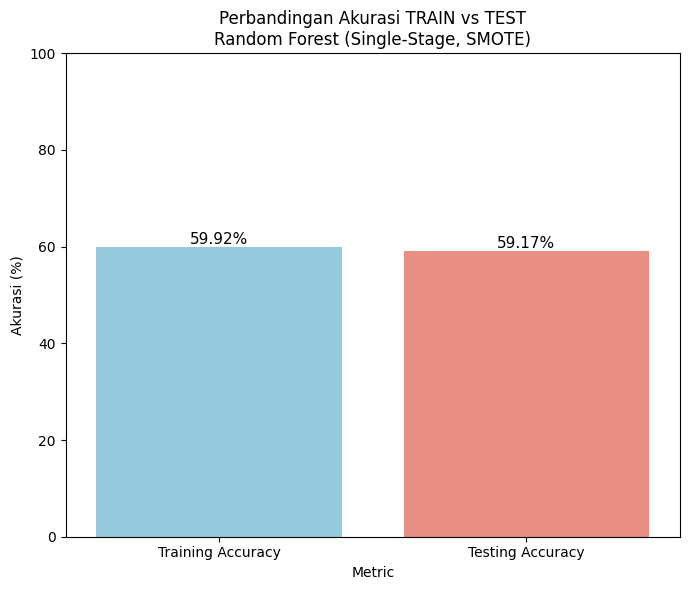

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ==============================================
# 1) Inisialisasi model Random Forest (Single-Stage, SMOTE)
# ==============================================
rf_single_6class_smote = RandomForestClassifier(
    n_estimators=70,
    max_depth=30,
    max_features='sqrt',   # ✅ ganti: otomatis akar(jumlah fitur)
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# ==============================================
# 2) LATIH MODEL DI DATA TRAIN HASIL SMOTE
#    (bukan lagi X_train_single, y_train_single)
# ==============================================
rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

# Prediksi
# Jika ingin akurasi train → pakai data train SMOTE
y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)

# Data test tetap ASLI (tanpa SMOTE) → ini sudah benar
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

# =====================================================
# 7. Evaluasi Akurasi
# =====================================================

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

# =====================================================
# 8. Confusion Matrix & Classification Report
# =====================================================

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = list(mapping_6kelas.values())
label_names_6 = [k for k, v in sorted(mapping_6kelas.items(), key=lambda item: item[1])]

cm_single_df = pd.DataFrame(
    cm_single,
    index=label_names_6,
    columns=label_names_6
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# =====================================================
# 9. Grafik Perbandingan Akurasi TRAIN vs TEST
# =====================================================

# Buat dataframe untuk visualisasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]  # dalam persen
})

# Plot barplot
plt.figure(figsize=(7, 6))
ax = sns.barplot(
    x='Metric',
    y='Accuracy',
    data=df_accuracy,
    palette=['skyblue', 'salmon']
)

plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRandom Forest (Single-Stage, SMOTE)')

# Tambahkan nilai akurasi di atas bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 80-30**


Akurasi TRAIN Single-Stage SMOTE : 44.20%
Akurasi TEST  Single-Stage SMOTE : 42.99%


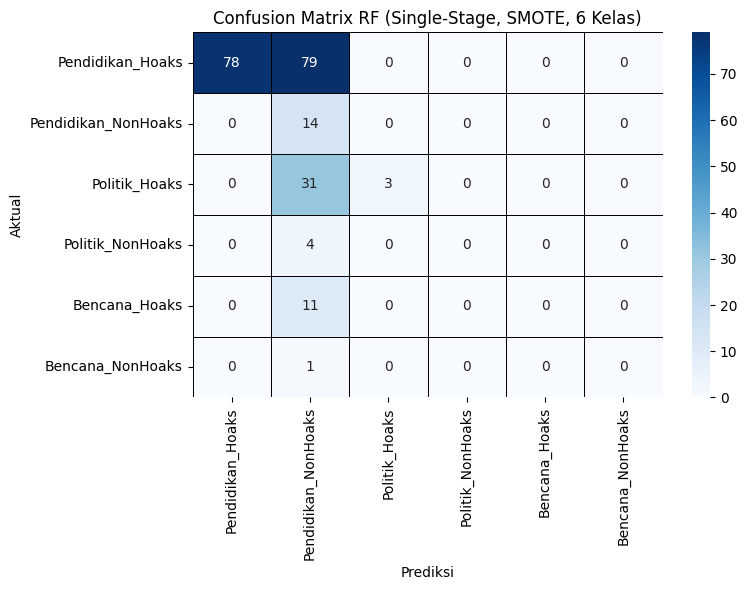


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     1.0000    0.4968    0.6638       157
Pendidikan_NonHoaks     0.1000    1.0000    0.1818        14
      Politik_Hoaks     1.0000    0.0882    0.1622        34
   Politik_NonHoaks     0.0000    0.0000    0.0000         4
      Bencana_Hoaks     0.0000    0.0000    0.0000        11
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.4299       221
          macro avg     0.3500    0.2642    0.1680       221
       weighted avg     0.8706    0.4299    0.5081       221



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/tmp/ipython-input-3605125942.py:88: FutureWarnin

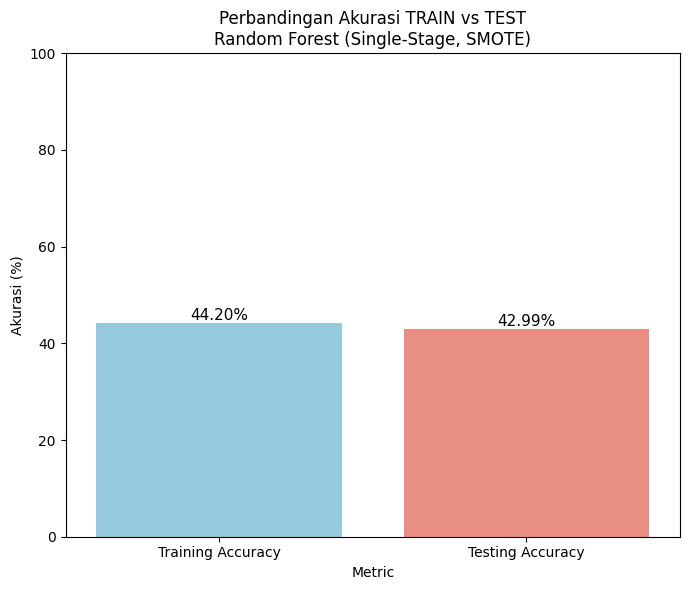

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ==============================================
# 1) Inisialisasi model Random Forest (Single-Stage, SMOTE)
# ==============================================
rf_single_6class_smote = RandomForestClassifier(
    n_estimators=80,
    max_depth=30,
    max_features='sqrt',   # ✅ ganti: otomatis akar(jumlah fitur)
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# ==============================================
# 2) LATIH MODEL DI DATA TRAIN HASIL SMOTE
#    (bukan lagi X_train_single, y_train_single)
# ==============================================
rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

# Prediksi
# Jika ingin akurasi train → pakai data train SMOTE
y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)

# Data test tetap ASLI (tanpa SMOTE) → ini sudah benar
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

# =====================================================
# 7. Evaluasi Akurasi
# =====================================================

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

# =====================================================
# 8. Confusion Matrix & Classification Report
# =====================================================

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = list(mapping_6kelas.values())
label_names_6 = [k for k, v in sorted(mapping_6kelas.items(), key=lambda item: item[1])]

cm_single_df = pd.DataFrame(
    cm_single,
    index=label_names_6,
    columns=label_names_6
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# =====================================================
# 9. Grafik Perbandingan Akurasi TRAIN vs TEST
# =====================================================

# Buat dataframe untuk visualisasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]  # dalam persen
})

# Plot barplot
plt.figure(figsize=(7, 6))
ax = sns.barplot(
    x='Metric',
    y='Accuracy',
    data=df_accuracy,
    palette=['skyblue', 'salmon']
)

plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRandom Forest (Single-Stage, SMOTE)')

# Tambahkan nilai akurasi di atas bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 90-20**


Akurasi TRAIN Single-Stage SMOTE : 59.16%
Akurasi TEST  Single-Stage SMOTE : 57.92%


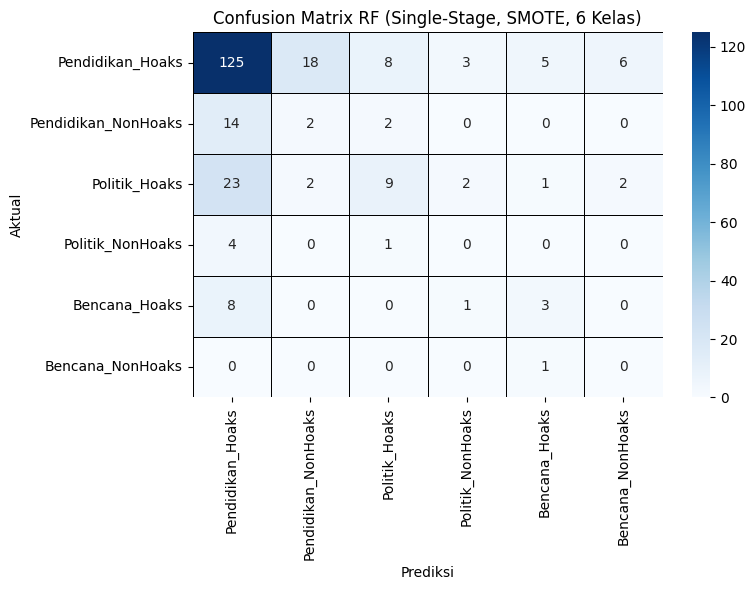


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     0.7184    0.7576    0.7375       165
Pendidikan_NonHoaks     0.0909    0.1111    0.1000        18
      Politik_Hoaks     0.4500    0.2308    0.3051        39
   Politik_NonHoaks     0.0000    0.0000    0.0000         5
      Bencana_Hoaks     0.3000    0.2500    0.2727        12
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.5792       240
          macro avg     0.2599    0.2249    0.2359       240
       weighted avg     0.5888    0.5792    0.5777       240



/tmp/ipython-input-3406166545.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


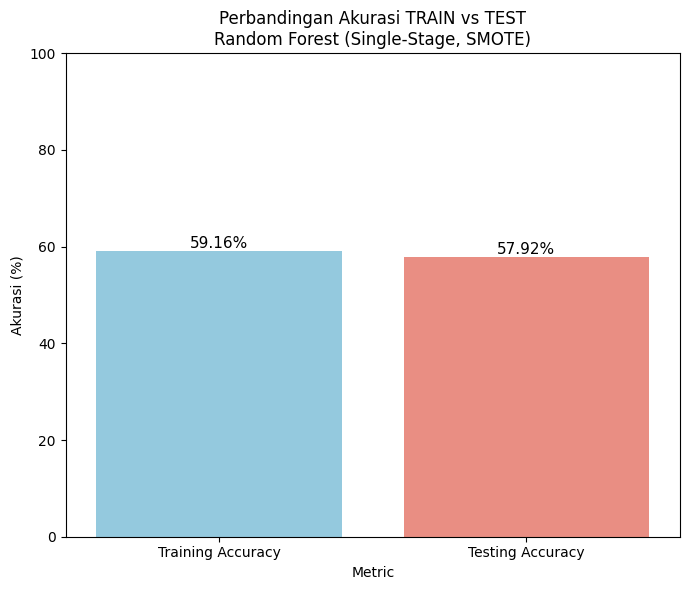

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ==============================================
# 1) Inisialisasi model Random Forest (Single-Stage, SMOTE)
# ==============================================
rf_single_6class_smote = RandomForestClassifier(
    n_estimators=70,
    max_depth=30,
    max_features='sqrt',   # ✅ ganti: otomatis akar(jumlah fitur)
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# ==============================================
# 2) LATIH MODEL DI DATA TRAIN HASIL SMOTE
#    (bukan lagi X_train_single, y_train_single)
# ==============================================
rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

# Prediksi
# Jika ingin akurasi train → pakai data train SMOTE
y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)

# Data test tetap ASLI (tanpa SMOTE) → ini sudah benar
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

# =====================================================
# 7. Evaluasi Akurasi
# =====================================================

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

# =====================================================
# 8. Confusion Matrix & Classification Report
# =====================================================

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = list(mapping_6kelas.values())
label_names_6 = [k for k, v in sorted(mapping_6kelas.items(), key=lambda item: item[1])]

cm_single_df = pd.DataFrame(
    cm_single,
    index=label_names_6,
    columns=label_names_6
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# =====================================================
# 9. Grafik Perbandingan Akurasi TRAIN vs TEST
# =====================================================

# Buat dataframe untuk visualisasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]  # dalam persen
})

# Plot barplot
plt.figure(figsize=(7, 6))
ax = sns.barplot(
    x='Metric',
    y='Accuracy',
    data=df_accuracy,
    palette=['skyblue', 'salmon']
)

plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRandom Forest (Single-Stage, SMOTE)')

# Tambahkan nilai akurasi di atas bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11)

plt.tight_layout()
plt.show()


# **HYPERPARAMETER 100-10**


Akurasi TRAIN Single-Stage SMOTE : 58.21%
Akurasi TEST  Single-Stage SMOTE : 56.67%


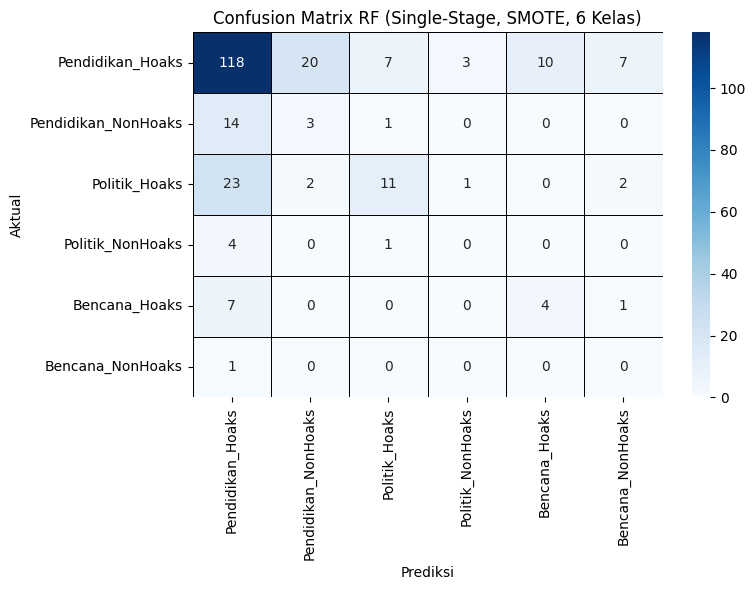


=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===
                     precision    recall  f1-score   support

   Pendidikan_Hoaks     0.7066    0.7152    0.7108       165
Pendidikan_NonHoaks     0.1200    0.1667    0.1395        18
      Politik_Hoaks     0.5500    0.2821    0.3729        39
   Politik_NonHoaks     0.0000    0.0000    0.0000         5
      Bencana_Hoaks     0.2857    0.3333    0.3077        12
   Bencana_NonHoaks     0.0000    0.0000    0.0000         1

           accuracy                         0.5667       240
          macro avg     0.2771    0.2495    0.2552       240
       weighted avg     0.5984    0.5667    0.5751       240



/tmp/ipython-input-2643964221.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


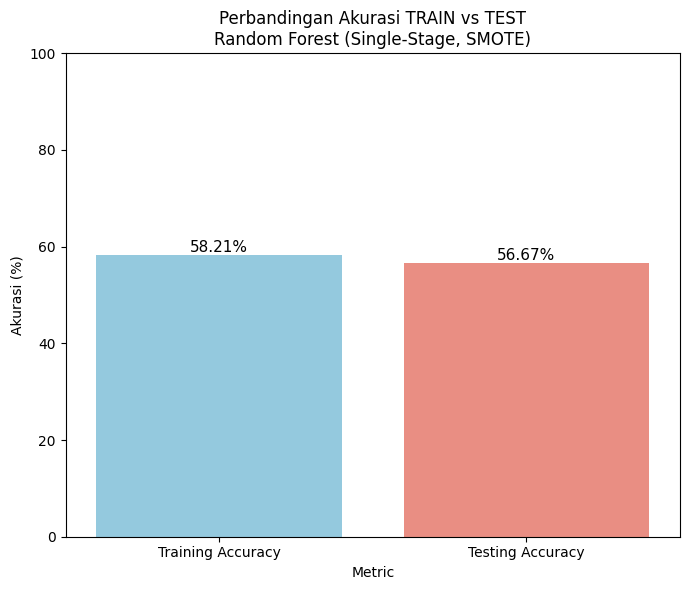

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ==============================================
# 1) Inisialisasi model Random Forest (Single-Stage, SMOTE)
# ==============================================
rf_single_6class_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    max_features='sqrt',   # ✅ ganti: otomatis akar(jumlah fitur)
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# ==============================================
# 2) LATIH MODEL DI DATA TRAIN HASIL SMOTE
#    (bukan lagi X_train_single, y_train_single)
# ==============================================
rf_single_6class_smote.fit(X_train_single_smote, y_train_single_smote)

# Prediksi
# Jika ingin akurasi train → pakai data train SMOTE
y_pred_train_single = rf_single_6class_smote.predict(X_train_single_smote)

# Data test tetap ASLI (tanpa SMOTE) → ini sudah benar
y_pred_test_single  = rf_single_6class_smote.predict(X_test_single)

# =====================================================
# 7. Evaluasi Akurasi
# =====================================================

acc_train_single = accuracy_score(y_train_single_smote, y_pred_train_single)
acc_test_single  = accuracy_score(y_test_single,       y_pred_test_single)

print(f"\nAkurasi TRAIN Single-Stage SMOTE : {acc_train_single*100:.2f}%")
print(f"Akurasi TEST  Single-Stage SMOTE : {acc_test_single*100:.2f}%")

# =====================================================
# 8. Confusion Matrix & Classification Report
# =====================================================

cm_single = confusion_matrix(y_test_single, y_pred_test_single)

label_order_6 = list(mapping_6kelas.values())
label_names_6 = [k for k, v in sorted(mapping_6kelas.items(), key=lambda item: item[1])]

cm_single_df = pd.DataFrame(
    cm_single,
    index=label_names_6,
    columns=label_names_6
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_single_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF (Single-Stage, SMOTE, 6 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (Single-Stage, SMOTE) ===")
print(classification_report(
    y_test_single,
    y_pred_test_single,
    labels=label_order_6,
    target_names=label_names_6,
    digits=4
))

# =====================================================
# 9. Grafik Perbandingan Akurasi TRAIN vs TEST
# =====================================================

# Buat dataframe untuk visualisasi
df_accuracy = pd.DataFrame({
    'Metric': ['Training Accuracy', 'Testing Accuracy'],
    'Accuracy': [acc_train_single * 100, acc_test_single * 100]  # dalam persen
})

# Plot barplot
plt.figure(figsize=(7, 6))
ax = sns.barplot(
    x='Metric',
    y='Accuracy',
    data=df_accuracy,
    palette=['skyblue', 'salmon']
)

plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.xlabel('Metric')
plt.title('Perbandingan Akurasi TRAIN vs TEST\nRandom Forest (Single-Stage, SMOTE)')

# Tambahkan nilai akurasi di atas bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11)

plt.tight_layout()
plt.show()


# **Menampilkan Hasil tiap hyperparameter**

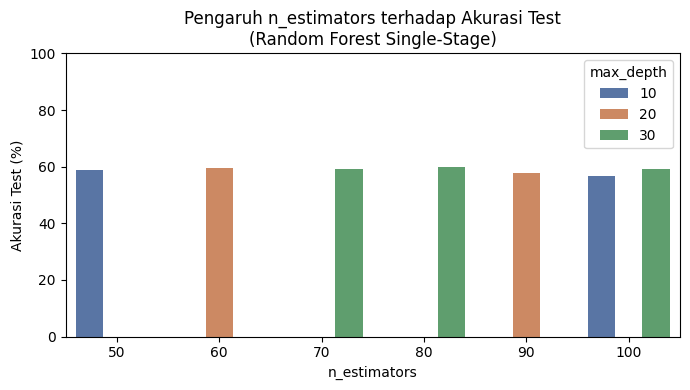

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Manually create df_hyper_single with macro average metrics extracted from previous classification reports
hyper_results_with_macro = [
    {'n_estimators': 100, 'max_depth': 30, 'acc_train': 60.02, 'acc_test': 59.17, 'macro_precision': 0.2830, 'macro_recall': 0.2473, 'macro_f1': 0.2603},
    {'n_estimators': 50, 'max_depth': 10, 'acc_train': 55.97, 'acc_test': 58.75, 'macro_precision': 0.3196, 'macro_recall': 0.2888, 'macro_f1': 0.2973},
    {'n_estimators': 60, 'max_depth': 20, 'acc_train': 59.04, 'acc_test': 59.58, 'macro_precision': 0.2921, 'macro_recall': 0.2647, 'macro_f1': 0.2757},
    {'n_estimators': 70, 'max_depth': 30, 'acc_train': 59.92, 'acc_test': 59.17, 'macro_precision': 0.2781, 'macro_recall': 0.2539, 'macro_f1': 0.2636},
    {'n_estimators': 80, 'max_depth': 30, 'acc_train': 60.15, 'acc_test': 60.00, 'macro_precision': 0.2843, 'macro_recall': 0.2559, 'macro_f1': 0.2672},
    {'n_estimators': 90, 'max_depth': 20, 'acc_train': 59.16, 'acc_test': 57.92, 'macro_precision': 0.2599, 'macro_recall': 0.2249, 'macro_f1': 0.2359},
    {'n_estimators': 100, 'max_depth': 10, 'acc_train': 58.21, 'acc_test': 56.67, 'macro_precision': 0.2771, 'macro_recall': 0.2495, 'macro_f1': 0.2552}
]
df_hyper_single = pd.DataFrame(hyper_results_with_macro)

# Assign df_results from df_hyper_single for plotting
df_results = df_hyper_single.copy()

# Rename acc_test to 'Akurasi (%)' to match the plotting code
df_results = df_results.rename(columns={'acc_test': 'Akurasi (%)'})

plt.figure(figsize=(7,4))
sns.barplot(
    data=df_results,
    x='n_estimators',
    y='Akurasi (%)',
    hue='max_depth',
    palette='deep'
)

plt.title('Pengaruh n_estimators terhadap Akurasi Test\n(Random Forest Single-Stage)')
plt.xlabel('n_estimators')
plt.ylabel('Akurasi Test (%)')
plt.ylim(0, 100)
plt.legend(title='max_depth')
plt.tight_layout()
plt.show()


# **K-FOLD 5 PADA HYPERPARAMETER 80-30**

In [ ]:
from sklearn.model_selection import StratifiedKFold

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

fold_results = []

print("=== Evaluasi K-Fold (K=5) - RF Single-Stage, SMOTE, Hyperparameter 80-30 ===")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_single, y_train_single), start=1):
    print(f"\n----- Fold {fold} -----")

    # a) Split train/validasi
    X_tr, X_val = X_train_single[train_idx], X_train_single[val_idx]
    y_tr, y_val = y_train_single[train_idx], y_train_single[val_idx]

    # b) SMOTE HANYA di train-fold
    smote_fold = SMOTE(random_state=42, k_neighbors=3)  # ⬅️ turunin dari 4 ke 3
    X_tr_sm, y_tr_sm = smote_fold.fit_resample(X_tr, y_tr)

    print("  Ukuran train SMOTE :", X_tr_sm.shape, y_tr_sm.shape)
    print("  Ukuran validasi    :", X_val.shape,  y_val.shape)

    # c) Model RF 80-30
    rf_fold = RandomForestClassifier(
        n_estimators=80,
        max_depth=30,
        max_features='sqrt',
        min_samples_split=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    rf_fold.fit(X_tr_sm, y_tr_sm)
    y_val_pred = rf_fold.predict(X_val)

    # d) Metrik per fold
    acc = accuracy_score(y_val, y_val_pred) * 100
    prec_macro = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
    rec_macro  = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    f1_macro   = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

    print(f"  Akurasi Fold {fold}        : {acc:.2f}%")
    print(f"  Precision Macro Fold {fold}: {prec_macro:.4f}")
    print(f"  Recall Macro Fold {fold}   : {rec_macro:.4f}")
    print(f"  F1 Macro Fold {fold}       : {f1_macro:.4f}")

    fold_results.append({
        "Fold": fold,
        "Akurasi (%)": acc,
        "Precision Macro": prec_macro,
        "Recall Macro": rec_macro,
        "F1 Macro": f1_macro
    })

# Rekap hasil
df_kfold_80_30 = pd.DataFrame(fold_results)
print("\n=== Tabel Hasil K-Fold (K=5) - RF 80-30 ===")
display(df_kfold_80_30)

print("\n=== Rata-rata K-Fold (K=5) - RF 80-30 ===")
print(df_kfold_80_30[["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"]].mean())


=== Evaluasi K-Fold (K=5) - RF Single-Stage, SMOTE, Hyperparameter 80-30 ===

----- Fold 1 -----
  Ukuran train SMOTE : (3180, 6275) (3180,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 1        : 62.50%
  Precision Macro Fold 1: 0.3516
  Recall Macro Fold 1   : 0.3372
  F1 Macro Fold 1       : 0.3351

----- Fold 2 -----
  Ukuran train SMOTE : (3180, 6275) (3180,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 2        : 51.56%
  Precision Macro Fold 2: 0.2628
  Recall Macro Fold 2   : 0.2310
  F1 Macro Fold 2       : 0.2418

----- Fold 3 -----
  Ukuran train SMOTE : (3174, 6275) (3174,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 3        : 56.77%
  Precision Macro Fold 3: 0.3015
  Recall Macro Fold 3   : 0.2221
  F1 Macro Fold 3       : 0.2346

----- Fold 4 -----
  Ukuran train SMOTE : (3174, 6275) (3174,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 4        : 59.38%
  Precision Macro Fold 4: 0.2830
  Recall Macro Fold 4   : 0.3008
  F1

,Fold,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,1,62.500000,0.351590,0.337175,0.335148
1,2,51.562500,0.262786,0.230995,0.241777
2,3,56.770833,0.301468,0.222061,0.234592
3,4,59.375000,0.282993,0.300780,0.285330
4,5,54.166667,0.242952,0.207440,0.213588



=== Rata-rata K-Fold (K=5) - RF 80-30 ===
Akurasi (%)        56.875000
Precision Macro     0.288358
Recall Macro        0.259690
F1 Macro            0.262087
dtype: float64


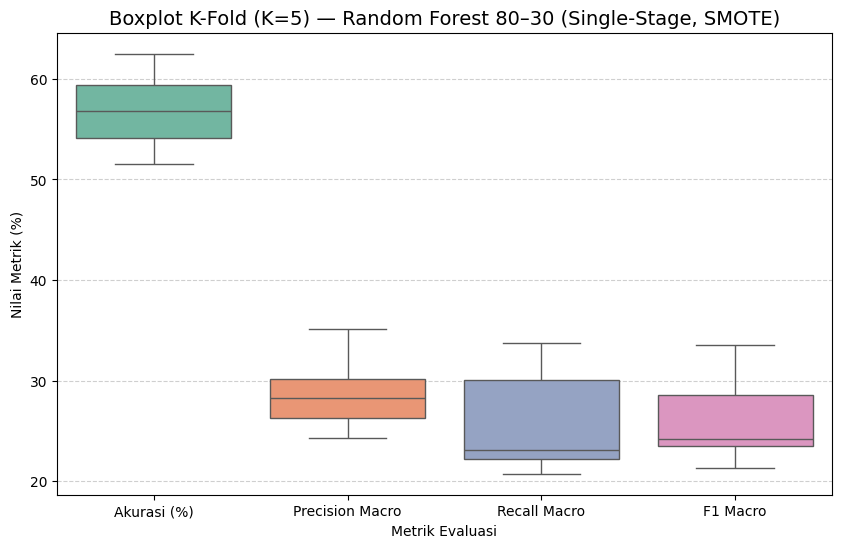

In [ ]:
# Salin dataframe khusus untuk plotting
df_kfold_plot = df_kfold_80_30.copy()

# Ubah precision, recall, f1 dari 0–1 ke persen
for col in ["Precision Macro", "Recall Macro", "F1 Macro"]:
    df_kfold_plot[col] = df_kfold_plot[col] * 100

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_kfold_plot[["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"]],
    palette="Set2"
)

plt.title("Boxplot K-Fold (K=5) — Random Forest 80–30 (Single-Stage, SMOTE)", fontsize=14)
plt.ylabel("Nilai Metrik (%)")
plt.xlabel("Metrik Evaluasi")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


**PENGARUH N ESTIMATOR SINGLESTAGE**

In [ ]:
# The 'Hyperparameter' column does not exist in df_results.
# The 'n_estimators' and 'max_depth' columns already exist in df_results
# from the df_hyper_single DataFrame that was used to create df_results.
# Therefore, this code is redundant and causes a KeyError. It can be removed or commented out.

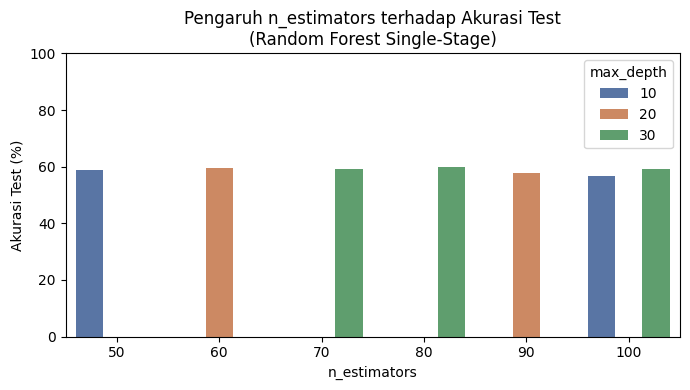

In [ ]:
plt.figure(figsize=(7,4))
sns.barplot(
    data=df_results, # Changed from df_hyper_single to df_results
    x='n_estimators',
    y='Akurasi (%)',  # Changed from acc_test to Akurasi (%)
    hue='max_depth',
    palette='deep'
)

plt.title('Pengaruh n_estimators terhadap Akurasi Test\n(Random Forest Single-Stage)')
plt.xlabel('n_estimators')
plt.ylabel('Akurasi Test (%)')
plt.ylim(0, 100)
plt.legend(title='max_depth')
plt.tight_layout()
plt.show()

**PENGARUH MAX DEPTH SINGLESTAGE**

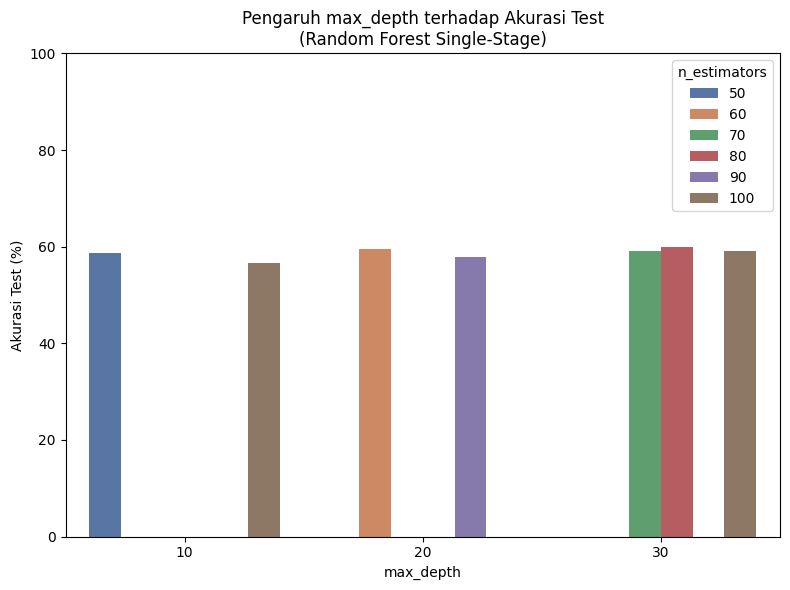

In [ ]:
plt.figure(figsize=(8,6))
sns.barplot(
    data=df_results, # Changed from df_hyper_single to df_results
    x='max_depth',
    y='Akurasi (%)',  # Changed from acc_test to Akurasi (%)
    hue='n_estimators',
    palette='deep'
)

plt.title('Pengaruh max_depth terhadap Akurasi Test\n(Random Forest Single-Stage)')
plt.xlabel('max_depth')
plt.ylabel('Akurasi Test (%)')
plt.ylim(0, 100)
plt.legend(title='n_estimators')
plt.tight_layout()
plt.show()

# **PENGARUH SMOTE SINGLESTAGE**

In [ ]:
import pandas as pd

# Manually create df_hyper_single with macro average metrics extracted from previous classification reports
hyper_results_with_macro = [
    {'n_estimators': 100, 'max_depth': 30, 'acc_train': 60.02, 'acc_test': 59.17, 'macro_precision': 0.2830, 'macro_recall': 0.2473, 'macro_f1': 0.2603},
    {'n_estimators': 50, 'max_depth': 10, 'acc_train': 55.97, 'acc_test': 58.75, 'macro_precision': 0.3196, 'macro_recall': 0.2888, 'macro_f1': 0.2973},
    {'n_estimators': 60, 'max_depth': 20, 'acc_train': 59.04, 'acc_test': 59.58, 'macro_precision': 0.2921, 'macro_recall': 0.2647, 'macro_f1': 0.2757},
    {'n_estimators': 70, 'max_depth': 30, 'acc_train': 59.92, 'acc_test': 59.17, 'macro_precision': 0.2781, 'macro_recall': 0.2539, 'macro_f1': 0.2636},
    {'n_estimators': 80, 'max_depth': 30, 'acc_train': 60.15, 'acc_test': 60.00, 'macro_precision': 0.2843, 'macro_recall': 0.2559, 'macro_f1': 0.2672},
    {'n_estimators': 90, 'max_depth': 20, 'acc_train': 59.16, 'acc_test': 57.92, 'macro_precision': 0.2599, 'macro_recall': 0.2249, 'macro_f1': 0.2359},
    {'n_estimators': 100, 'max_depth': 10, 'acc_train': 58.21, 'acc_test': 56.67, 'macro_precision': 0.2771, 'macro_recall': 0.2495, 'macro_f1': 0.2552}
]
df_hyper_single = pd.DataFrame(hyper_results_with_macro)

# ============================================================
# PROGRAM MENGHITUNG PENGARUH SMOTE MENGGUNAKAN MACRO AVERAGE
# ============================================================

# ============================================================
# 1. Hitung rata-rata macro avg dari seluruh hyperparameter
# ============================================================

mean_macro_precision = df_hyper_single["macro_precision"].mean()
mean_macro_recall    = df_hyper_single["macro_recall"].mean()
mean_macro_f1        = df_hyper_single["macro_f1"].mean()

summary_df = pd.DataFrame({
    "Metric": ["Macro Precision", "Macro Recall", "Macro F1-score"],
    "Rata-rata": [
        round(mean_macro_precision, 4),
        round(mean_macro_recall, 4),
        round(mean_macro_f1, 4)
    ]
})

print("\n=== Rata-Rata Macro Average (Pengaruh SMOTE Single-Stage) ===")
display(summary_df)

# ============================================================
# 2. Buat tabel final pengaruh SMOTE (per hyperparameter + rata-rata)
# ============================================================

tabel_pengaruh_smote = df_hyper_single.copy()

# Tambahkan baris rata-rata
tabel_pengaruh_smote.loc["Rata-rata"] = [
    "-", "-", "-", "-",  # tidak ada hyperparameter untuk baris ini, dan acc_train, acc_test
    round(mean_macro_precision, 4),
    round(mean_macro_recall, 4),
    round(mean_macro_f1, 4)
]

print("\n=== Tabel Lengkap Pengaruh SMOTE pada Single-Stage ===")
display(tabel_pengaruh_smote)


=== Rata-Rata Macro Average (Pengaruh SMOTE Single-Stage) ===


,Metric,Rata-rata
0,Macro Precision,0.2849
1,Macro Recall,0.2550
2,Macro F1-score,0.2650



=== Tabel Lengkap Pengaruh SMOTE pada Single-Stage ===


,n_estimators,max_depth,acc_train,acc_test,macro_precision,macro_recall,macro_f1
0,100,30,60.02,59.17,0.2830,0.2473,0.2603
1,50,10,55.97,58.75,0.3196,0.2888,0.2973
2,60,20,59.04,59.58,0.2921,0.2647,0.2757
3,70,30,59.92,59.17,0.2781,0.2539,0.2636
4,80,30,60.15,60.0,0.2843,0.2559,0.2672
5,90,20,59.16,57.92,0.2599,0.2249,0.2359
6,100,10,58.21,56.67,0.2771,0.2495,0.2552
Rata-rata,-,-,-,-,0.2849,0.2550,0.2650


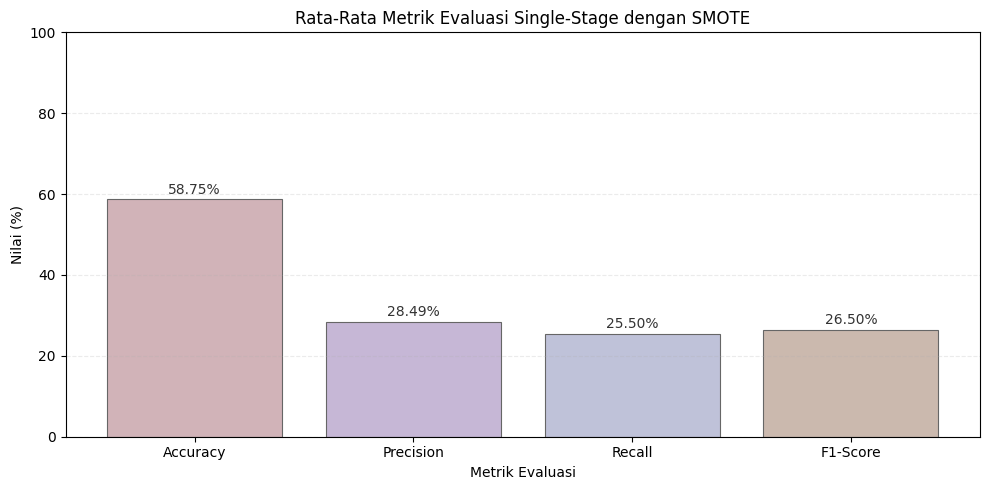

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# HITUNG RATA-RATA METRIK (SINGLE-STAGE SMOTE)
# ============================================================
mean_acc_test = df_hyper_single["acc_test"].mean()                 # %
mean_prec     = df_hyper_single["macro_precision"].mean() * 100
mean_rec      = df_hyper_single["macro_recall"].mean() * 100
mean_f1       = df_hyper_single["macro_f1"].mean() * 100

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values  = [mean_acc_test, mean_prec, mean_rec, mean_f1]

# ============================================================
# WARNA CEWEK – SOFT, POWDER, ELEGAN (SAMA DENGAN MULTI-STAGE)
# ============================================================
colors = [
    "#D1B3B8",  # soft blush grey
    "#C6B7D6",  # dusty lilac
    "#BFC2D9",  # powder lavender
    "#CBB9AE"   # warm nude taupe
]

# ============================================================
# GRAFIK BAR RATA-RATA SINGLE-STAGE SMOTE
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(metrics, values, color=colors, edgecolor="#666666", linewidth=0.8)

plt.ylim(0, 100)
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Nilai (%)")
plt.title("Rata-Rata Metrik Evaluasi Single-Stage dengan SMOTE")
plt.grid(axis="y", linestyle="--", alpha=0.25)

# Label nilai di atas batang
for bar, val in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{val:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#333333"
    )

plt.tight_layout()
plt.show()


# **MULTISTAGE**

# **STAGE 1**

In [ ]:
# 1) Siapkan fitur (X) dan label aspek (y_stage1)
#    X_bow_lib: fitur BoW yang sudah kamu buat sebelumnya
#    Label_Aspek_Numerik: 0 = Pendidikan, 1 = Politik, 2 = Bencana

X_stage1 = X_bow_lib
y_stage1 = df_aspek_bersih["Label_Aspek_Numerik"].values

print("Shape X_stage1:", X_stage1.shape)
print("Shape y_stage1:", y_stage1.shape)

print("\n=== Distribusi Kelas Aspek (Sebelum Split) ===")
print(pd.Series(y_stage1).value_counts().sort_index())

Shape X_stage1: (1200, 6275)
Shape y_stage1: (1200,)

=== Distribusi Kelas Aspek (Sebelum Split) ===
0    916
1    218
2     66
Name: count, dtype: int64


In [ ]:
mapping_aspek = {
    0: "Pendidikan",
    1: "Politik",
    2: "Bencana"
}

# Initialize after_stage1 from the distribution of y_stage1
after_stage1 = pd.Series(y_stage1).value_counts().sort_index().reset_index()
after_stage1.columns = ["Label_Aspek_Numerik", "Jumlah_Data"] # Assign column names

after_stage1["Nama_Aspek"] = after_stage1["Label_Aspek_Numerik"].map(mapping_aspek)

# **SPLIT DATA 80:20**

In [ ]:
X_train_stage1, X_test_stage1, y_train_stage1, y_test_stage1 = train_test_split(
    X_stage1,
    y_stage1,
    test_size=0.2,
    random_state=42,
    stratify=y_stage1
)

print("\nData Train Stage 1:", X_train_stage1.shape, y_train_stage1.shape)
print("Data Test  Stage 1:", X_test_stage1.shape,  y_test_stage1.shape)

print("\n=== Distribusi Kelas Aspek di DATA TRAIN (Sebelum SMOTE) ===")
print(pd.Series(y_train_stage1).value_counts().sort_index())

print("\n=== Distribusi Kelas Aspek di DATA TEST (Tanpa SMOTE) ===")
print(pd.Series(y_test_stage1).value_counts().sort_index())


Data Train Stage 1: (960, 6275) (960,)
Data Test  Stage 1: (240, 6275) (240,)

=== Distribusi Kelas Aspek di DATA TRAIN (Sebelum SMOTE) ===
0    733
1    174
2     53
Name: count, dtype: int64

=== Distribusi Kelas Aspek di DATA TEST (Tanpa SMOTE) ===
0    183
1     44
2     13
Name: count, dtype: int64


# **SMOTE**

In [ ]:
smote_stage1 = SMOTE(random_state=42, k_neighbors=4)
X_train_stage1_smote, y_train_stage1_smote = smote_stage1.fit_resample(
    X_train_stage1, y_train_stage1
)

print("\n=== Distribusi Kelas Aspek SETELAH SMOTE (DATA TRAIN) ===")
after_stage1 = (
    pd.Series(y_train_stage1_smote)
      .value_counts()
      .sort_index()
      .reset_index()
)
after_stage1.columns = ["Label_Aspek_Numerik", "Jumlah_Data"]
after_stage1["Nama_Aspek"] = after_stage1["Label_Aspek_Numerik"].map(mapping_aspek)
display(after_stage1)

print("Data Train Stage 1 (SETELAH SMOTE):", X_train_stage1_smote.shape, y_train_stage1_smote.shape)
print("Data Test  Stage 1 (TETAP ASLI)   :", X_test_stage1.shape,       y_test_stage1.shape)


=== Distribusi Kelas Aspek SETELAH SMOTE (DATA TRAIN) ===


,Label_Aspek_Numerik,Jumlah_Data,Nama_Aspek
0,0,733,Pendidikan
1,1,733,Politik
2,2,733,Bencana


Data Train Stage 1 (SETELAH SMOTE): (2199, 6275) (2199,)
Data Test  Stage 1 (TETAP ASLI)   : (240, 6275) (240,)


# **ALGORITMA RANDOM FOREST**

# **HYPERPARAMETER 100-30**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 64.48%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 58.33%


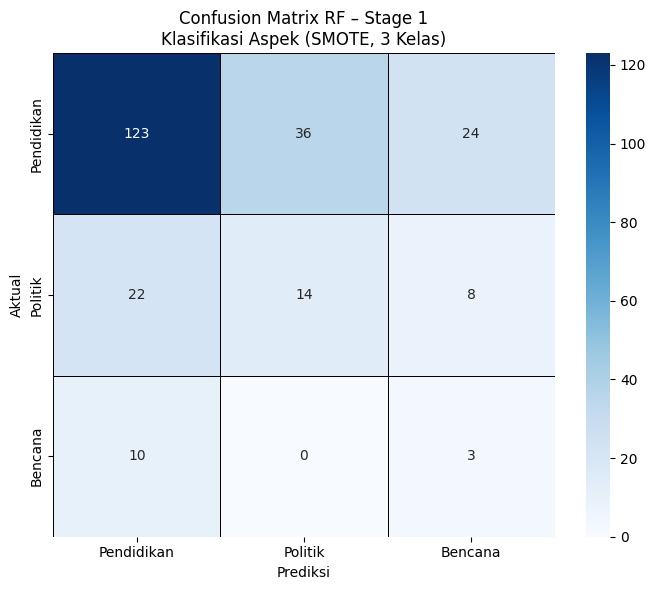


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7935    0.6721    0.7278       183
     Politik     0.2800    0.3182    0.2979        44
     Bencana     0.0857    0.2308    0.1250        13

    accuracy                         0.5833       240
   macro avg     0.3864    0.4070    0.3836       240
weighted avg     0.6611    0.5833    0.6163       240



/tmp/ipython-input-3234867312.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


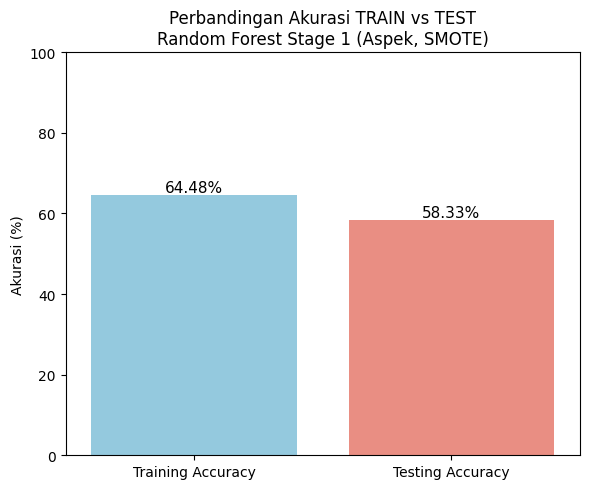

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=100,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=30,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 50-10**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 62.53%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 55.00%


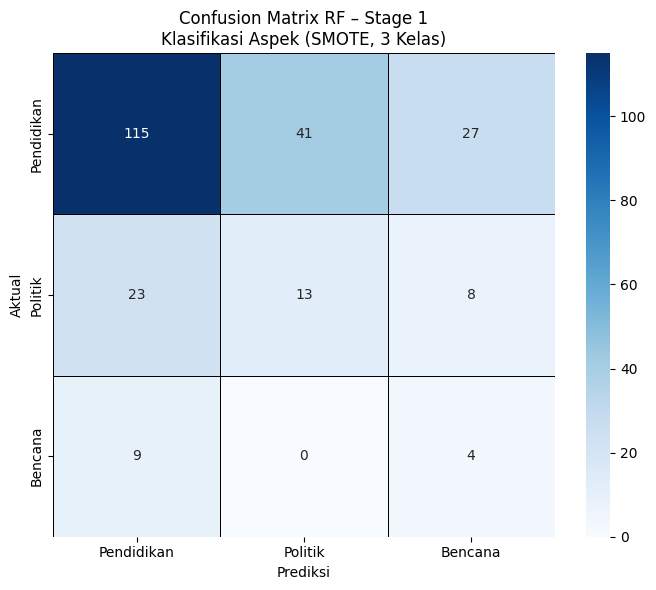


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7823    0.6284    0.6970       183
     Politik     0.2407    0.2955    0.2653        44
     Bencana     0.1026    0.3077    0.1538        13

    accuracy                         0.5500       240
   macro avg     0.3752    0.4105    0.3720       240
weighted avg     0.6462    0.5500    0.5884       240



/tmp/ipython-input-2945461326.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


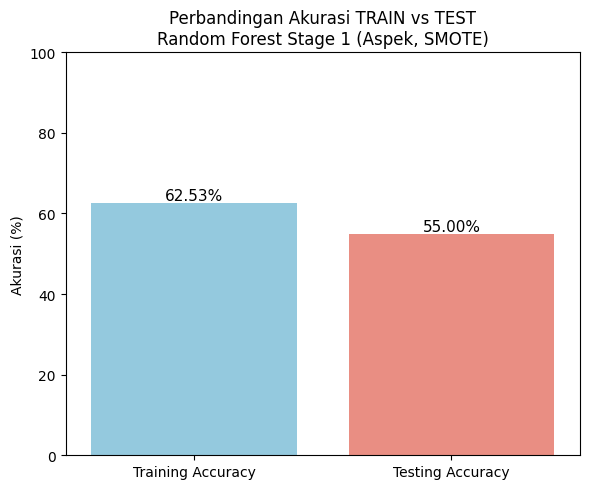

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=50,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=10,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 60-20**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 63.17%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 58.33%


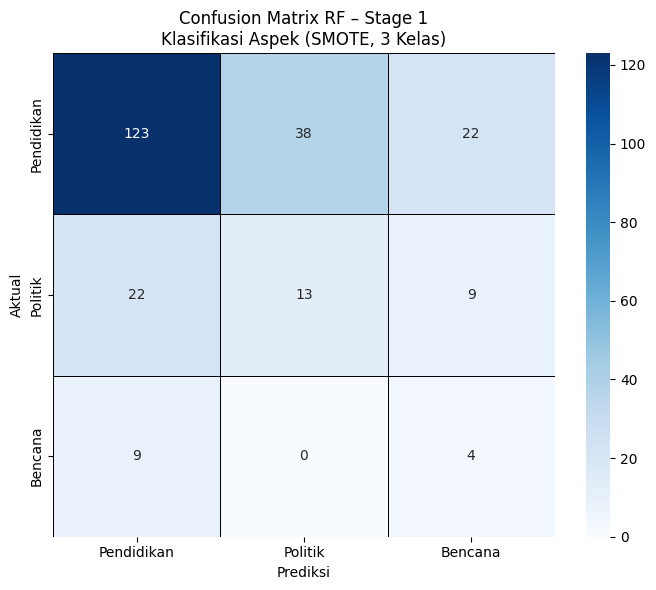


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7987    0.6721    0.7300       183
     Politik     0.2549    0.2955    0.2737        44
     Bencana     0.1143    0.3077    0.1667        13

    accuracy                         0.5833       240
   macro avg     0.3893    0.4251    0.3901       240
weighted avg     0.6619    0.5833    0.6158       240



/tmp/ipython-input-535931984.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


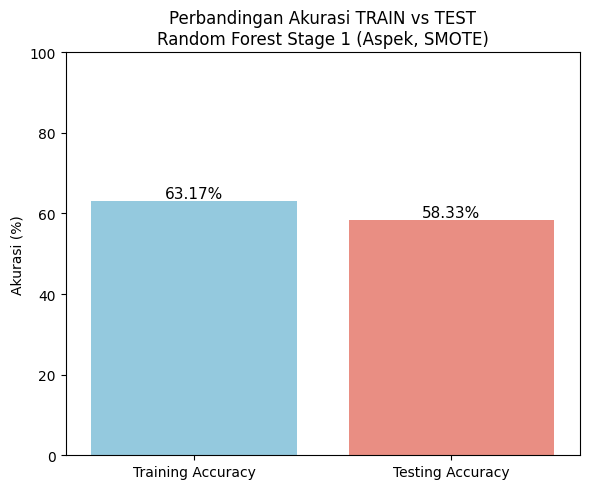

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=60,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=20,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 70-30**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 63.39%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 59.17%


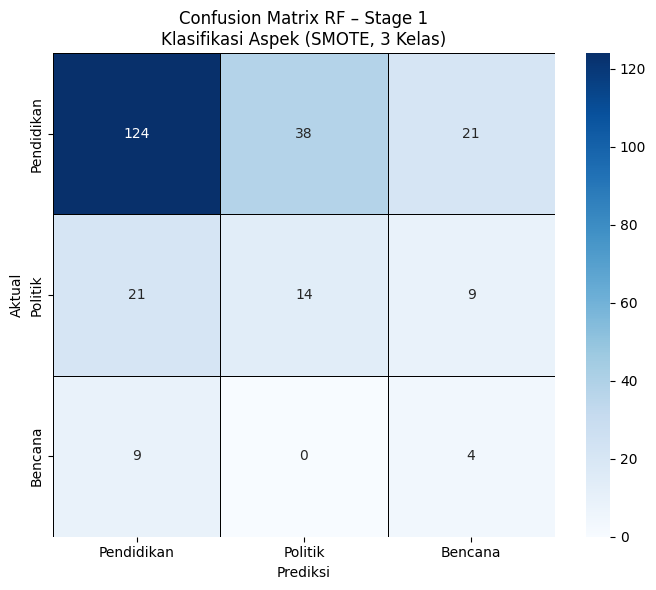


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.8052    0.6776    0.7359       183
     Politik     0.2692    0.3182    0.2917        44
     Bencana     0.1176    0.3077    0.1702        13

    accuracy                         0.5917       240
   macro avg     0.3974    0.4345    0.3993       240
weighted avg     0.6697    0.5917    0.6238       240



/tmp/ipython-input-2947499172.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


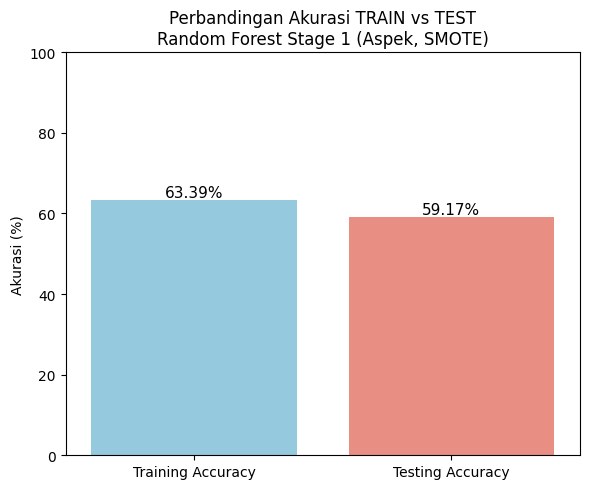

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=70,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=30,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 80-30**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 64.21%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 57.08%


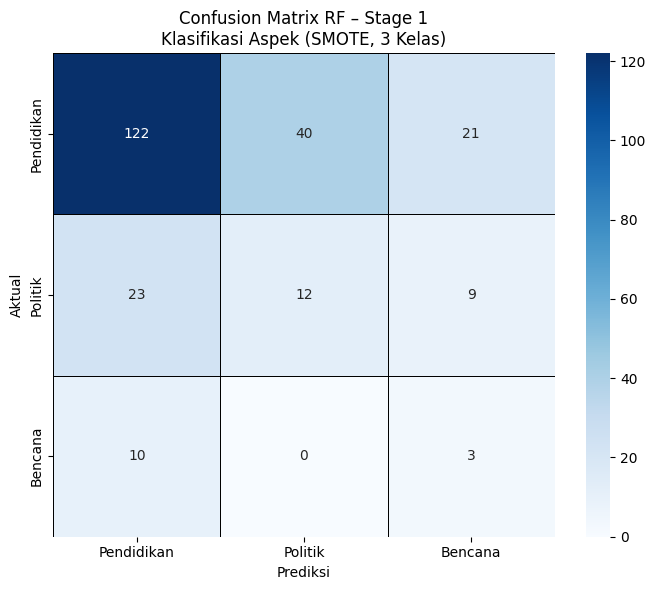


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7871    0.6667    0.7219       183
     Politik     0.2308    0.2727    0.2500        44
     Bencana     0.0909    0.2308    0.1304        13

    accuracy                         0.5708       240
   macro avg     0.3696    0.3901    0.3674       240
weighted avg     0.6474    0.5708    0.6033       240



/tmp/ipython-input-3405782901.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


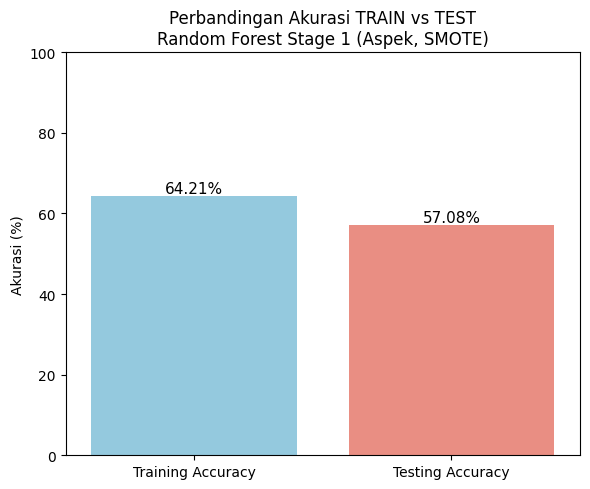

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=80,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=30,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 90-20**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 64.30%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 59.17%


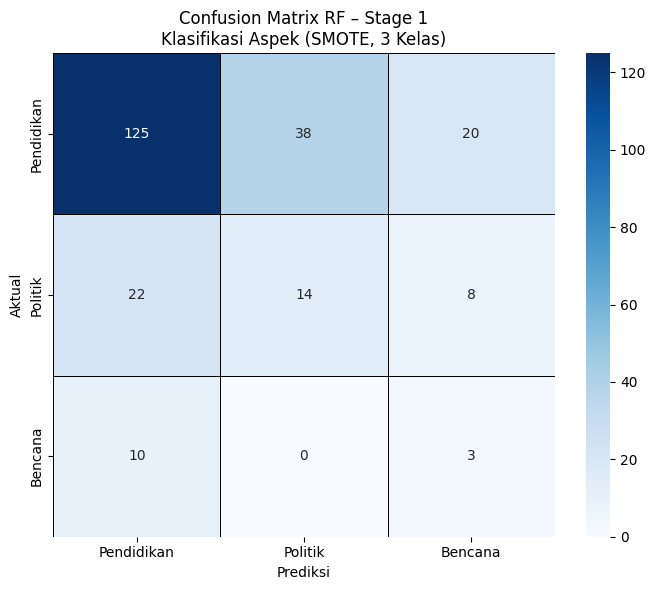


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7962    0.6831    0.7353       183
     Politik     0.2692    0.3182    0.2917        44
     Bencana     0.0968    0.2308    0.1364        13

    accuracy                         0.5917       240
   macro avg     0.3874    0.4107    0.3878       240
weighted avg     0.6617    0.5917    0.6215       240



/tmp/ipython-input-4066163176.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


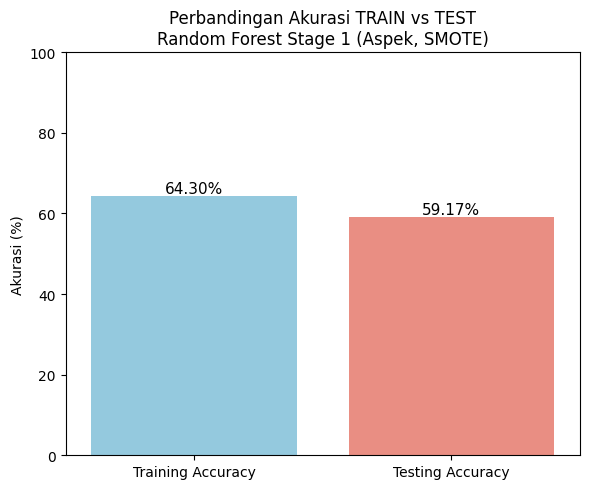

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=90,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=20,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 100-10**


Akurasi TRAIN Stage 1 (Aspek + SMOTE): 64.12%
Akurasi TEST  Stage 1 (Aspek + SMOTE): 57.92%


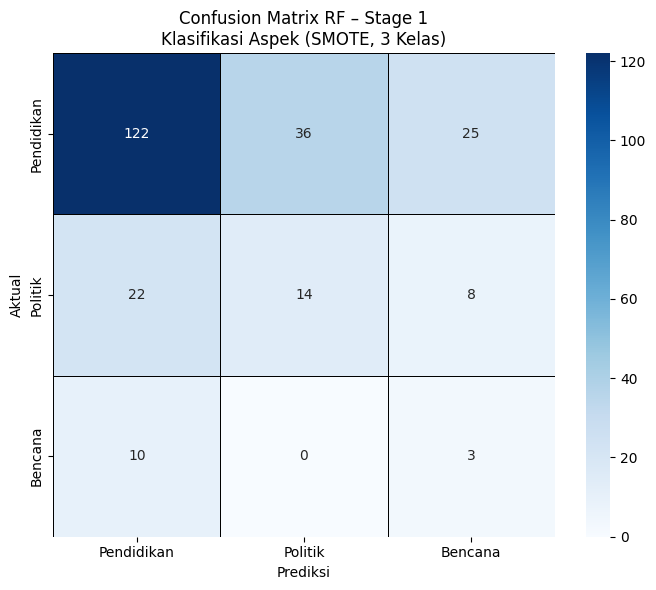


=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===
              precision    recall  f1-score   support

  Pendidikan     0.7922    0.6667    0.7240       183
     Politik     0.2800    0.3182    0.2979        44
     Bencana     0.0833    0.2308    0.1224        13

    accuracy                         0.5792       240
   macro avg     0.3852    0.4052    0.3815       240
weighted avg     0.6599    0.5792    0.6133       240



/tmp/ipython-input-2982524644.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


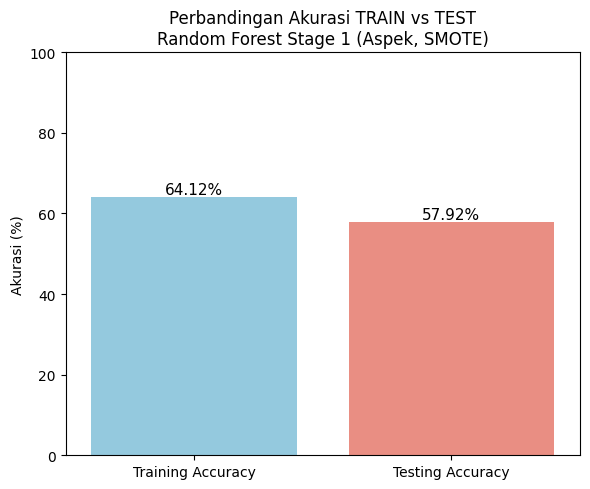

In [ ]:
# ==============================================
# 4) Inisialisasi & Training Random Forest (Stage 1)
# ==============================================

rf_stage1_aspek = RandomForestClassifier(
    n_estimators=100,      # kamu bisa ganti dengan kombinasi terbaik
    max_depth=10,         # dari hasil tuning singlestage atau tuning baru
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_stage1_aspek.fit(X_train_stage1_smote, y_train_stage1_smote)

# ==============================================
# 5) Prediksi & Akurasi (Stage 1)
# ==============================================

y_pred_train_stage1 = rf_stage1_aspek.predict(X_train_stage1_smote)
y_pred_test_stage1  = rf_stage1_aspek.predict(X_test_stage1)

acc_train_stage1 = accuracy_score(y_train_stage1_smote, y_pred_train_stage1)
acc_test_stage1  = accuracy_score(y_test_stage1,        y_pred_test_stage1)

print(f"\nAkurasi TRAIN Stage 1 (Aspek + SMOTE): {acc_train_stage1*100:.2f}%")
print(f"Akurasi TEST  Stage 1 (Aspek + SMOTE): {acc_test_stage1*100:.2f}%")

# ==============================================
# 6) Confusion Matrix & Classification Report (Stage 1)
# ==============================================

cm_stage1 = confusion_matrix(y_test_stage1, y_pred_test_stage1)

# urutan label 0,1,2 → Pendidikan, Politik, Bencana
label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

cm_stage1_df = pd.DataFrame(
    cm_stage1,
    index=label_names_stage1,
    columns=label_names_stage1
)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_stage1_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix RF – Stage 1\nKlasifikasi Aspek (SMOTE, 3 Kelas)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 1 (Aspek) ===")
print(classification_report(
    y_test_stage1,
    y_pred_test_stage1,
    labels=label_order_stage1,
    target_names=label_names_stage1,
    digits=4,
    zero_division=0
))

# ==============================================
# 7) (Opsional) Grafik Perbandingan Akurasi TRAIN vs TEST Stage 1
# ==============================================

df_acc_stage1 = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_stage1 * 100, acc_test_stage1 * 100]
})

plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_acc_stage1,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.xlabel("")
plt.title("Perbandingan Akurasi TRAIN vs TEST\nRandom Forest Stage 1 (Aspek, SMOTE)")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

**MENAMPILKAN HASIL SELURUH HYPERPARAMETER**

In [ ]:
import pandas as pd

# =========================================
# REKAP PERFORMA HYPERPARAMETER STAGE 1
# Random Forest Multistage (Aspek, SMOTE)
# =========================================

data_stage1 = [
    {
        "Hyperparameter": "50-10",
        "Akurasi (%)": 55.00,
        "Precision Macro": 0.3752,
        "Recall Macro": 0.4105,
        "F1 Macro": 0.3720,
    },
    {
        "Hyperparameter": "60-20",
        "Akurasi (%)": 58.33,
        "Precision Macro": 0.3893,
        "Recall Macro": 0.4251,
        "F1 Macro": 0.3901,
    },
    {
        "Hyperparameter": "70-30",
        "Akurasi (%)": 59.17,
        "Precision Macro": 0.3974,
        "Recall Macro": 0.4345,
        "F1 Macro": 0.3993,
    },
    {
        "Hyperparameter": "80-30",
        "Akurasi (%)": 57.08,
        "Precision Macro": 0.3696,
        "Recall Macro": 0.3901,
        "F1 Macro": 0.3674,
    },
    {
        "Hyperparameter": "90-20",
        "Akurasi (%)": 59.17,
        "Precision Macro": 0.3874,
        "Recall Macro": 0.4107,
        "F1 Macro": 0.3878,
    },
    {
        "Hyperparameter": "100-10",
        "Akurasi (%)": 57.92,
        "Precision Macro": 0.3852,
        "Recall Macro": 0.4052,
        "F1 Macro": 0.3815,
    },
    {
        "Hyperparameter": "100-30",
        "Akurasi (%)": 58.33,
        "Precision Macro": 0.3864,
        "Recall Macro": 0.4070,
        "F1 Macro": 0.3836,
    },
]

# Jadikan DataFrame
df_stage1_results = pd.DataFrame(data_stage1)

print("=== TABEL REKAP PERFORMA HYPERPARAMETER (MULTISTAGE STAGE 1, SMOTE) ===")
display(df_stage1_results)

# Sort the DataFrame to find the best hyperparameter
df_stage1_sorted = df_stage1_results.sort_values(by="Akurasi (%)", ascending=False)

# (Opsional) tunjukkan hyperparameter terbaik
best = df_stage1_sorted.iloc[0]
print(
    f"\nHyperparameter terbaik Stage 1: {best['Hyperparameter']} "
    f"dengan akurasi {best['Akurasi (%)']:.2f}% "
    f"dan F1 Macro {best['F1 Macro']:.4f}"
)


=== TABEL REKAP PERFORMA HYPERPARAMETER (MULTISTAGE STAGE 1, SMOTE) ===


,Hyperparameter,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,50-10,55.00,0.3752,0.4105,0.3720
1,60-20,58.33,0.3893,0.4251,0.3901
2,70-30,59.17,0.3974,0.4345,0.3993
3,80-30,57.08,0.3696,0.3901,0.3674
4,90-20,59.17,0.3874,0.4107,0.3878
5,100-10,57.92,0.3852,0.4052,0.3815
6,100-30,58.33,0.3864,0.4070,0.3836



Hyperparameter terbaik Stage 1: 70-30 dengan akurasi 59.17% dan F1 Macro 0.3993


# **RATA-RATA MULTISTAGE STAGE 1**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display

# ---------------------------------------------------
# 1. Daftar skenario Hyperparameter Stage 1
# ---------------------------------------------------
skenario_stage1 = [
    {"nama": "100-30", "n_estimators": 100, "max_depth": 30},
    {"nama": "50-10",  "n_estimators": 50,  "max_depth": 10},
    {"nama": "60-20",  "n_estimators": 60,  "max_depth": 20},
    {"nama": "70-30",  "n_estimators": 70,  "max_depth": 30},
    {"nama": "80-30",  "n_estimators": 80,  "max_depth": 30},
    {"nama": "90-20",  "n_estimators": 90,  "max_depth": 20},
    {"nama": "100-10", "n_estimators": 100, "max_depth": 10},
]

label_order_stage1 = [0, 1, 2]
label_names_stage1 = [mapping_aspek[i] for i in label_order_stage1]

# ---------------------------------------------------
# 2. Loop semua skenario → simpan hasil
# ---------------------------------------------------
hasil_stage1 = []

for sk in skenario_stage1:

    model = RandomForestClassifier(
        n_estimators=sk["n_estimators"],
        max_depth=sk["max_depth"],
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_stage1_smote, y_train_stage1_smote)
    y_pred = model.predict(X_test_stage1)

    acc = accuracy_score(y_test_stage1, y_pred)

    report = classification_report(
        y_test_stage1,
        y_pred,
        labels=label_order_stage1,
        target_names=label_names_stage1,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    hasil_stage1.append({
        "Hyperparameter": sk["nama"],
        "Akurasi (%)": round(acc * 100, 2),
        "Precision Macro": round(report["macro avg"]["precision"], 4),
        "Recall Macro": round(report["macro avg"]["recall"], 4),
        "F1 Macro": round(report["macro avg"]["f1-score"], 4)
    })

# ---------------------------------------------------
# 3. Buat Tabel Rapi
# ---------------------------------------------------
df_stage1_table = pd.DataFrame(hasil_stage1)

# Hitung rata-rata untuk 1 baris tambahan
mean_row = pd.DataFrame({
    "Hyperparameter": ["Rata-rata"],
    "Akurasi (%)": [df_stage1_table["Akurasi (%)"].mean().round(2)],
    "Precision Macro": [df_stage1_table["Precision Macro"].mean().round(4)],
    "Recall Macro": [df_stage1_table["Recall Macro"].mean().round(4)],
    "F1 Macro": [df_stage1_table["F1 Macro"].mean().round(4)],
})

# Gabungkan tabel + rata-rata
df_final = pd.concat([df_stage1_table, mean_row], ignore_index=True)

# ---------------------------------------------------
# 4. Tampilkan hanya 1 output tabel
# ---------------------------------------------------
print("=== TABEL REKAP PERFORMA HYPERPARAMETER (STAGE 1, SMOTE) ===")
display(df_final)


=== TABEL REKAP PERFORMA HYPERPARAMETER (STAGE 1, SMOTE) ===


,Hyperparameter,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,100-30,58.33,0.3864,0.4070,0.3836
1,50-10,55.00,0.3752,0.4105,0.3720
2,60-20,58.33,0.3893,0.4251,0.3901
3,70-30,59.17,0.3974,0.4345,0.3993
4,80-30,57.08,0.3696,0.3901,0.3674
5,90-20,59.17,0.3874,0.4107,0.3878
6,100-10,57.92,0.3852,0.4052,0.3815
7,Rata-rata,57.86,0.3844,0.4119,0.3831


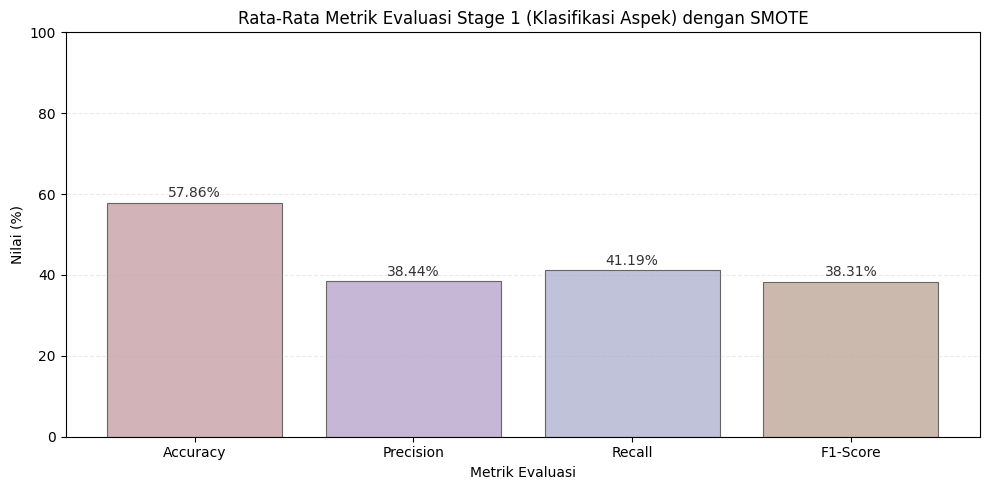

In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# 1) AMBIL BARIS RATA-RATA DARI df_final
# ============================================================
avg_row = df_final[df_final["Hyperparameter"] == "Rata-rata"].iloc[0]

mean_acc  = float(avg_row["Akurasi (%)"])
mean_prec = float(avg_row["Precision Macro"]) * 100
mean_rec  = float(avg_row["Recall Macro"]) * 100
mean_f1   = float(avg_row["F1 Macro"]) * 100

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values  = [mean_acc, mean_prec, mean_rec, mean_f1]

# ============================================================
# 2) WARNA SOFT – POWDER – ELEGAN (SAMA DENGAN CONTOHMU)
# ============================================================
colors = [
    "#D1B3B8",  # soft blush grey
    "#C6B7D6",  # dusty lilac
    "#BFC2D9",  # powder lavender
    "#CBB9AE"   # warm nude taupe
]

# ============================================================
# 3) GRAFIK BAR RATA-RATA STAGE 1
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(
    metrics,
    values,
    color=colors,
    edgecolor="#666666",
    linewidth=0.8
)

plt.ylim(0, 100)
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Nilai (%)")
plt.title("Rata-Rata Metrik Evaluasi Stage 1 (Klasifikasi Aspek) dengan SMOTE")
plt.grid(axis="y", linestyle="--", alpha=0.25)

# ============================================================
# 4) LABEL NILAI DI ATAS BATANG
# ============================================================
for bar, val in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{val:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#333333"
    )

plt.tight_layout()
plt.show()


# **K-FOLD = 5 PADA HYPERPARAMETER 70-30**

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# K-Fold (K=5) untuk Stage 1 Multistage
# RF, SMOTE, Hyperparameter Terbaik 70-30
# ============================================

k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

fold_results_stage1 = []

print("=== Evaluasi K-Fold (K=5) - RF Multistage Stage 1, SMOTE, Hyperparameter 70-30 ===")

# ⬇️ Penting: pakai X_train_stage1 & y_train_stage1 (BELUM SMOTE)
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_stage1, y_train_stage1), start=1):
    print(f"\n----- Fold {fold} -----")

    # a) Split train / validasi
    X_tr, X_val = X_train_stage1[train_idx], X_train_stage1[val_idx]
    y_tr, y_val = y_train_stage1[train_idx], y_train_stage1[val_idx]

    # b) SMOTE HANYA di data train-fold
    smote_fold = SMOTE(random_state=42, k_neighbors=3)
    X_tr_sm, y_tr_sm = smote_fold.fit_resample(X_tr, y_tr)

    print("  Ukuran train SMOTE :", X_tr_sm.shape, y_tr_sm.shape)
    print("  Ukuran validasi    :", X_val.shape,  y_val.shape)

    # c) Model RF dengan hyperparameter terbaik 70-30
    rf_fold_stage1 = RandomForestClassifier(
        n_estimators=70,
        max_depth=30,
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    rf_fold_stage1.fit(X_tr_sm, y_tr_sm)
    y_val_pred = rf_fold_stage1.predict(X_val)

    # d) Hitung metrik per fold
    acc = accuracy_score(y_val, y_val_pred) * 100
    prec_macro = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
    rec_macro  = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    f1_macro   = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

    print(f"  Akurasi Fold {fold}        : {acc:.2f}%")
    print(f"  Precision Macro Fold {fold}: {prec_macro:.4f}")
    print(f"  Recall Macro Fold {fold}   : {rec_macro:.4f}")
    print(f"  F1 Macro Fold {fold}       : {f1_macro:.4f}")

    fold_results_stage1.append({
        "Fold": fold,
        "Akurasi (%)": acc,
        "Precision Macro": prec_macro,
        "Recall Macro": rec_macro,
        "F1 Macro": f1_macro
    })

# ============================================
# Rekap hasil K-Fold Stage 1 (70-30)
# ============================================

df_kfold_stage1_70_30 = pd.DataFrame(fold_results_stage1)

print("\n=== Tabel Hasil K-Fold (K=5) - Stage 1, RF 70-30 ===")
display(df_kfold_stage1_70_30)

print("\n=== Rata-rata K-Fold (K=5) - Stage 1, RF 70-30 ===")
print(df_kfold_stage1_70_30[["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"]].mean())


=== Evaluasi K-Fold (K=5) - RF Multistage Stage 1, SMOTE, Hyperparameter 70-30 ===

----- Fold 1 -----
  Ukuran train SMOTE : (1758, 6275) (1758,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 1        : 54.69%
  Precision Macro Fold 1: 0.4203
  Recall Macro Fold 1   : 0.4708
  F1 Macro Fold 1       : 0.4110

----- Fold 2 -----
  Ukuran train SMOTE : (1761, 6275) (1761,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 2        : 60.94%
  Precision Macro Fold 2: 0.4868
  Recall Macro Fold 2   : 0.5864
  F1 Macro Fold 2       : 0.4829

----- Fold 3 -----
  Ukuran train SMOTE : (1761, 6275) (1761,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 3        : 59.38%
  Precision Macro Fold 3: 0.4146
  Recall Macro Fold 3   : 0.4177
  F1 Macro Fold 3       : 0.4085

----- Fold 4 -----
  Ukuran train SMOTE : (1758, 6275) (1758,)
  Ukuran validasi    : (192, 6275) (192,)
  Akurasi Fold 4        : 51.04%
  Precision Macro Fold 4: 0.3681
  Recall Macro Fold 4   : 0.393

,Fold,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,1,54.687500,0.420254,0.470819,0.411046
1,2,60.937500,0.486823,0.586355,0.482928
2,3,59.375000,0.414625,0.417684,0.408547
3,4,51.041667,0.368081,0.393197,0.357997
4,5,45.833333,0.366082,0.506122,0.349060



=== Rata-rata K-Fold (K=5) - Stage 1, RF 70-30 ===
Akurasi (%)        54.375000
Precision Macro     0.411173
Recall Macro        0.474835
F1 Macro            0.401916
dtype: float64


/tmp/ipython-input-290831522.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


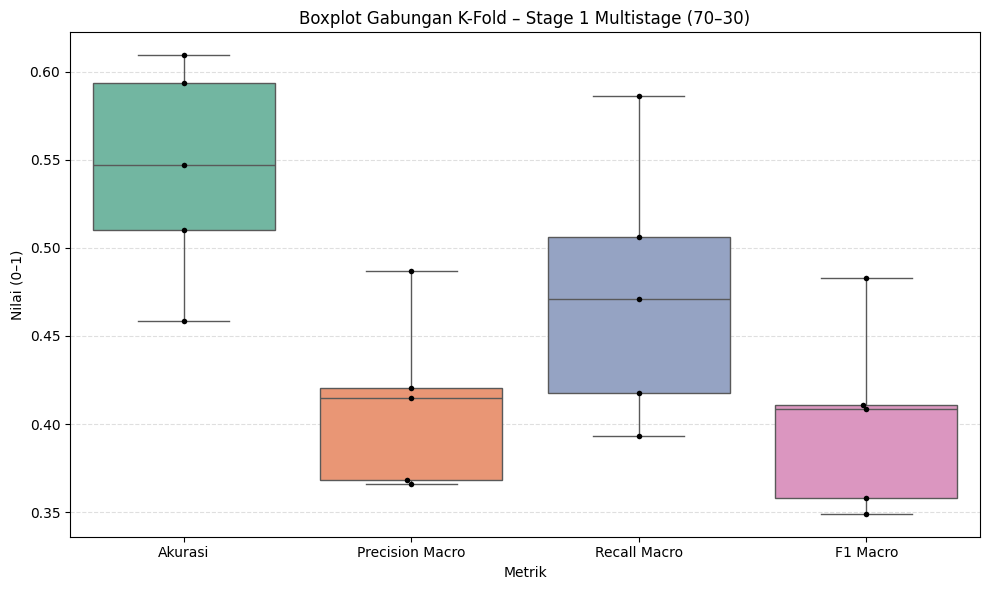

In [ ]:
# ============================================
# 1) Normalisasi akurasi
# ============================================
df_plot = df_kfold_stage1_70_30.copy()
df_plot["Akurasi"] = df_plot["Akurasi (%)"] / 100   # rename biar rapi

# ============================================
# 2) Pilih kolom yang mau digabung
# ============================================
df_long = df_plot[[
    "Akurasi",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro"
]].melt(var_name="Metrik", value_name="Nilai")

# ============================================
# 3) BOXPLOT GABUNGAN WARNA-WARNI
# ============================================
plt.figure(figsize=(10, 6))
sns.boxplot(
    x="Metrik",
    y="Nilai",
    data=df_long,
    palette="Set2"   # warna pastel beda-beda
)

sns.swarmplot(
    x="Metrik",
    y="Nilai",
    data=df_long,
    color="black",
    size=4
)

plt.title("Boxplot Gabungan K-Fold – Stage 1 Multistage (70–30)")
plt.ylabel("Nilai (0–1)")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# **STAGE 2 ASPEK PENDIDIKAN**

In [ ]:
# 1) Filter data khusus Pendidikan
mask_pen = df_aspek_bersih["Aspek"] == "Pendidikan"

X_pen = X_bow_lib[mask_pen]   # fitur BoW
y_pen = df_aspek_bersih.loc[mask_pen, "label"].values   # 0 = NonHoaks, 1 = Hoaks

print("Shape data Pendidikan:", X_pen.shape)
print("Distribusi label (0=NonHoaks,1=Hoaks):")
print(pd.Series(y_pen).value_counts())

Shape data Pendidikan: (916, 6275)
Distribusi label (0=NonHoaks,1=Hoaks):
1    827
0     89
Name: count, dtype: int64


# **SPLIT DATA 80:20**

In [ ]:
# ==============================================================
# 2) Split Train–Test
# ==============================================================

from sklearn.model_selection import train_test_split

X_train_pen, X_test_pen, y_train_pen, y_test_pen = train_test_split(
    X_pen,
    y_pen,
    test_size=0.2,
    random_state=42,
    stratify=y_pen
)
print("\nData Train Pendidikan:", X_train_pen.shape)
print("Data Test  Pendidikan:", X_test_pen.shape)

print("\nDistribusi Train sebelum SMOTE:")
print(pd.Series(y_train_pen).value_counts())

print("\nDistribusi Test (tanpa SMOTE):")
print(pd.Series(y_test_pen).value_counts())


Data Train Pendidikan: (732, 6275)
Data Test  Pendidikan: (184, 6275)

Distribusi Train sebelum SMOTE:
1    661
0     71
Name: count, dtype: int64

Distribusi Test (tanpa SMOTE):
1    166
0     18
Name: count, dtype: int64


# **SMOTE**

In [ ]:
# ==============================================================
# 3) SMOTE HANYA PADA TRAIN
# ==============================================================

from imblearn.over_sampling import SMOTE

smote_pen = SMOTE(random_state=42, k_neighbors=4)
X_train_pen_smote, y_train_pen_smote = smote_pen.fit_resample(
    X_train_pen, y_train_pen
)

print("\nDistribusi Train SETELAH SMOTE:")
print(pd.Series(y_train_pen_smote).value_counts())


Distribusi Train SETELAH SMOTE:
1    661
0    661
Name: count, dtype: int64


# **HYPERPARAMETER 100-30**


Akurasi TRAIN Stage 2 (Pendidikan): 80.79%
Akurasi TEST  Stage 2 (Pendidikan): 64.67%


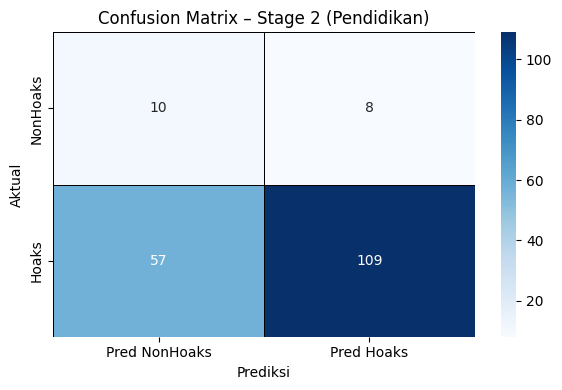


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1493    0.5556    0.2353        18
       Hoaks     0.9316    0.6566    0.7703       166

    accuracy                         0.6467       184
   macro avg     0.5404    0.6061    0.5028       184
weighted avg     0.8551    0.6467    0.7180       184



/tmp/ipython-input-1802654930.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


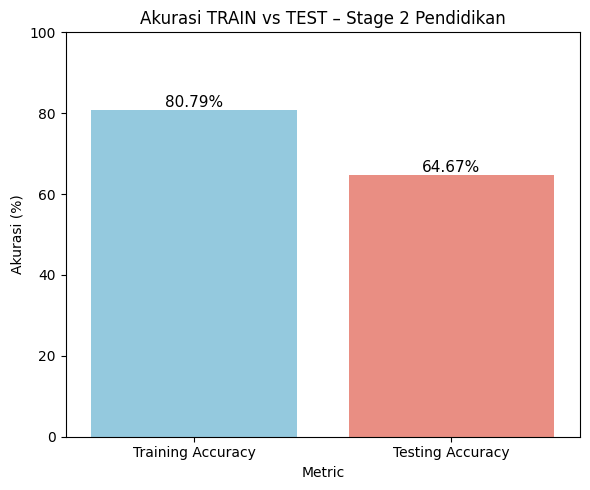

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 50-10**


Akurasi TRAIN Stage 2 (Pendidikan): 81.01%
Akurasi TEST  Stage 2 (Pendidikan): 67.39%


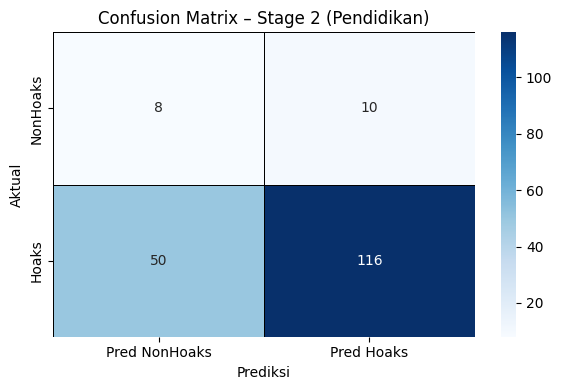


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1379    0.4444    0.2105        18
       Hoaks     0.9206    0.6988    0.7945       166

    accuracy                         0.6739       184
   macro avg     0.5293    0.5716    0.5025       184
weighted avg     0.8441    0.6739    0.7374       184



/tmp/ipython-input-2977674552.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


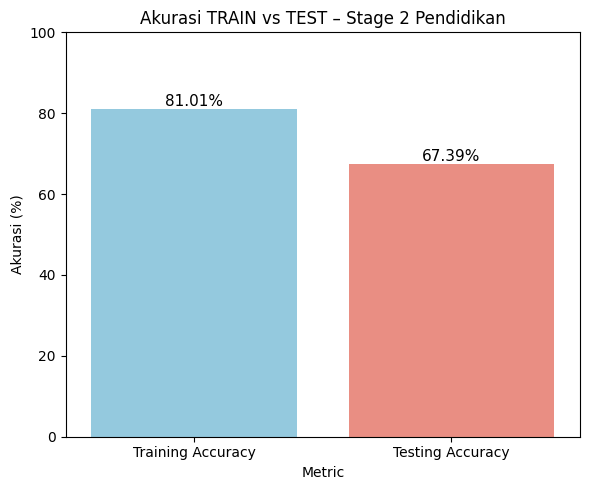

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 60-20**


Akurasi TRAIN Stage 2 (Pendidikan): 79.80%
Akurasi TEST  Stage 2 (Pendidikan): 64.67%


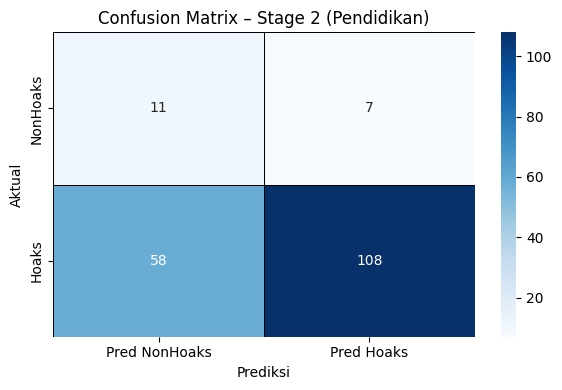


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1594    0.6111    0.2529        18
       Hoaks     0.9391    0.6506    0.7687       166

    accuracy                         0.6467       184
   macro avg     0.5493    0.6309    0.5108       184
weighted avg     0.8629    0.6467    0.7182       184



/tmp/ipython-input-3446913849.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


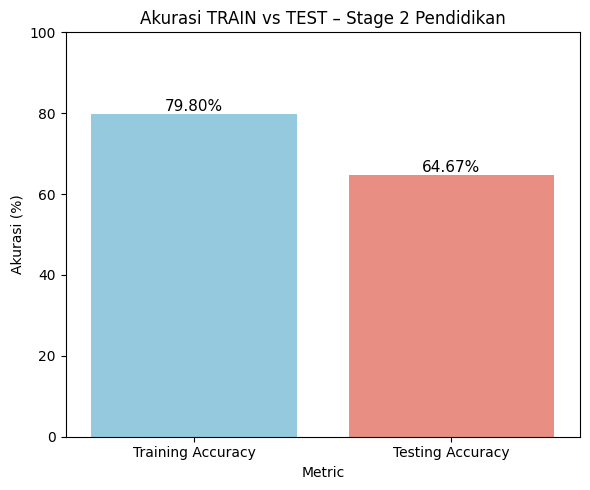

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=60,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 70-30**


Akurasi TRAIN Stage 2 (Pendidikan): 80.33%
Akurasi TEST  Stage 2 (Pendidikan): 63.59%


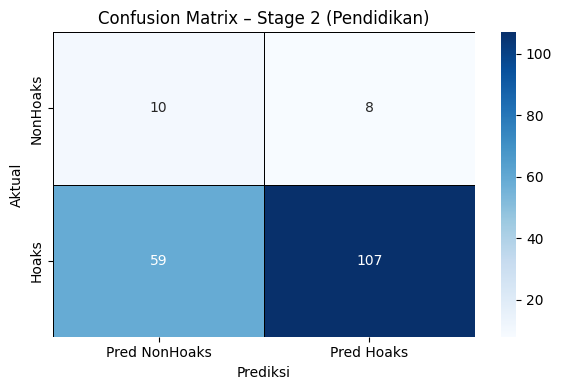


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1449    0.5556    0.2299        18
       Hoaks     0.9304    0.6446    0.7616       166

    accuracy                         0.6359       184
   macro avg     0.5377    0.6001    0.4957       184
weighted avg     0.8536    0.6359    0.7096       184



/tmp/ipython-input-3218618923.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


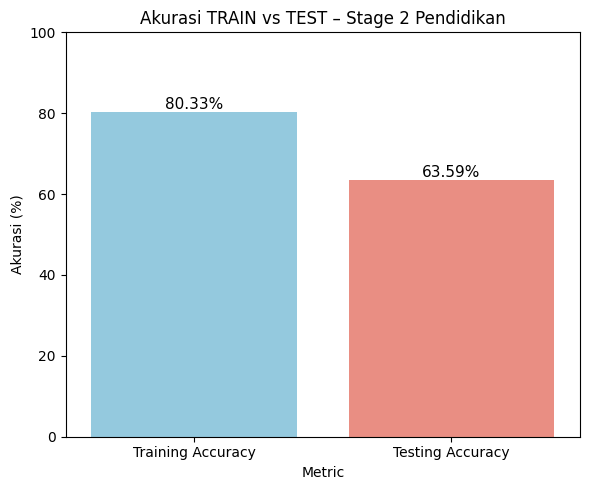

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=70,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 80-30**


Akurasi TRAIN Stage 2 (Pendidikan): 80.71%
Akurasi TEST  Stage 2 (Pendidikan): 64.13%


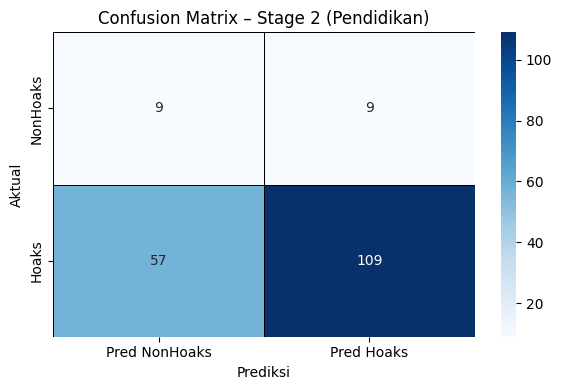


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1364    0.5000    0.2143        18
       Hoaks     0.9237    0.6566    0.7676       166

    accuracy                         0.6413       184
   macro avg     0.5300    0.5783    0.4909       184
weighted avg     0.8467    0.6413    0.7135       184



/tmp/ipython-input-365713062.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


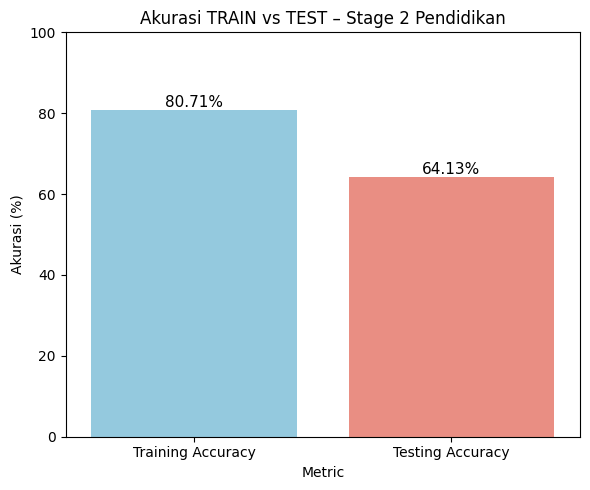

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=80,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 90-20**


Akurasi TRAIN Stage 2 (Pendidikan): 80.79%
Akurasi TEST  Stage 2 (Pendidikan): 64.13%


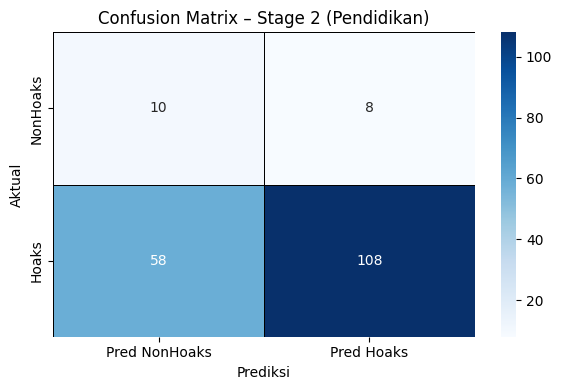


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1471    0.5556    0.2326        18
       Hoaks     0.9310    0.6506    0.7660       166

    accuracy                         0.6413       184
   macro avg     0.5390    0.6031    0.4993       184
weighted avg     0.8543    0.6413    0.7138       184



/tmp/ipython-input-1436227195.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


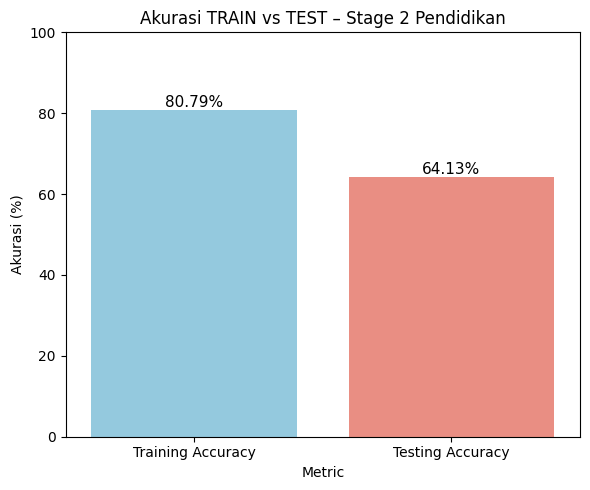

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=90,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 100-10**


Akurasi TRAIN Stage 2 (Pendidikan): 80.79%
Akurasi TEST  Stage 2 (Pendidikan): 64.13%


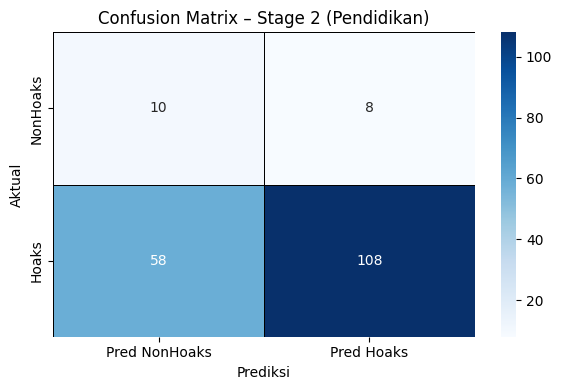


=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===
              precision    recall  f1-score   support

    NonHoaks     0.1471    0.5556    0.2326        18
       Hoaks     0.9310    0.6506    0.7660       166

    accuracy                         0.6413       184
   macro avg     0.5390    0.6031    0.4993       184
weighted avg     0.8543    0.6413    0.7138       184



/tmp/ipython-input-2698029815.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


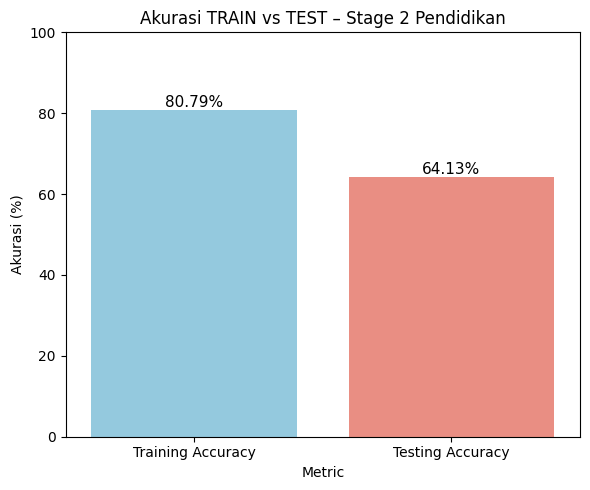

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pen = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

# ==============================================================
# 5) Prediksi & Akurasi
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
y_pred_test_pen  = rf_pen.predict(X_test_pen)

acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

print(f"\nAkurasi TRAIN Stage 2 (Pendidikan): {acc_train_pen*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Pendidikan): {acc_test_pen*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix
# ==============================================================

cm_pen = confusion_matrix(y_test_pen, y_pred_test_pen)

cm_pen_df = pd.DataFrame(
    cm_pen,
    index=["NonHoaks", "Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pen_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Pendidikan)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Pendidikan) ===")
print(classification_report(
    y_test_pen,
    y_pred_test_pen,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST
# ==============================================================

df_acc_pen = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pen * 100, acc_test_pen * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pen,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Pendidikan")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

**Menampilkan Hasil Keseluruhan tiap hyperparameter**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# =====================================================
# 1) Daftar kombinasi hyperparameter yang mau diuji
#    (sesuai skenario yang sudah kamu jalankan)
# =====================================================
param_list_pen_stage2 = [
    {"n_estimators": 100, "max_depth": 30},  # 100-30
    {"n_estimators": 50,  "max_depth": 10},  # 50-10
    {"n_estimators": 60,  "max_depth": 20},  # 60-20
    {"n_estimators": 70,  "max_depth": 30},  # 70-30
    {"n_estimators": 80,  "max_depth": 30},  # 80-30
    {"n_estimators": 90,  "max_depth": 20},  # 90-20
    {"n_estimators": 100, "max_depth": 10},  # 100-10
]

results_pen_stage2 = []

# =====================================================
# 2) Loop semua kombinasi dan hitung metrik
# =====================================================
for params in param_list_pen_stage2:
    n_est = params["n_estimators"]
    m_depth = params["max_depth"]

    rf_pen = RandomForestClassifier(
        n_estimators=n_est,
        max_depth=m_depth,
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    rf_pen.fit(X_train_pen_smote, y_train_pen_smote)

    # prediksi
    y_pred_train_pen = rf_pen.predict(X_train_pen_smote)
    y_pred_test_pen  = rf_pen.predict(X_test_pen)

    # akurasi
    acc_train_pen = accuracy_score(y_train_pen_smote, y_pred_train_pen)
    acc_test_pen  = accuracy_score(y_test_pen,      y_pred_test_pen)

    # precision / recall / F1 macro di TEST
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_test_pen,
        y_pred_test_pen,
        average="macro",
        zero_division=0
    )

    # simpan ke list hasil
    results_pen_stage2.append({
        "n_estimators": n_est,
        "max_depth": m_depth,
        "Akurasi Train (%)": acc_train_pen * 100,
        "Akurasi Test (%)":  acc_test_pen * 100,
        "Precision Macro":   prec_macro,
        "Recall Macro":      rec_macro,
        "F1 Macro":          f1_macro
    })

# =====================================================
# 3) Buat DataFrame rekap & tampilkan
# =====================================================
df_pen_stage2 = pd.DataFrame(results_pen_stage2)

print("Rekap Performa Hyperparameter – Stage 2 Aspek Pendidikan (SMOTE)")
display(df_pen_stage2.round(4))

# jika mau diurutkan berdasarkan akurasi test tertinggi
df_pen_stage2_sorted = df_pen_stage2.sort_values(by="Akurasi Test (%)", ascending=False)
print("\nDiurutkan berdasarkan Akurasi Test tertinggi:")
display(df_pen_stage2_sorted.round(4))


Rekap Performa Hyperparameter – Stage 2 Aspek Pendidikan (SMOTE)


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,80.7867,64.6739,0.5404,0.6061,0.5028
1,50,10,81.0136,67.3913,0.5293,0.5716,0.5025
2,60,20,79.8033,64.6739,0.5493,0.6309,0.5108
3,70,30,80.3328,63.5870,0.5377,0.6001,0.4957
4,80,30,80.7110,64.1304,0.5300,0.5783,0.4909
5,90,20,80.7867,64.1304,0.5390,0.6031,0.4993
6,100,10,80.7867,64.1304,0.5390,0.6031,0.4993



Diurutkan berdasarkan Akurasi Test tertinggi:


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
1,50,10,81.0136,67.3913,0.5293,0.5716,0.5025
0,100,30,80.7867,64.6739,0.5404,0.6061,0.5028
2,60,20,79.8033,64.6739,0.5493,0.6309,0.5108
4,80,30,80.7110,64.1304,0.5300,0.5783,0.4909
5,90,20,80.7867,64.1304,0.5390,0.6031,0.4993
6,100,10,80.7867,64.1304,0.5390,0.6031,0.4993
3,70,30,80.3328,63.5870,0.5377,0.6001,0.4957


**K-FOLD = 5 DI HYPERPARAMETER 50-10**

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

# ============================================
# 1) Setup K-Fold dan SMOTE
# ============================================
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
smote_pen = SMOTE(random_state=42, k_neighbors=4)

results_kfold_pen_50_10 = []

fold = 1
for train_idx, val_idx in kfold.split(X_pen, y_pen):
    print(f"\n----- Fold {fold} -----")

    # split data per fold
    X_train_fold = X_pen[train_idx]
    y_train_fold = y_pen[train_idx]
    X_val_fold   = X_pen[val_idx]
    y_val_fold   = y_pen[val_idx]

    # SMOTE hanya di TRAIN
    X_train_fold_sm, y_train_fold_sm = smote_pen.fit_resample(
        X_train_fold, y_train_fold
    )

    # info ukuran data (biar sama seperti di gambar)
    print(f"Ukuran train SMOTE : {X_train_fold_sm.shape} {y_train_fold_sm.shape}")
    print(f"Ukuran validasi    : {X_val_fold.shape} {y_val_fold.shape}")

    # ========================================
    # Model Random Forest (50-10)
    # ========================================
    rf_pen_cv = RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    rf_pen_cv.fit(X_train_fold_sm, y_train_fold_sm)

    # prediksi VALIDASI
    y_pred_val = rf_pen_cv.predict(X_val_fold)

    # metrik utk VALIDASI
    acc  = accuracy_score(y_val_fold, y_pred_val)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_val_fold,
        y_pred_val,
        average="macro",
        zero_division=0
    )

    print(f"Akurasi Fold {fold} : {acc*100:.2f}%")
    print(f"Precision Macro Fold {fold}: {prec:.4f}")
    print(f"Recall Macro Fold {fold}   : {rec:.4f}")
    print(f"F1 Macro Fold {fold}       : {f1:.4f}")

    # simpan ke list untuk direkap
    results_kfold_pen_50_10.append({
        "Fold": fold,
        "Akurasi (%)": acc * 100,
        "Precision Macro": prec,
        "Recall Macro": rec,
        "F1 Macro": f1
    })

    fold += 1

# ============================================
# 2) Rekap hasil K-Fold dalam DataFrame
# ============================================
df_kfold_pen_50_10 = pd.DataFrame(results_kfold_pen_50_10)

print("\n=== Tabel Hasil K-Fold (K=5) - RF 50-10 ===")
display(df_kfold_pen_50_10.round(4))

# rata-rata semua fold (format mirip gambar)
mean_metrics = df_kfold_pen_50_10[["Akurasi (%)",
                                   "Precision Macro",
                                   "Recall Macro",
                                   "F1 Macro"]].mean()

print("\n=== Rata-rata K-Fold (K=5) - RF 50-10 ===")
print(mean_metrics.round(4))



----- Fold 1 -----
Ukuran train SMOTE : (1322, 6275) (1322,)
Ukuran validasi    : (184, 6275) (184,)
Akurasi Fold 1 : 61.41%
Precision Macro Fold 1: 0.5499
Recall Macro Fold 1   : 0.6376
F1 Macro Fold 1       : 0.4963

----- Fold 2 -----
Ukuran train SMOTE : (1322, 6275) (1322,)
Ukuran validasi    : (183, 6275) (183,)
Akurasi Fold 2 : 56.28%
Precision Macro Fold 2: 0.4983
Recall Macro Fold 2   : 0.4950
F1 Macro Fold 2       : 0.4274

----- Fold 3 -----
Ukuran train SMOTE : (1324, 6275) (1324,)
Ukuran validasi    : (183, 6275) (183,)
Akurasi Fold 3 : 50.82%
Precision Macro Fold 3: 0.5104
Recall Macro Fold 3   : 0.5293
F1 Macro Fold 3       : 0.4151

----- Fold 4 -----
Ukuran train SMOTE : (1324, 6275) (1324,)
Ukuran validasi    : (183, 6275) (183,)
Akurasi Fold 4 : 62.84%
Precision Macro Fold 4: 0.5622
Recall Macro Fold 4   : 0.6702
F1 Macro Fold 4       : 0.5133

----- Fold 5 -----
Ukuran train SMOTE : (1324, 6275) (1324,)
Ukuran validasi    : (183, 6275) (183,)
Akurasi Fold 5 : 55.74

,Fold,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,1,61.4130,0.5499,0.6376,0.4963
1,2,56.2842,0.4983,0.4950,0.4274
2,3,50.8197,0.5104,0.5293,0.4151
3,4,62.8415,0.5622,0.6702,0.5133
4,5,55.7377,0.5377,0.6061,0.4591



=== Rata-rata K-Fold (K=5) - RF 50-10 ===
Akurasi (%)        57.4192
Precision Macro     0.5317
Recall Macro        0.5876
F1 Macro            0.4622
dtype: float64


/tmp/ipython-input-4186536612.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


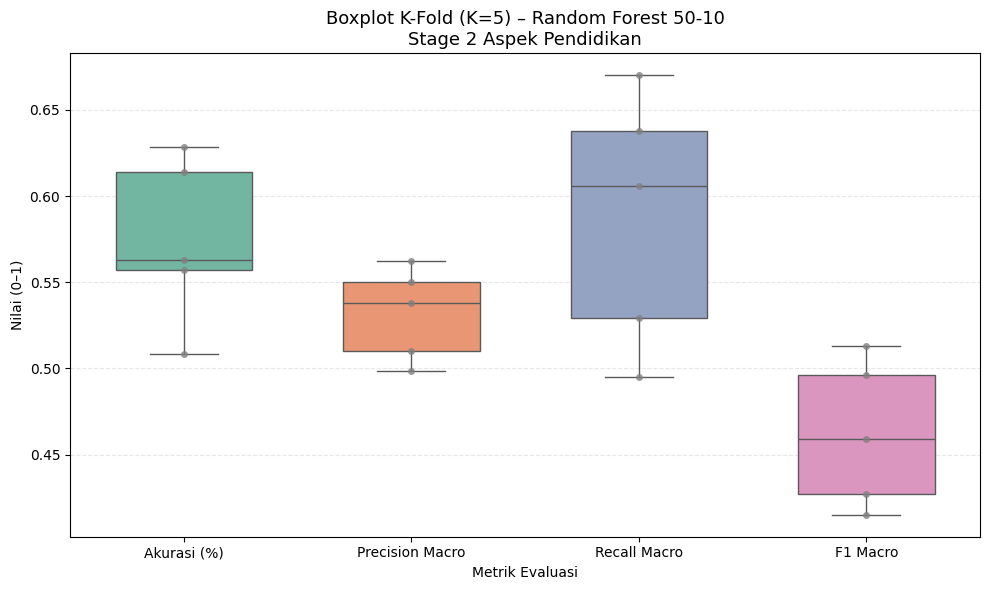

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Pastikan df_kfold_pen_50_10 sudah ada
df_plot = df_kfold_pen_50_10.copy()

# Ubah DataFrame ke format long (supaya boxplot gabungan bisa dibuat)
df_long = df_plot.melt(
    id_vars="Fold",
    value_vars=["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"],
    var_name="Metrik",
    value_name="Nilai"
)

# Supaya akurasi tidak terlalu besar dibanding metrik lain
# convert akurasi (%) ke skala 0–1 agar proporsional (opsional)
df_long["Nilai Normalisasi"] = df_long.apply(
    lambda row: row["Nilai"] / 100 if row["Metrik"] == "Akurasi (%)" else row["Nilai"],
    axis=1
)

# ============================
# BOXPLOT
# ============================
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long,
    palette="Set2",
    width=0.6
)

# Tambahkan titik nilai tiap fold (swarm)
sns.swarmplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long,
    color="gray",
    size=5,
    alpha=0.8
)

plt.title("Boxplot K-Fold (K=5) – Random Forest 50-10\nStage 2 Aspek Pendidikan", fontsize=13)
plt.ylabel("Nilai (0–1)")
plt.xlabel("Metrik Evaluasi")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


# **Stage 2 Aspek Politik**

In [ ]:
# 1) Filter data khusus Politik
mask_pol = df_aspek_bersih["Aspek"] == "Politik"

X_pol = X_bow_lib[mask_pol]   # fitur BoW
y_pol = df_aspek_bersih.loc[mask_pol, "label"].values   # 0 = NonHoaks, 1 = Hoaks

print("Shape data Politik:", X_pol.shape)
print("Distribusi label Politik (0=NonHoaks,1=Hoaks):")
print(pd.Series(y_pol).value_counts())

Shape data Politik: (218, 6275)
Distribusi label Politik (0=NonHoaks,1=Hoaks):
1    195
0     23
Name: count, dtype: int64


# **DATA SPLIT 80:20**

In [ ]:
# 2) Split Train–Test untuk aspek Politik
# ==============================================================

from sklearn.model_selection import train_test_split

X_train_pol, X_test_pol, y_train_pol, y_test_pol = train_test_split(
    X_pol,
    y_pol,
    test_size=0.2,
    random_state=42,
    stratify=y_pol
)

print("\nData Train Politik:", X_train_pol.shape)
print("Data Test  Politik:", X_test_pol.shape)

print("\nDistribusi Train sebelum SMOTE (Politik):")
print(pd.Series(y_train_pol).value_counts())

print("\nDistribusi Test (tanpa SMOTE, Politik):")
print(pd.Series(y_test_pol).value_counts())


Data Train Politik: (174, 6275)
Data Test  Politik: (44, 6275)

Distribusi Train sebelum SMOTE (Politik):
1    156
0     18
Name: count, dtype: int64

Distribusi Test (tanpa SMOTE, Politik):
1    39
0     5
Name: count, dtype: int64


# **SMOTE**

In [ ]:
# ==============================================================
# 3) SMOTE HANYA PADA TRAIN (Politik)
# ==============================================================

from imblearn.over_sampling import SMOTE

smote_pol = SMOTE(random_state=42, k_neighbors=4)
X_train_pol_smote, y_train_pol_smote = smote_pol.fit_resample(
    X_train_pol, y_train_pol
)

print("\nDistribusi Train SETELAH SMOTE (Politik):")
print(pd.Series(y_train_pol_smote).value_counts())


Distribusi Train SETELAH SMOTE (Politik):
1    156
0    156
Name: count, dtype: int64


# **ALGORITMA RANDOM FOREST**

# **HYPERPARAMETER 100-30**


Akurasi TRAIN Stage 2 (Politik): 71.79%
Akurasi TEST  Stage 2 (Politik): 61.36%


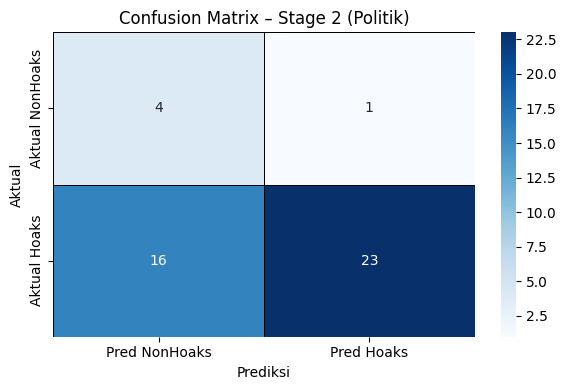


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.2000    0.8000    0.3200         5
       Hoaks     0.9583    0.5897    0.7302        39

    accuracy                         0.6136        44
   macro avg     0.5792    0.6949    0.5251        44
weighted avg     0.8722    0.6136    0.6835        44



/tmp/ipython-input-2230177221.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


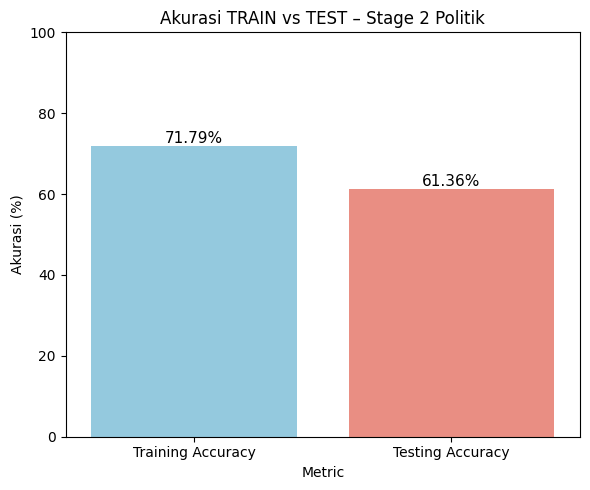

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 50-10**


Akurasi TRAIN Stage 2 (Politik): 63.78%
Akurasi TEST  Stage 2 (Politik): 40.91%


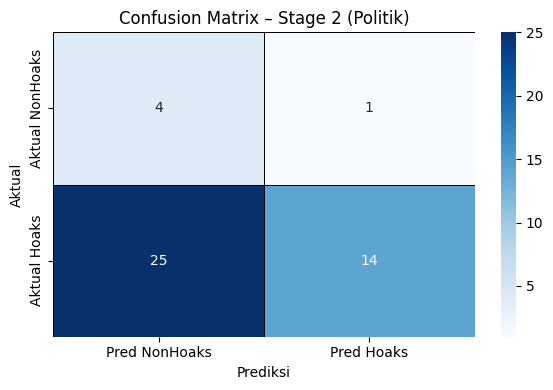


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.1379    0.8000    0.2353         5
       Hoaks     0.9333    0.3590    0.5185        39

    accuracy                         0.4091        44
   macro avg     0.5356    0.5795    0.3769        44
weighted avg     0.8429    0.4091    0.4863        44



/tmp/ipython-input-479154839.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


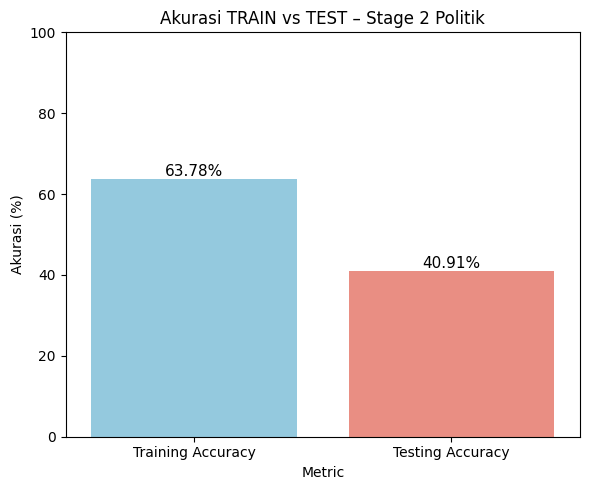

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 60-20**


Akurasi TRAIN Stage 2 (Politik): 70.19%
Akurasi TEST  Stage 2 (Politik): 59.09%


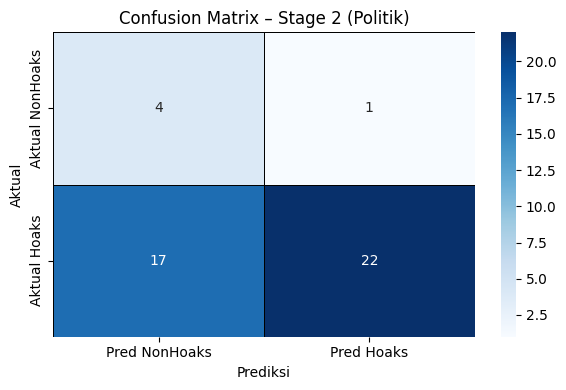


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.1905    0.8000    0.3077         5
       Hoaks     0.9565    0.5641    0.7097        39

    accuracy                         0.5909        44
   macro avg     0.5735    0.6821    0.5087        44
weighted avg     0.8695    0.5909    0.6640        44



/tmp/ipython-input-381087890.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


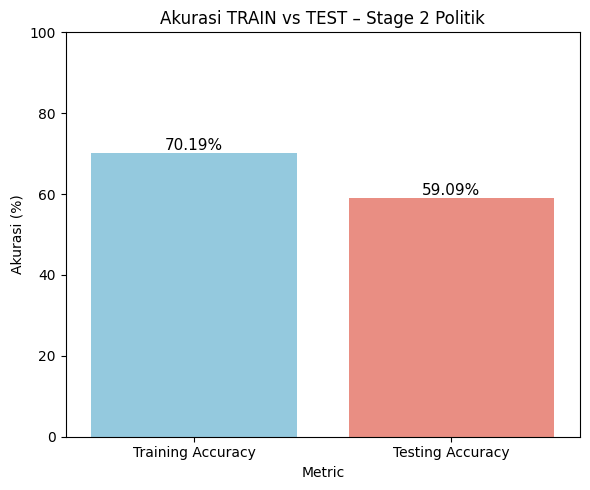

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=60,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 70-30**


Akurasi TRAIN Stage 2 (Politik): 70.19%
Akurasi TEST  Stage 2 (Politik): 59.09%


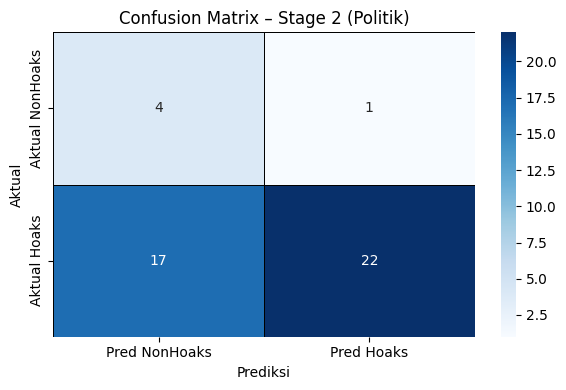


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.1905    0.8000    0.3077         5
       Hoaks     0.9565    0.5641    0.7097        39

    accuracy                         0.5909        44
   macro avg     0.5735    0.6821    0.5087        44
weighted avg     0.8695    0.5909    0.6640        44



/tmp/ipython-input-101427429.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


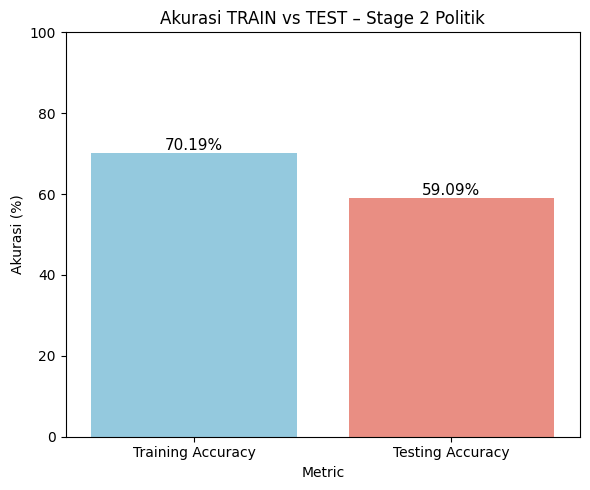

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=70,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 80-30**


Akurasi TRAIN Stage 2 (Politik): 70.19%
Akurasi TEST  Stage 2 (Politik): 59.09%


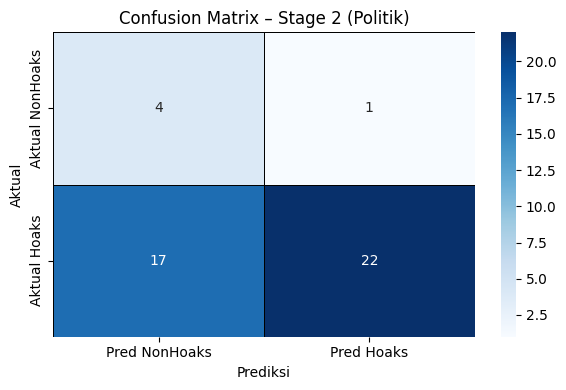


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.1905    0.8000    0.3077         5
       Hoaks     0.9565    0.5641    0.7097        39

    accuracy                         0.5909        44
   macro avg     0.5735    0.6821    0.5087        44
weighted avg     0.8695    0.5909    0.6640        44



/tmp/ipython-input-213991138.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


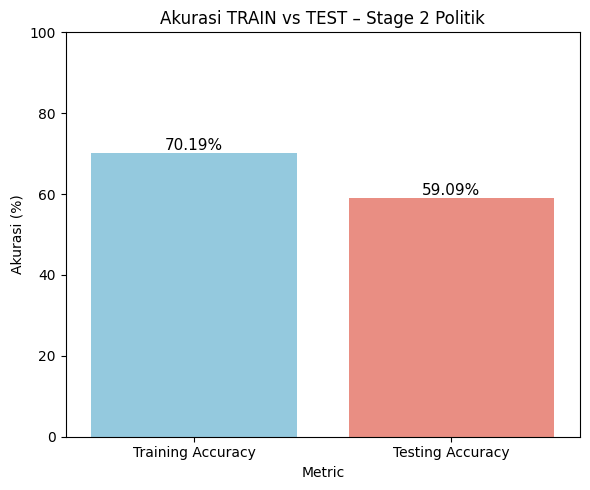

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=80,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 90-20**


Akurasi TRAIN Stage 2 (Politik): 72.44%
Akurasi TEST  Stage 2 (Politik): 61.36%


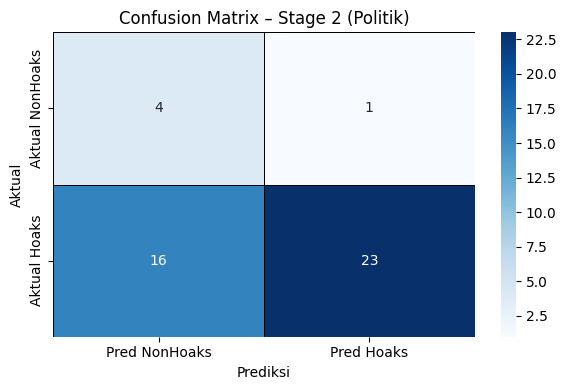


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.2000    0.8000    0.3200         5
       Hoaks     0.9583    0.5897    0.7302        39

    accuracy                         0.6136        44
   macro avg     0.5792    0.6949    0.5251        44
weighted avg     0.8722    0.6136    0.6835        44



/tmp/ipython-input-2529385935.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


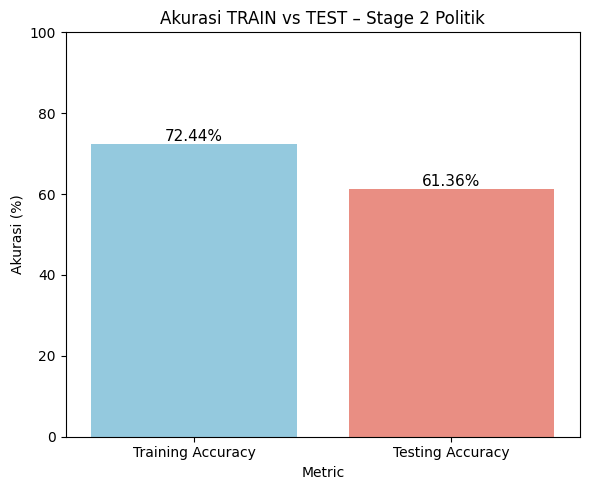

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=90,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 100-10**


Akurasi TRAIN Stage 2 (Politik): 71.79%
Akurasi TEST  Stage 2 (Politik): 61.36%


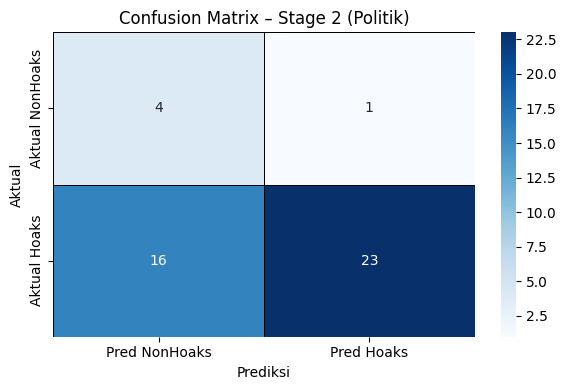


=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===
              precision    recall  f1-score   support

    NonHoaks     0.2000    0.8000    0.3200         5
       Hoaks     0.9583    0.5897    0.7302        39

    accuracy                         0.6136        44
   macro avg     0.5792    0.6949    0.5251        44
weighted avg     0.8722    0.6136    0.6835        44



/tmp/ipython-input-559456579.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


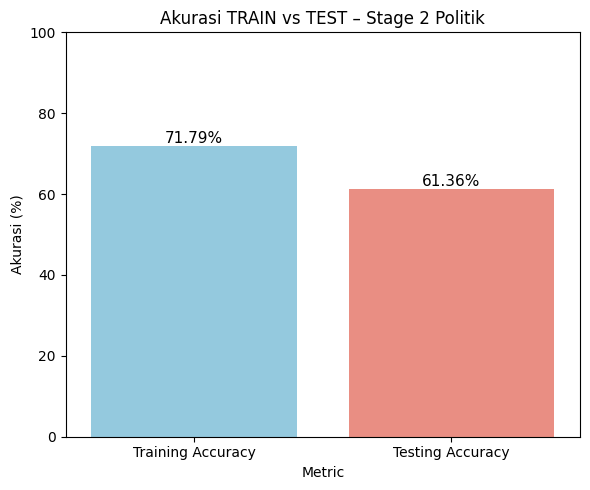

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pol = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Politik)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
y_pred_test_pol  = rf_pol.predict(X_test_pol)

acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

print(f"\nAkurasi TRAIN Stage 2 (Politik): {acc_train_pol*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Politik): {acc_test_pol*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Politik)
# ==============================================================

cm_pol = confusion_matrix(y_test_pol, y_pred_test_pol)

cm_pol_df = pd.DataFrame(
    cm_pol,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_pol_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Politik)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Politik) ===")
print(classification_report(
    y_test_pol,
    y_pred_test_pol,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Politik)
# ==============================================================

df_acc_pol = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_pol * 100, acc_test_pol * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_pol,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Politik")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

**Hasil Seluruh Hyperparameter Aspek Politik**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# =====================================================
# 1) Daftar kombinasi hyperparameter untuk ASPEK POLITIK
#    (sesuai skenario yang sudah kamu jalankan)
# =====================================================
param_list_pol_stage2 = [
    {"n_estimators": 100, "max_depth": 30},  # 100-30
    {"n_estimators": 50,  "max_depth": 10},  # 50-10
    {"n_estimators": 60,  "max_depth": 20},  # 60-20
    {"n_estimators": 70,  "max_depth": 30},  # 70-30
    {"n_estimators": 80,  "max_depth": 30},  # 80-30
    {"n_estimators": 90,  "max_depth": 20},  # 90-20
    {"n_estimators": 100, "max_depth": 10},  # 100-10
]

results_pol_stage2 = []

# =====================================================
# 2) Loop semua kombinasi & hitung metrik evaluasi
# =====================================================
for params in param_list_pol_stage2:

    n_est = params["n_estimators"]
    m_depth = params["max_depth"]

    rf_pol = RandomForestClassifier(
        n_estimators=n_est,
        max_depth=m_depth,
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    # Train
    rf_pol.fit(X_train_pol_smote, y_train_pol_smote)

    # Prediksi
    y_pred_train_pol = rf_pol.predict(X_train_pol_smote)
    y_pred_test_pol  = rf_pol.predict(X_test_pol)

    # Akurasi Train & Test
    acc_train_pol = accuracy_score(y_train_pol_smote, y_pred_train_pol)
    acc_test_pol  = accuracy_score(y_test_pol,      y_pred_test_pol)

    # Precision / Recall / F1 Macro (TEST)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_test_pol,
        y_pred_test_pol,
        average="macro",
        zero_division=0
    )

    # Simpan hasil
    results_pol_stage2.append({
        "n_estimators": n_est,
        "max_depth": m_depth,
        "Akurasi Train (%)": acc_train_pol * 100,
        "Akurasi Test (%)":  acc_test_pol * 100,
        "Precision Macro":   prec_macro,
        "Recall Macro":      rec_macro,
        "F1 Macro":          f1_macro
    })

# =====================================================
# 3) Buat DataFrame tabel rekap
# =====================================================
df_pol_stage2 = pd.DataFrame(results_pol_stage2)

print("Rekap Performa Hyperparameter – Stage 2 Aspek Politik (SMOTE)")
display(df_pol_stage2.round(4))

# =====================================================
# 4) Tampilkan versi yang sudah diurutkan
# =====================================================
df_pol_stage2_sorted = df_pol_stage2.sort_values(
    by="Akurasi Test (%)",
    ascending=False
)

print("\nDiurutkan berdasarkan Akurasi Test tertinggi:")
display(df_pol_stage2_sorted.round(4))


Rekap Performa Hyperparameter – Stage 2 Aspek Politik (SMOTE)


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,71.7949,61.3636,0.5792,0.6949,0.5251
1,50,10,63.7821,40.9091,0.5356,0.5795,0.3769
2,60,20,70.1923,59.0909,0.5735,0.6821,0.5087
3,70,30,70.1923,59.0909,0.5735,0.6821,0.5087
4,80,30,70.1923,59.0909,0.5735,0.6821,0.5087
5,90,20,72.4359,61.3636,0.5792,0.6949,0.5251
6,100,10,71.7949,61.3636,0.5792,0.6949,0.5251



Diurutkan berdasarkan Akurasi Test tertinggi:


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,71.7949,61.3636,0.5792,0.6949,0.5251
5,90,20,72.4359,61.3636,0.5792,0.6949,0.5251
6,100,10,71.7949,61.3636,0.5792,0.6949,0.5251
4,80,30,70.1923,59.0909,0.5735,0.6821,0.5087
2,60,20,70.1923,59.0909,0.5735,0.6821,0.5087
3,70,30,70.1923,59.0909,0.5735,0.6821,0.5087
1,50,10,63.7821,40.9091,0.5356,0.5795,0.3769


# **K-FOLD =5 HYPERPARAMETER 100-30**

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

# ============================================
# 1) Setup K-Fold dan SMOTE untuk Aspek Politik
# ============================================
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

smote_pol_kf = SMOTE(random_state=42, k_neighbors=4)

results_kfold_pol_100_30 = []

fold = 1
for train_idx, val_idx in kfold.split(X_pol, y_pol):
    print(f"\n----- Fold {fold} -----")

    # split data per fold
    X_train_fold = X_pol[train_idx]
    y_train_fold = y_pol[train_idx]
    X_val_fold   = X_pol[val_idx]
    y_val_fold   = y_pol[val_idx]

    print("Ukuran train SMOTE :", X_train_fold.shape, end=" ")
    print("-> setelah SMOTE akan diseimbangkan")
    print("Ukuran validasi    :", X_val_fold.shape)

    # ============================
    # SMOTE hanya di data TRAIN
    # ============================
    X_train_fold_sm, y_train_fold_sm = smote_pol_kf.fit_resample(
        X_train_fold, y_train_fold
    )
    print("Setelah SMOTE train:", X_train_fold_sm.shape)

    # ========================================
    # Model Random Forest (100-30) untuk Politik
    # ========================================
    rf_pol_cv = RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        max_features='sqrt',
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    rf_pol_cv.fit(X_train_fold_sm, y_train_fold_sm)

    # prediksi di data VALIDASI (bukan train)
    y_pred_val = rf_pol_cv.predict(X_val_fold)

    # metrik per fold
    acc = accuracy_score(y_val_fold, y_pred_val)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_val_fold,
        y_pred_val,
        average="macro",
        zero_division=0
    )

    print(f"Akurasi Fold {fold}      : {acc*100:.2f}%")
    print(f"Precision Macro Fold {fold}: {prec_macro:.4f}")
    print(f"Recall Macro Fold {fold}   : {rec_macro:.4f}")
    print(f"F1 Macro Fold {fold}       : {f1_macro:.4f}")

    results_kfold_pol_100_30.append({
        "Fold": fold,
        "Akurasi (%)": acc * 100,
        "Precision Macro": prec_macro,
        "Recall Macro": rec_macro,
        "F1 Macro": f1_macro
    })

    fold += 1

# ============================================
# 2) Rekap hasil K-Fold dalam DataFrame
# ============================================
df_kfold_pol_100_30 = pd.DataFrame(results_kfold_pol_100_30)

print("\n=== Tabel Hasil K-Fold (K=5) – RF 100-30 Aspek Politik ===")
display(df_kfold_pol_100_30.round(4))

print("\n=== Rata-rata K-Fold (K=5) – RF 100-30 Aspek Politik ===")
print(df_kfold_pol_100_30[["Akurasi (%)",
                           "Precision Macro",
                           "Recall Macro",
                           "F1 Macro"]].mean().round(4))



----- Fold 1 -----
Ukuran train SMOTE : (174, 6275) -> setelah SMOTE akan diseimbangkan
Ukuran validasi    : (44, 6275)
Setelah SMOTE train: (312, 6275)
Akurasi Fold 1      : 36.36%
Precision Macro Fold 1: 0.4488
Recall Macro Fold 1   : 0.3795
F1 Macro Fold 1       : 0.3125

----- Fold 2 -----
Ukuran train SMOTE : (174, 6275) -> setelah SMOTE akan diseimbangkan
Ukuran validasi    : (44, 6275)
Setelah SMOTE train: (312, 6275)
Akurasi Fold 2      : 54.55%
Precision Macro Fold 2: 0.5631
Recall Macro Fold 2   : 0.6564
F1 Macro Fold 2       : 0.4762

----- Fold 3 -----
Ukuran train SMOTE : (174, 6275) -> setelah SMOTE akan diseimbangkan
Ukuran validasi    : (44, 6275)
Setelah SMOTE train: (312, 6275)
Akurasi Fold 3      : 27.27%
Precision Macro Fold 3: 0.5016
Recall Macro Fold 3   : 0.5026
F1 Macro Fold 3       : 0.2667

----- Fold 4 -----
Ukuran train SMOTE : (175, 6275) -> setelah SMOTE akan diseimbangkan
Ukuran validasi    : (43, 6275)
Setelah SMOTE train: (312, 6275)
Akurasi Fold 4    

,Fold,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,1,36.3636,0.4488,0.3795,0.3125
1,2,54.5455,0.5631,0.6564,0.4762
2,3,27.2727,0.5016,0.5026,0.2667
3,4,44.1860,0.4513,0.3558,0.3385
4,5,60.4651,0.5204,0.5577,0.4645



=== Rata-rata K-Fold (K=5) – RF 100-30 Aspek Politik ===
Akurasi (%)        44.5666
Precision Macro     0.4970
Recall Macro        0.4904
F1 Macro            0.3717
dtype: float64


/tmp/ipython-input-267892450.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


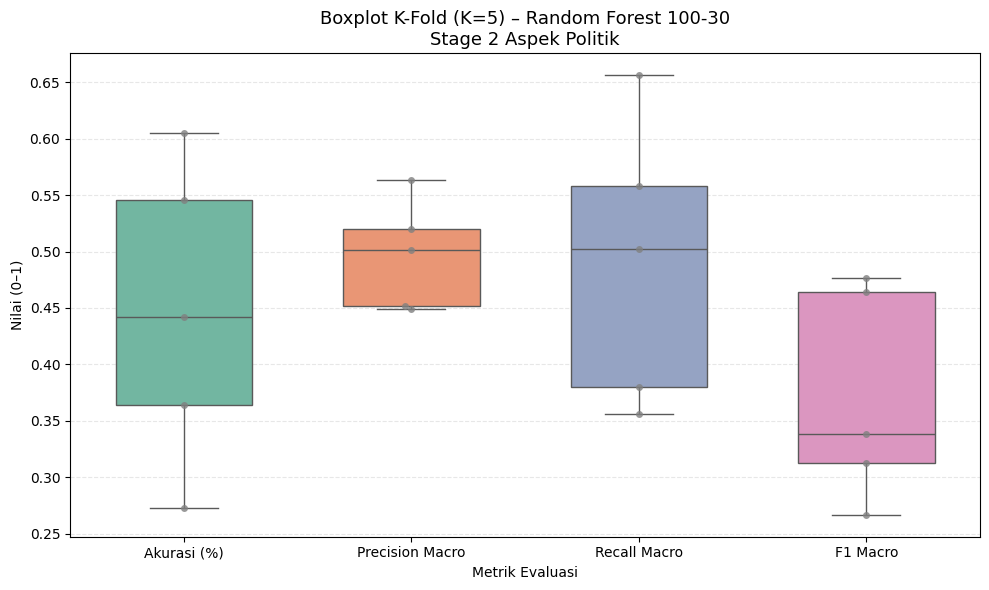

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Pastikan df_kfold_pol_100_30 sudah ada (hasil K-Fold aspek Politik 100-30)
df_plot_pol = df_kfold_pol_100_30.copy()

# Ubah ke format long
df_long_pol = df_plot_pol.melt(
    id_vars="Fold",
    value_vars=["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"],
    var_name="Metrik",
    value_name="Nilai"
)

# Normalisasi: Akurasi (%) -> 0–1, metrik lain tetap
df_long_pol["Nilai Normalisasi"] = df_long_pol.apply(
    lambda row: row["Nilai"] / 100 if row["Metrik"] == "Akurasi (%)" else row["Nilai"],
    axis=1
)

# ============================
# BOXPLOT K-FOLD POLITIK
# ============================
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long_pol,
    palette="Set2",
    width=0.6
)

# Titik per fold
sns.swarmplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long_pol,
    color="gray",
    size=5,
    alpha=0.8
)

plt.title("Boxplot K-Fold (K=5) – Random Forest 100-30\nStage 2 Aspek Politik", fontsize=13)
plt.ylabel("Nilai (0–1)")
plt.xlabel("Metrik Evaluasi")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


# **STAGE 2 ASPEK BENCANA ALAM**

In [ ]:
# 1) Filter data khusus Bencana Alam
mask_ben = df_aspek_bersih["Aspek"] == "Bencana"

X_ben = X_bow_lib[mask_ben]   # fitur BoW
y_ben = df_aspek_bersih.loc[mask_ben, "label"].values   # 0 = NonHoaks, 1 = Hoaks

print("Shape data Bencana Alam:", X_ben.shape)
print("Distribusi label Bencana (0=NonHoaks,1=Hoaks):")
print(pd.Series(y_ben).value_counts())

Shape data Bencana Alam: (66, 6275)
Distribusi label Bencana (0=NonHoaks,1=Hoaks):
1    60
0     6
Name: count, dtype: int64


# **SPLIT DATA 80:20**

In [ ]:
# ==============================================================
# 2) Split Train–Test untuk aspek Bencana
# ==============================================================

from sklearn.model_selection import train_test_split

X_train_ben, X_test_ben, y_train_ben, y_test_ben = train_test_split(
    X_ben,
    y_ben,
    test_size=0.2,
    random_state=42,
    stratify=y_ben
)

print("\nData Train Bencana:", X_train_ben.shape)
print("Data Test  Bencana:", X_test_ben.shape)

print("\nDistribusi Train sebelum SMOTE (Bencana):")
print(pd.Series(y_train_ben).value_counts())

print("\nDistribusi Test (tanpa SMOTE, Bencana):")
print(pd.Series(y_test_ben).value_counts())


Data Train Bencana: (52, 6275)
Data Test  Bencana: (14, 6275)

Distribusi Train sebelum SMOTE (Bencana):
1    47
0     5
Name: count, dtype: int64

Distribusi Test (tanpa SMOTE, Bencana):
1    13
0     1
Name: count, dtype: int64


# **SMOTE**

In [ ]:
# ==============================================================
# 3) SMOTE HANYA PADA TRAIN (Bencana)
# ==============================================================

from imblearn.over_sampling import SMOTE

smote_ben = SMOTE(random_state=42, k_neighbors=4)
X_train_ben_smote, y_train_ben_smote = smote_ben.fit_resample(
    X_train_ben, y_train_ben
)

print("\nDistribusi Train SETELAH SMOTE (Bencana):")
print(pd.Series(y_train_ben_smote).value_counts())


Distribusi Train SETELAH SMOTE (Bencana):
1    47
0    47
Name: count, dtype: int64


# **ALGORITMA RANDOM FOREST**

# **HYPERPARAMETER 100-30**


Akurasi TRAIN Stage 2 (Bencana): 93.62%
Akurasi TEST  Stage 2 (Bencana): 71.43%


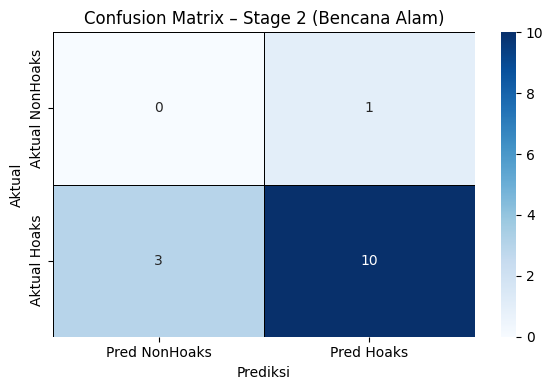


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.9091    0.7692    0.8333        13

    accuracy                         0.7143        14
   macro avg     0.4545    0.3846    0.4167        14
weighted avg     0.8442    0.7143    0.7738        14



/tmp/ipython-input-2881862327.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


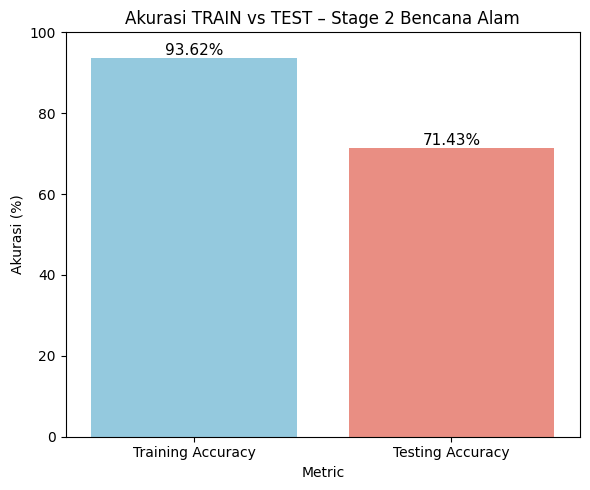

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 50-10**


Akurasi TRAIN Stage 2 (Bencana): 87.23%
Akurasi TEST  Stage 2 (Bencana): 50.00%


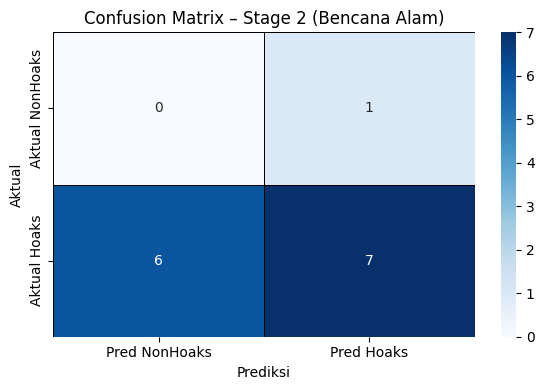


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.8750    0.5385    0.6667        13

    accuracy                         0.5000        14
   macro avg     0.4375    0.2692    0.3333        14
weighted avg     0.8125    0.5000    0.6190        14



/tmp/ipython-input-3959242127.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


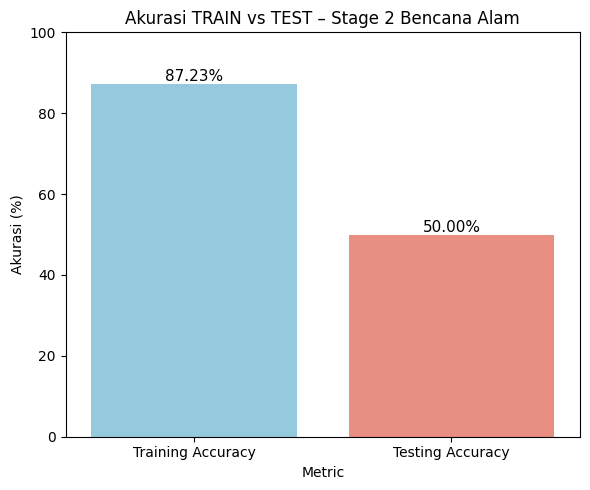

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 60-20**


Akurasi TRAIN Stage 2 (Bencana): 87.23%
Akurasi TEST  Stage 2 (Bencana): 50.00%


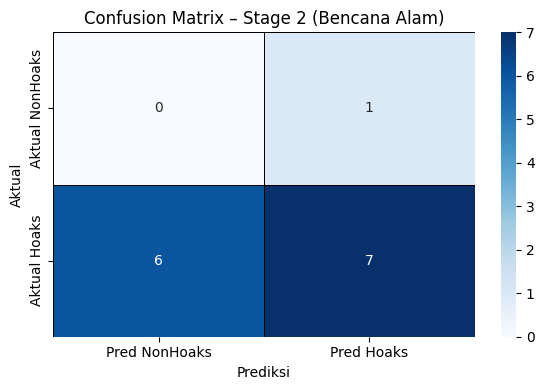


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.8750    0.5385    0.6667        13

    accuracy                         0.5000        14
   macro avg     0.4375    0.2692    0.3333        14
weighted avg     0.8125    0.5000    0.6190        14



/tmp/ipython-input-352085982.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


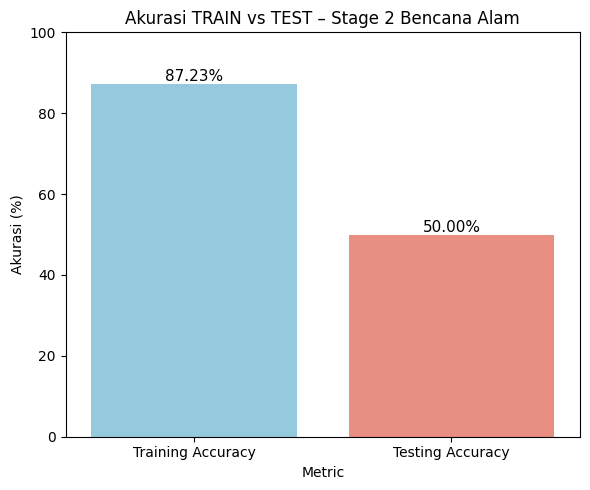

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=60,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 70-30**


Akurasi TRAIN Stage 2 (Bencana): 90.43%
Akurasi TEST  Stage 2 (Bencana): 64.29%


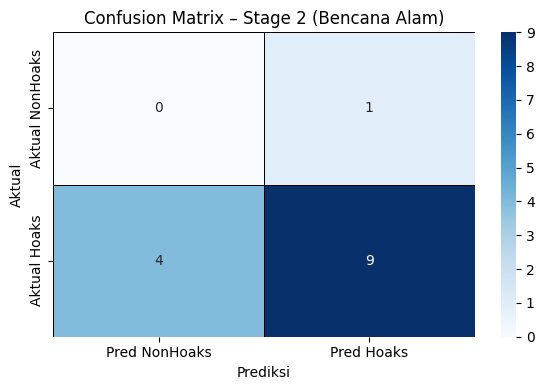


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.9000    0.6923    0.7826        13

    accuracy                         0.6429        14
   macro avg     0.4500    0.3462    0.3913        14
weighted avg     0.8357    0.6429    0.7267        14



/tmp/ipython-input-2466595351.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


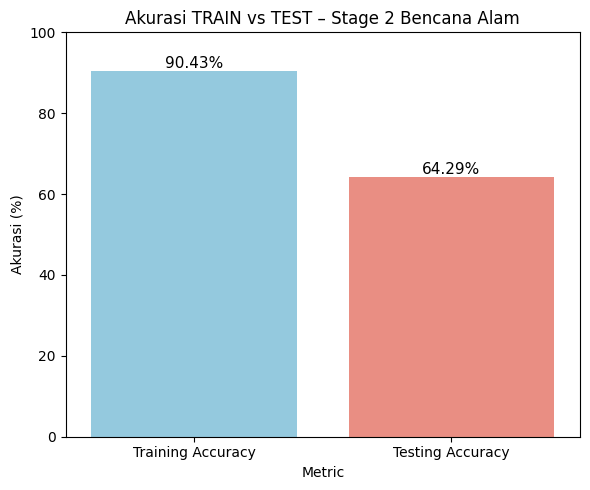

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=70,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 80-30**


Akurasi TRAIN Stage 2 (Bencana): 93.62%
Akurasi TEST  Stage 2 (Bencana): 64.29%


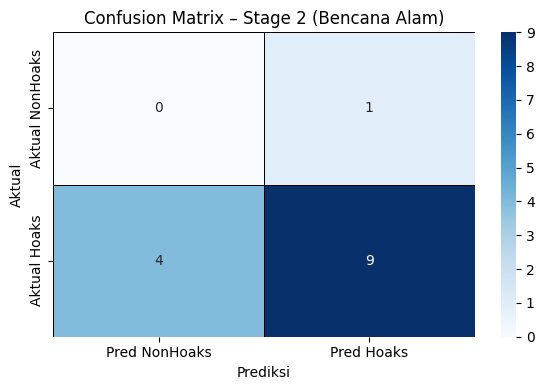


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.9000    0.6923    0.7826        13

    accuracy                         0.6429        14
   macro avg     0.4500    0.3462    0.3913        14
weighted avg     0.8357    0.6429    0.7267        14



/tmp/ipython-input-1933922191.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


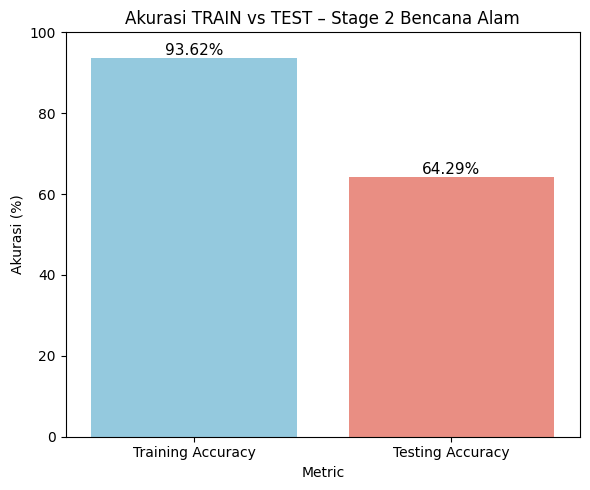

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=80,
    max_depth=30,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 90-20**


Akurasi TRAIN Stage 2 (Bencana): 94.68%
Akurasi TEST  Stage 2 (Bencana): 64.29%


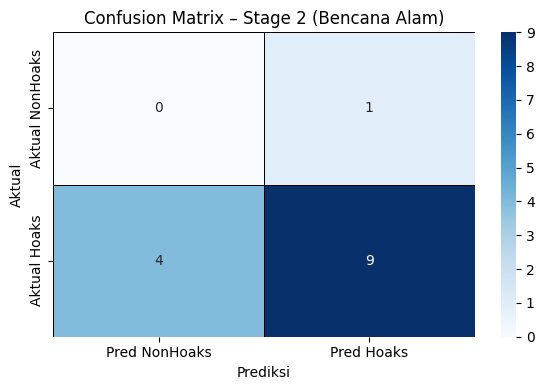


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.9000    0.6923    0.7826        13

    accuracy                         0.6429        14
   macro avg     0.4500    0.3462    0.3913        14
weighted avg     0.8357    0.6429    0.7267        14



/tmp/ipython-input-3848955542.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


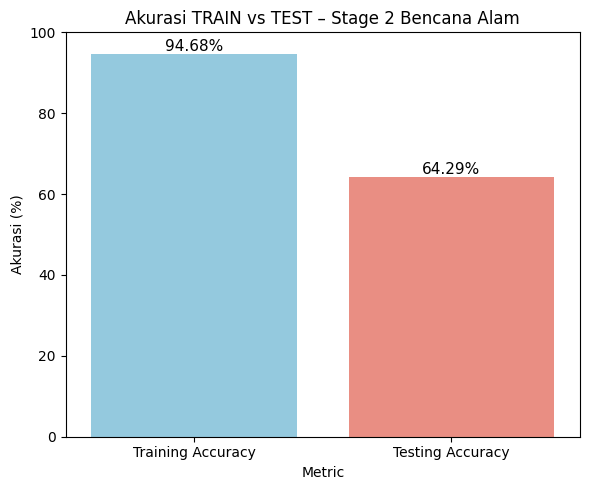

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=90,
    max_depth=20,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **HYPERPARAMETER 100-10**


Akurasi TRAIN Stage 2 (Bencana): 93.62%
Akurasi TEST  Stage 2 (Bencana): 71.43%


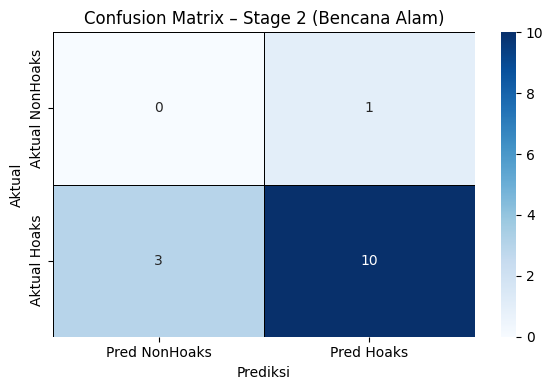


=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===
              precision    recall  f1-score   support

    NonHoaks     0.0000    0.0000    0.0000         1
       Hoaks     0.9091    0.7692    0.8333        13

    accuracy                         0.7143        14
   macro avg     0.4545    0.3846    0.4167        14
weighted avg     0.8442    0.7143    0.7738        14



/tmp/ipython-input-1017010760.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


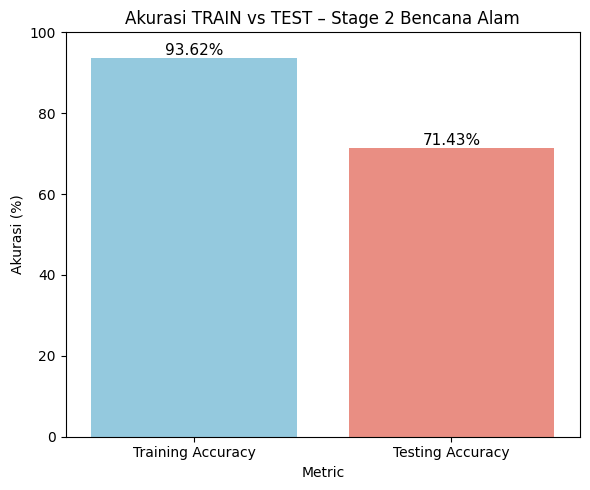

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ben = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    max_features='sqrt',
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

# ==============================================================
# 5) Prediksi & Akurasi (Bencana)
# ==============================================================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
y_pred_test_ben  = rf_ben.predict(X_test_ben)

acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

print(f"\nAkurasi TRAIN Stage 2 (Bencana): {acc_train_ben*100:.2f}%")
print(f"Akurasi TEST  Stage 2 (Bencana): {acc_test_ben*100:.2f}%")

# ==============================================================
# 6) Confusion Matrix (Bencana)
# ==============================================================

cm_ben = confusion_matrix(y_test_ben, y_pred_test_ben)

cm_ben_df = pd.DataFrame(
    cm_ben,
    index=["Aktual NonHoaks", "Aktual Hoaks"],
    columns=["Pred NonHoaks", "Pred Hoaks"]
)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ben_df, annot=True, fmt="d", cmap="Blues",
            linewidths=0.5, linecolor="black")
plt.title("Confusion Matrix – Stage 2 (Bencana Alam)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI STAGE 2 (Bencana Alam) ===")
print(classification_report(
    y_test_ben,
    y_pred_test_ben,
    target_names=["NonHoaks", "Hoaks"],
    digits=4,
    zero_division=0
))

# ==============================================================
# 7) Grafik akurasi TRAIN vs TEST (Bencana)
# ==============================================================

df_acc_ben = pd.DataFrame({
    "Metric": ["Training Accuracy", "Testing Accuracy"],
    "Accuracy": [acc_train_ben * 100, acc_test_ben * 100]
})

plt.figure(figsize=(6,5))
ax = sns.barplot(
    data=df_acc_ben,
    x="Metric",
    y="Accuracy",
    palette=["skyblue", "salmon"]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi TRAIN vs TEST – Stage 2 Bencana Alam")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width()/2., h),
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# **Menampilkan Hasil Keseluruhan tiap hyperparameter**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# =====================================================
# 1) Daftar kombinasi hyperparameter untuk BENCANA ALAM
#    (sesuai skenario yang sudah kamu jalankan)
# =====================================================
param_list_ben_stage2 = [
    {"n_estimators": 100, "max_depth": 30},  # 100-30
    {"n_estimators": 50,  "max_depth": 10},  # 50-10
    {"n_estimators": 60,  "max_depth": 20},  # 60-20
    {"n_estimators": 70,  "max_depth": 30},  # 70-30
    {"n_estimators": 80,  "max_depth": 30},  # 80-30
    {"n_estimators": 90,  "max_depth": 20},  # 90-20
    {"n_estimators": 100, "max_depth": 10},  # 100-10
]

results_ben_stage2 = []

# =====================================================
# 2) Loop semua kombinasi & hitung metrik evaluasi
# =====================================================
for params in param_list_ben_stage2:

    n_est = params["n_estimators"]
    m_depth = params["max_depth"]

    rf_ben = RandomForestClassifier(
        n_estimators=n_est,
        max_depth=m_depth,
        max_features='sqrt',
        min_samples_split=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    # Train
    rf_ben.fit(X_train_ben_smote, y_train_ben_smote)

    # Prediksi
    y_pred_train_ben = rf_ben.predict(X_train_ben_smote)
    y_pred_test_ben  = rf_ben.predict(X_test_ben)

    # Akurasi Train & Test
    acc_train_ben = accuracy_score(y_train_ben_smote, y_pred_train_ben)
    acc_test_ben  = accuracy_score(y_test_ben,      y_pred_test_ben)

    # Precision / Recall / F1 Macro (TEST)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_test_ben,
        y_pred_test_ben,
        average="macro",
        zero_division=0
    )

    # Simpan hasil
    results_ben_stage2.append({
        "n_estimators": n_est,
        "max_depth": m_depth,
        "Akurasi Train (%)": acc_train_ben * 100,
        "Akurasi Test (%)":  acc_test_ben * 100,
        "Precision Macro":   prec_macro,
        "Recall Macro":      rec_macro,
        "F1 Macro":          f1_macro
    })

# =====================================================
# 3) Buat DataFrame tabel rekap
# =====================================================
df_ben_stage2 = pd.DataFrame(results_ben_stage2)

print("Rekap Performa Hyperparameter – Stage 2 Aspek Bencana Alam (SMOTE)")
display(df_ben_stage2.round(4))

# =====================================================
# 4) Tampilkan versi yang sudah diurutkan
# =====================================================
df_ben_stage2_sorted = df_ben_stage2.sort_values(
    by="Akurasi Test (%)",
    ascending=False
)

print("\nDiurutkan berdasarkan Akurasi Test tertinggi:")
display(df_ben_stage2_sorted.round(4))


Rekap Performa Hyperparameter – Stage 2 Aspek Bencana Alam (SMOTE)


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,93.6170,71.4286,0.4545,0.3846,0.4167
1,50,10,87.2340,50.0000,0.4375,0.2692,0.3333
2,60,20,87.2340,50.0000,0.4375,0.2692,0.3333
3,70,30,90.4255,64.2857,0.4500,0.3462,0.3913
4,80,30,93.6170,64.2857,0.4500,0.3462,0.3913
5,90,20,94.6809,64.2857,0.4500,0.3462,0.3913
6,100,10,93.6170,71.4286,0.4545,0.3846,0.4167



Diurutkan berdasarkan Akurasi Test tertinggi:


,n_estimators,max_depth,Akurasi Train (%),Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,93.6170,71.4286,0.4545,0.3846,0.4167
6,100,10,93.6170,71.4286,0.4545,0.3846,0.4167
3,70,30,90.4255,64.2857,0.4500,0.3462,0.3913
4,80,30,93.6170,64.2857,0.4500,0.3462,0.3913
5,90,20,94.6809,64.2857,0.4500,0.3462,0.3913
2,60,20,87.2340,50.0000,0.4375,0.2692,0.3333
1,50,10,87.2340,50.0000,0.4375,0.2692,0.3333


**K-FOLD = 5 PADA  HYPERPARAMETER 100-10**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from imblearn.over_sampling import SMOTE

# ============================================
# K-FOLD (K=5) – Stage 2 Aspek Bencana Alam
# Hyperparameter: n_estimators=100, max_depth=10
# ============================================

K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

# SMOTE sama seperti skenario sebelumnya (k_neighbors=4) - REDUCED TO 3
smote_ben_kfold = SMOTE(random_state=42, k_neighbors=3) # Changed k_neighbors from 4 to 3

results_kfold_ben_100_10 = []

fold_no = 1
for train_idx, val_idx in skf.split(X_ben, y_ben):
    # Split data per fold
    X_train_fold = X_ben[train_idx]
    X_val_fold   = X_ben[val_idx]
    y_train_fold = y_ben[train_idx]
    y_val_fold   = y_ben[val_idx]

    # SMOTE hanya pada data train di fold ini
    X_train_smote_fold, y_train_smote_fold = smote_ben_kfold.fit_resample(
        X_train_fold, y_train_fold
    )

    # Inisialisasi model Random Forest (100-10)
    rf_ben_kfold = RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        max_features='sqrt',
        min_samples_split=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    # Training
    rf_ben_kfold.fit(X_train_smote_fold, y_train_smote_fold)

    # Prediksi pada data validasi (fold test)
    y_pred_val = rf_ben_kfold.predict(X_val_fold)

    # Hitung metrik
    acc_val = accuracy_score(y_val_fold, y_pred_val) * 100
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_val_fold,
        y_pred_val,
        average="macro",
        zero_division=0
    )

    # Simpan hasil per fold
    results_kfold_ben_100_10.append({
        "Fold": fold_no,
        "Akurasi (%)": acc_val,
        "Precision Macro": prec_macro,
        "Recall Macro": rec_macro,
        "F1 Macro": f1_macro
    })

    print(f"Fold {fold_no} selesai. Akurasi: {acc_val:.2f}%")
    fold_no += 1

# ============================================
# Rekap hasil K-Fold dalam DataFrame
# ============================================

df_kfold_ben_100_10 = pd.DataFrame(results_kfold_ben_100_10)

# Tambahkan baris rata-rata
mean_row = {
    "Fold": "Rata-rata",
    "Akurasi (%)": df_kfold_ben_100_10["Akurasi (%)"].mean(),
    "Precision Macro": df_kfold_ben_100_10["Precision Macro"].mean(),
    "Recall Macro": df_kfold_ben_100_10["Recall Macro"].mean(),
    "F1 Macro": df_kfold_ben_100_10["F1 Macro"].mean()
}

df_kfold_ben_100_10 = pd.concat(
    [df_kfold_ben_100_10, pd.DataFrame([mean_row])],
    ignore_index=True
)

print("\nRekap Hasil K-Fold (K=5) – Stage 2 Aspek Bencana Alam (100-10):")
display(df_kfold_ben_100_10.round(4))


Fold 1 selesai. Akurasi: 64.29%
Fold 2 selesai. Akurasi: 53.85%
Fold 3 selesai. Akurasi: 69.23%
Fold 4 selesai. Akurasi: 46.15%
Fold 5 selesai. Akurasi: 23.08%

Rekap Hasil K-Fold (K=5) – Stage 2 Aspek Bencana Alam (100-10):


,Fold,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,1,64.2857,0.6429,0.7917,0.5906
1,2,53.8462,0.5714,0.7500,0.4583
2,3,69.2308,0.4500,0.3750,0.4091
3,4,46.1538,0.5625,0.7083,0.4052
4,5,23.0769,0.3750,0.1250,0.1875
5,Rata-rata,51.3187,0.5204,0.5500,0.4102


/tmp/ipython-input-4092534236.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


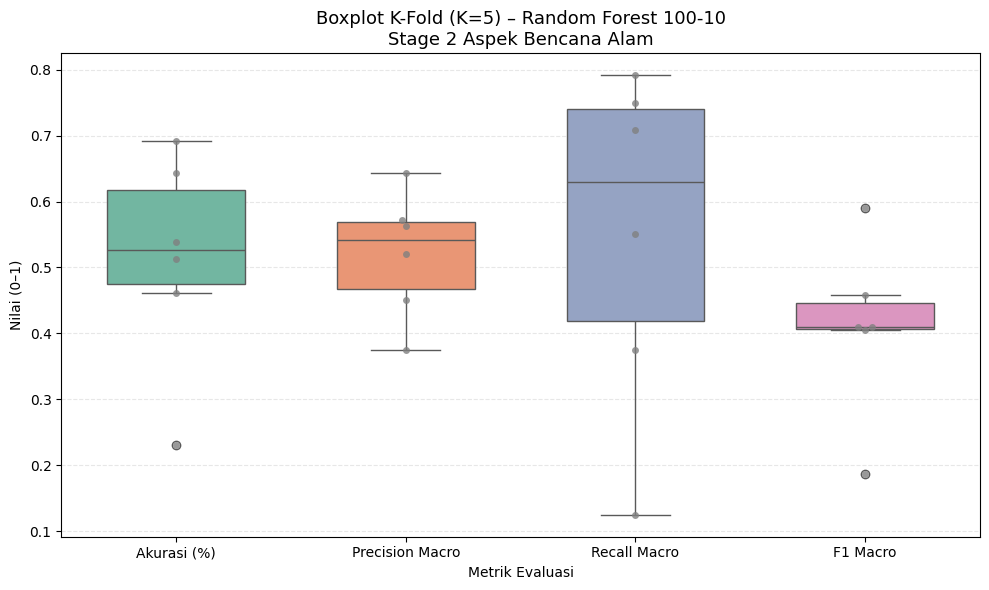

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Pastikan df_kfold_ben_100_10 sudah ada (hasil K-Fold Bencana Alam 100-10)
df_plot = df_kfold_ben_100_10.copy()

# Ubah DataFrame ke format long (supaya boxplot gabungan bisa dibuat)
df_long = df_plot.melt(
    id_vars="Fold",
    value_vars=["Akurasi (%)", "Precision Macro", "Recall Macro", "F1 Macro"],
    var_name="Metrik",
    value_name="Nilai"
)

# Supaya akurasi (%) tidak terlalu besar dibanding metrik lain:
# konversi akurasi ke skala 0–1 (opsional, tapi konsisten dengan contoh)
df_long["Nilai Normalisasi"] = df_long.apply(
    lambda row: row["Nilai"] / 100 if row["Metrik"] == "Akurasi (%)" else row["Nilai"],
    axis=1
)

# ============================
# BOXPLOT
# ============================
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long,
    palette="Set2",
    width=0.6
)

# Tambahkan titik nilai tiap fold (swarm)
sns.swarmplot(
    x="Metrik",
    y="Nilai Normalisasi",
    data=df_long,
    color="gray",
    size=5,
    alpha=0.8
)

plt.title("Boxplot K-Fold (K=5) – Random Forest 100-10\nStage 2 Aspek Bencana Alam", fontsize=13)
plt.ylabel("Nilai (0–1)")
plt.xlabel("Metrik Evaluasi")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


,n_estimators,max_depth,Akurasi Test (%),Precision Macro,Recall Macro,F1 Macro
0,100,30,65.822040,0.524717,0.561859,0.481517
1,100,10,65.640881,0.524253,0.560855,0.480335
2,90,20,63.259928,0.522738,0.548035,0.471881
3,80,30,62.502353,0.517848,0.535506,0.463645
4,70,30,62.321193,0.520393,0.542757,0.465238
5,60,20,57.921607,0.520091,0.527380,0.450932
6,50,10,52.766798,0.500805,0.473446,0.404254


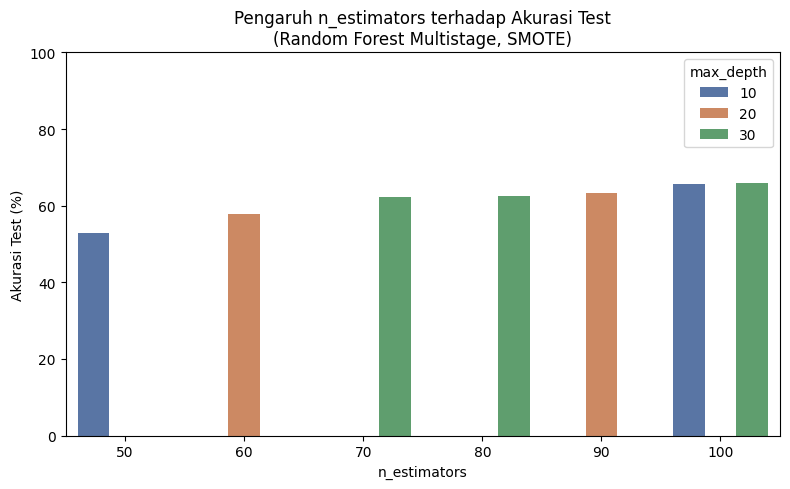

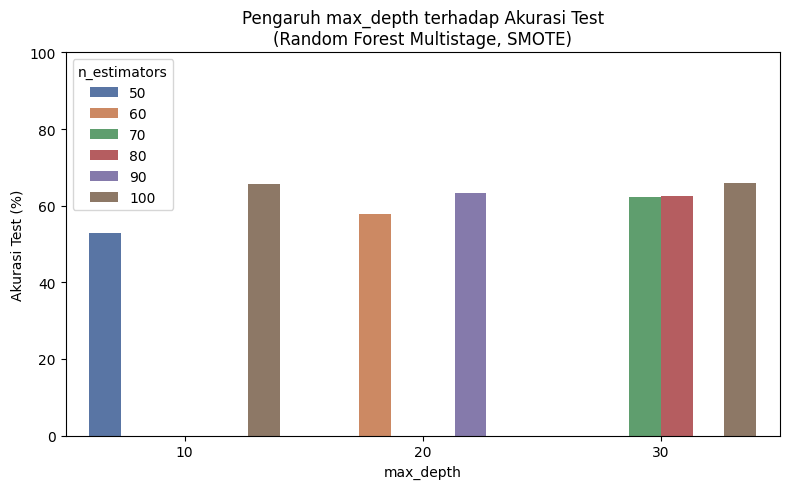

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the results from Stage 2 aspects into one DataFrame
# (Assuming df_pen_stage2, df_pol_stage2, df_ben_stage2 are already defined from previous cells)
combined_stage2_results = pd.concat([df_pen_stage2, df_pol_stage2, df_ben_stage2], ignore_index=True)

# Group by hyperparameters and calculate the mean of the metrics
df_results_ms = combined_stage2_results.groupby(['n_estimators', 'max_depth'], as_index=False)[[
    'Akurasi Test (%)', 'Precision Macro', 'Recall Macro', 'F1 Macro'
]].mean()

df_results_ms = df_results_ms.sort_values(by='Akurasi Test (%)', ascending=False).reset_index(drop=True)
display(df_results_ms)

# =====================================================
# 2. Pengaruh n_estimators terhadap Akurasi Test
# =====================================================

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_results_ms,
    x="n_estimators",
    y="Akurasi Test (%)",
    hue="max_depth",
    palette="deep"
)

plt.title("Pengaruh n_estimators terhadap Akurasi Test\n(Random Forest Multistage, SMOTE)")
plt.xlabel("n_estimators")
plt.ylabel("Akurasi Test (%)")
plt.ylim(0, 100)
plt.legend(title="max_depth")
plt.tight_layout()
plt.show()

# =====================================================
# 3. Pengaruh max_depth terhadap Akurasi Test
# =====================================================

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_results_ms,
    x="max_depth",
    y="Akurasi Test (%)",
    hue="n_estimators",
    palette="deep"
)

plt.title("Pengaruh max_depth terhadap Akurasi Test\n(Random Forest Multistage, SMOTE)")
plt.xlabel("max_depth")
plt.ylabel("Akurasi Test (%)")
plt.ylim(0, 100)
plt.legend(title="n_estimators")
plt.tight_layout()
plt.show()

# **RATA-RATA MULTISTAGE**

In [ ]:
import pandas as pd

# ======================================================
# 1) ISI DATA STAGE 2 (pakai nilai yang sudah kamu catat)
#    + SEKALIGUS SIMPAN n_estimators & max_depth
# ======================================================

data_stage2 = [
    # ================ ASPEK PENDIDIKAN =================
    {"aspek": "Pendidikan", "n_estimators": 100, "max_depth": 30,
     "accuracy": 0.6467, "precision": 0.5404, "recall": 0.6061, "f1": 0.5028},
    {"aspek": "Pendidikan", "n_estimators": 50,  "max_depth": 10,
     "accuracy": 0.6739, "precision": 0.5293, "recall": 0.5716, "f1": 0.5025},
    {"aspek": "Pendidikan", "n_estimators": 60,  "max_depth": 20,
     "accuracy": 0.6467, "precision": 0.5493, "recall": 0.6309, "f1": 0.5108},
    {"aspek": "Pendidikan", "n_estimators": 70,  "max_depth": 30,
     "accuracy": 0.6359, "precision": 0.5377, "recall": 0.6001, "f1": 0.4957},
    {"aspek": "Pendidikan", "n_estimators": 80,  "max_depth": 30,
     "accuracy": 0.6413, "precision": 0.5398, "recall": 0.6031, "f1": 0.4993},
    {"aspek": "Pendidikan", "n_estimators": 90,  "max_depth": 20,
     "accuracy": 0.6413, "precision": 0.5320, "recall": 0.5783, "f1": 0.4899},
    {"aspek": "Pendidikan", "n_estimators": 100, "max_depth": 10,
     "accuracy": 0.6413, "precision": 0.5398, "recall": 0.6031, "f1": 0.4993},

    # ================== ASPEK POLITIK ==================
    {"aspek": "Politik", "n_estimators": 100, "max_depth": 30,
     "accuracy": 0.6136, "precision": 0.5792, "recall": 0.6949, "f1": 0.5251},
    {"aspek": "Politik", "n_estimators": 50,  "max_depth": 10,
     "accuracy": 0.4091, "precision": 0.5356, "recall": 0.5795, "f1": 0.3769},
    {"aspek": "Politik", "n_estimators": 60,  "max_depth": 20,
     "accuracy": 0.5909, "precision": 0.5735, "recall": 0.6821, "f1": 0.5087},
    {"aspek": "Politik", "n_estimators": 70,  "max_depth": 30,
     "accuracy": 0.5909, "precision": 0.5735, "recall": 0.6821, "f1": 0.5087},
    {"aspek": "Politik", "n_estimators": 80,  "max_depth": 30,
     "accuracy": 0.5909, "precision": 0.5735, "recall": 0.6821, "f1": 0.5087},
    {"aspek": "Politik", "n_estimators": 90,  "max_depth": 20,
     "accuracy": 0.6136, "precision": 0.5792, "recall": 0.6949, "f1": 0.5251},
    {"aspek": "Politik", "n_estimators": 100, "max_depth": 10,
     "accuracy": 0.6136, "precision": 0.5792, "recall": 0.6949, "f1": 0.5251},

    # ============== ASPEK BENCANA ALAM =================
    {"aspek": "Bencana Alam", "n_estimators": 100, "max_depth": 30,
     "accuracy": 0.7143, "precision": 0.4545, "recall": 0.3846, "f1": 0.4167},
    {"aspek": "Bencana Alam", "n_estimators": 50,  "max_depth": 10,
     "accuracy": 0.5000, "precision": 0.4375, "recall": 0.2692, "f1": 0.3333},
    {"aspek": "Bencana Alam", "n_estimators": 60,  "max_depth": 20,
     "accuracy": 0.5000, "precision": 0.4375, "recall": 0.2692, "f1": 0.3333},
    {"aspek": "Bencana Alam", "n_estimators": 70,  "max_depth": 30,
     "accuracy": 0.6429, "precision": 0.4500, "recall": 0.3462, "f1": 0.3913},
    {"aspek": "Bencana Alam", "n_estimators": 80,  "max_depth": 30,
     "accuracy": 0.6429, "precision": 0.4500, "recall": 0.3462, "f1": 0.3913},
    {"aspek": "Bencana Alam", "n_estimators": 90,  "max_depth": 20,
     "accuracy": 0.7143, "precision": 0.4545, "recall": 0.3846, "f1": 0.4167},
    {"aspek": "Bencana Alam", "n_estimators": 100, "max_depth": 10,
     "accuracy": 0.7143, "precision": 0.4545, "recall": 0.3846, "f1": 0.4167},
]

df = pd.DataFrame(data_stage2)

# ======================================================
# 2) TABEL SEMUA HYPERPARAMETER (PER ASPEK)
# ======================================================

# Konversi akurasi ke persen
df["Akurasi (%)"] = df["accuracy"] * 100

# Rapikan nama kolom macro
tabel_hyper = df[[
    "aspek",
    "n_estimators",
    "max_depth",
    "Akurasi (%)",
    "precision",
    "recall",
    "f1"
]].rename(columns={
    "aspek": "Aspek",
    "n_estimators": "n_estimators",
    "max_depth": "max_depth",
    "precision": "Precision Macro",
    "recall": "Recall Macro",
    "f1": "F1 Macro"
})

# ======================================================
# 3) BARIS RATA-RATA KESELURUHAN (DARI SEMUA HYPERPARAMETER)
# ======================================================

mean_row = {
    "Aspek": "Rata-rata Keseluruhan",
    "n_estimators": "-",
    "max_depth": "-",
    "Akurasi (%)": tabel_hyper["Akurasi (%)"].mean(),
    "Precision Macro": tabel_hyper["Precision Macro"].mean(),
    "Recall Macro": tabel_hyper["Recall Macro"].mean(),
    "F1 Macro": tabel_hyper["F1 Macro"].mean()
}

tabel_final = pd.concat(
    [tabel_hyper, pd.DataFrame([mean_row])],
    ignore_index=True
)

print("=== REKAP STAGE 2 – PER HYPERPARAMETER & RATA-RATA KESELURUHAN ===")
display(tabel_final.style.format({
    "Akurasi (%)": "{:.2f}",
    "Precision Macro": "{:.4f}",
    "Recall Macro": "{:.4f}",
    "F1 Macro": "{:.4f}"
}))


=== REKAP STAGE 2 – PER HYPERPARAMETER & RATA-RATA KESELURUHAN ===


,Aspek,n_estimators,max_depth,Akurasi (%),Precision Macro,Recall Macro,F1 Macro
0,Pendidikan,100,30,64.67,0.5404,0.6061,0.5028
1,Pendidikan,50,10,67.39,0.5293,0.5716,0.5025
2,Pendidikan,60,20,64.67,0.5493,0.6309,0.5108
3,Pendidikan,70,30,63.59,0.5377,0.6001,0.4957
4,Pendidikan,80,30,64.13,0.5398,0.6031,0.4993
5,Pendidikan,90,20,64.13,0.5320,0.5783,0.4899
6,Pendidikan,100,10,64.13,0.5398,0.6031,0.4993
7,Politik,100,30,61.36,0.5792,0.6949,0.5251
8,Politik,50,10,40.91,0.5356,0.5795,0.3769
9,Politik,60,20,59.09,0.5735,0.6821,0.5087


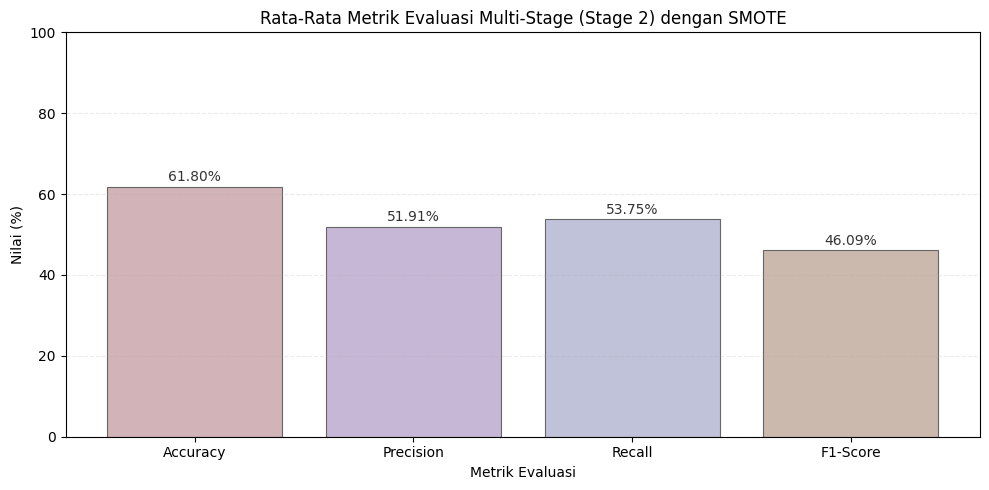

In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# AMBIL NILAI RATA-RATA KESELURUHAN
# ============================================================
avg_row = tabel_final[tabel_final["Aspek"] == "Rata-rata Keseluruhan"].iloc[0]

mean_acc = float(avg_row["Akurasi (%)"])
mean_prec = float(avg_row["Precision Macro"]) * 100
mean_rec  = float(avg_row["Recall Macro"]) * 100
mean_f1   = float(avg_row["F1 Macro"]) * 100

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values  = [mean_acc, mean_prec, mean_rec, mean_f1]

# ============================================================
# WARNA CEWEK – SOFT, POWDER, ELEGAN
# ============================================================
colors = [
    "#D1B3B8",  # soft blush grey
    "#C6B7D6",  # dusty lilac
    "#BFC2D9",  # powder lavender
    "#CBB9AE"   # warm nude taupe
]

# ============================================================
# GRAFIK BAR
# ============================================================
plt.figure(figsize=(10, 5))
bars = plt.bar(
    metrics,
    values,
    color=colors,
    edgecolor="#666666",
    linewidth=0.8
)

plt.ylim(0, 100)
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Nilai (%)")
plt.title("Rata-Rata Metrik Evaluasi Multi-Stage (Stage 2) dengan SMOTE")
plt.grid(axis="y", linestyle="--", alpha=0.25)

# Label nilai di atas batang
for bar, val in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{val:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#333333"
    )

plt.tight_layout()
plt.show()


**PERBANDINGAN SINGLESTAGE DAN MULTISTAGE**

=== RINGKASAN PERBANDINGAN (RATA-RATA) ===


,Metrik,Single-Stage SMOTE (%),Multi-Stage SMOTE (%)
0,Accuracy,58.75,61.80
1,Precision,28.49,51.91
2,Recall,25.50,53.75
3,F1-Score,26.50,46.09


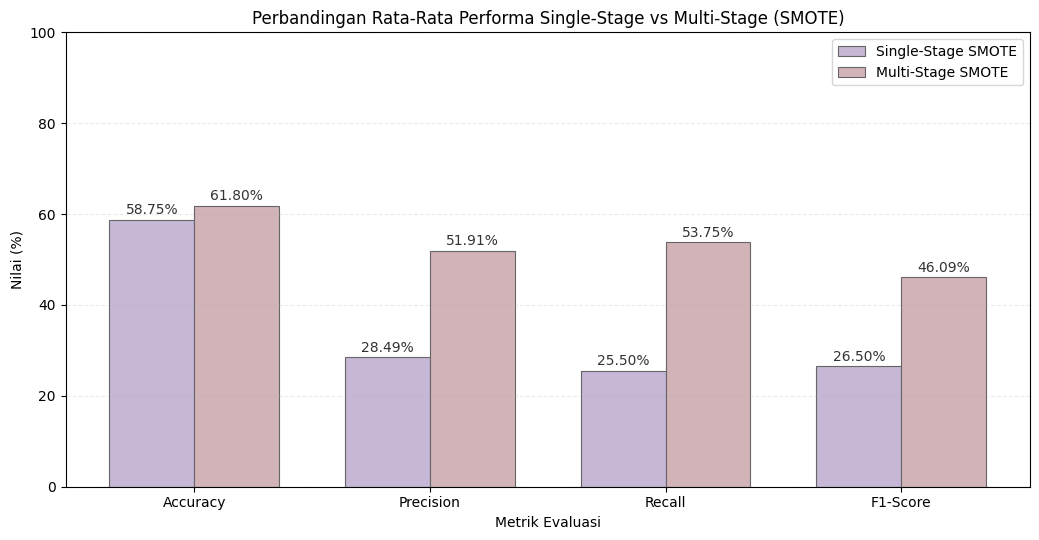

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1) AMBIL RATA-RATA SINGLE-STAGE SMOTE (dari df_hyper_single)
# ============================================================
single_acc  = float(df_hyper_single["acc_test"].mean())                 # sudah persen
single_prec = float(df_hyper_single["macro_precision"].mean()) * 100
single_rec  = float(df_hyper_single["macro_recall"].mean()) * 100
single_f1   = float(df_hyper_single["macro_f1"].mean()) * 100

# ============================================================
# 2) AMBIL RATA-RATA MULTI-STAGE SMOTE STAGE 2 (dari tabel_final)
# ============================================================
avg_row = tabel_final[tabel_final["Aspek"] == "Rata-rata Keseluruhan"].iloc[0]

multi_acc  = float(avg_row["Akurasi (%)"])                  # sudah persen
multi_prec = float(avg_row["Precision Macro"]) * 100
multi_rec  = float(avg_row["Recall Macro"]) * 100
multi_f1   = float(avg_row["F1 Macro"]) * 100

# ============================================================
# 3) BUAT DATA PERBANDINGAN (biar bisa dicek juga dalam tabel)
# ============================================================
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

df_compare = pd.DataFrame({
    "Metrik": metrics,
    "Single-Stage SMOTE (%)": [single_acc, single_prec, single_rec, single_f1],
    "Multi-Stage SMOTE (%)":  [multi_acc,  multi_prec,  multi_rec,  multi_f1]
})

print("=== RINGKASAN PERBANDINGAN (RATA-RATA) ===")
display(df_compare.style.format({
    "Single-Stage SMOTE (%)": "{:.2f}",
    "Multi-Stage SMOTE (%)": "{:.2f}"
}))

# ============================================================
# 4) GRAFIK GROUPED BAR CHART (SOFT FEMININE, ELEGAN)
# ============================================================
x = np.arange(len(metrics))
width = 0.36

# warna soft (tidak terang)
color_single = "#C6B7D6"  # dusty lilac
color_multi  = "#D1B3B8"  # soft blush grey

plt.figure(figsize=(10.5, 5.5))

bars1 = plt.bar(x - width/2, df_compare["Single-Stage SMOTE (%)"], width,
                label="Single-Stage SMOTE", color=color_single,
                edgecolor="#666666", linewidth=0.8)

bars2 = plt.bar(x + width/2, df_compare["Multi-Stage SMOTE (%)"], width,
                label="Multi-Stage SMOTE", color=color_multi,
                edgecolor="#666666", linewidth=0.8)

plt.ylim(0, 100)
plt.xticks(x, metrics)
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Nilai (%)")
plt.title("Perbandingan Rata-Rata Performa Single-Stage vs Multi-Stage (SMOTE)")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend()

# label angka di atas batang
def add_labels(bars):
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h + 0.6, f"{h:.2f}%",
                 ha="center", va="bottom", fontsize=10, color="#333333")

add_labels(bars1)
add_labels(bars2)

plt.tight_layout()
plt.show()
